# ステージ5-A: 全株プール DESeq2（eptA oligo metatranscriptome）

ステージ3（`4_reads.ipynb`、ゲート2 通過）の続き。**(A) 全株プール DESeq2** を実施する。

```
(A) 全株プール DESeq2   ← このnotebook（5_1_DESeq2_A_community）
(B) 株ごと独立 DESeq2   ← 次の 5_2_DESeq2_B_perstrain.ipynb
```

## (A) と (B) に主従はつけない。問いが違うので両方を対等に出す

| 観点 | **(A) 全株プール**（このnotebook） | **(B) 株ごと独立** |
|---|---|---|
| 問い | **宿主は何にさらされているか**（群集としての転写産物の組成） | **各菌が自分の中で何を上げ下げしたか** |
| size factor | ライブラリ全体で1組 | その株の中だけで各1組 |
| 株のシェア変化 | **含む** | **含まない** |

**最終成果物は、この2つを左右に並べた経路レベルの対比図**（ステージ6。CLAUDE.md §7 に仕様）。
**最も情報量が多いのは「片方のパネルでのみ有意」な経路。**

過去プロジェクト T19 の例: **PTS は (A) padj 1.1e-12 / (B) padj 0.10** —
実体は *Enterococcus hirae* のシェアが3倍になっただけ。
逆に **RNAポリメラーゼは (B) padj 6.3e-05 / (A) n.s.** — 菌量と無関係に各菌が増殖装置を絞っている。

## (A) の目的 — 宿主が何にさらされているか

**(A) の最終目的は、菌叢の遺伝子発現から「宿主にどのような作用をしているか」を考察すること。**

宿主が受け取るのは**菌叢全体が出している転写産物（とその産物）の総体**であって、
「菌1細胞あたりの発現量」ではない。したがって

```
   ある菌が増えた  →  その菌の転写産物が増える  →  宿主はそれに多くさらされる
```

**これは除くべき偏りではなく、(A) が捉えたい現象そのもの。**

| 変化の種類 | (A) に含まれるか |
|---|---|
| 菌の増減による転写産物量の変化 | **含む（＝測りたいもの）** |
| 菌1細胞あたりの発現制御の変化 | 含む |

**(A) はこの2つを分けない。** 分けるのが (B) との対比の役割。

### 株のシェア変化が (A) に与える大きさ

size factor をライブラリ全体で計算するので、**株のシェアが群間で動くと、
その株の全遺伝子が同じだけ上下する。**

| 株 | WT | KO | 全遺伝子が受ける変化 log2(KO/WT) |
|---|---|---|---|
| Bth 計 | 23.9% | 17.0% | **−0.49** |
| Bun_8492 | 72.4% | 79.7% | **+0.14** |
| Odo_St23 | 3.8% | 3.3% | **−0.18** |

（セル4 のフィルタ後の `minMQS=10` で実測）

**この数値は「(A) の結果から差し引くべき量」ではない。**
**「(A) で見える変化のうち、どれだけが菌叢構成の変化で説明できるか」の目安。**
(B) と突き合わせたとき、ある経路の (A) の変化がこの値とほぼ同じなら
**「菌量の入れ替わりで説明できる」**、大きく超えていれば**「制御も効いている」**と読める。

**★ このシェア変化自体が eptA 変異コンソーシアムの定着結果**（CLAUDE.md §1）。

### ★ (A) が答えられないこと: 絶対量

DESeq2 の正規化（median-of-ratios）は**検体ごとの総量をそろえる**ので、
(A) が測るのは**「宿主がさらされる転写産物の組成」**であって、**絶対量ではない。**

**菌叢全体の総量が群間で変わっていても (A) には写らない。**
絶対量まで言うには **spike-in か総菌量 qPCR が要る**（CLAUDE.md 付録 A-1 の 1・2）。
本実験にはどちらも無いので、**「組成がこう変わった」までにとどめる。**

### ★ 言ってはいけないこと: 「各菌が発現を上げた」

(A) の上昇を**「その菌が発現を上げた」と書いてはいけない。**
菌が増えただけの可能性があり、それを分けるのが (B)。
過去プロジェクト T19 の例: **PTS は (A) padj 1.1e-12 / (B) padj 0.10** で、
実体は *Enterococcus hirae* のシェアが3倍になったこと。
**「群集としての PTS 転写産物が3倍になった」は正しく、
「Enterococcus が PTS を上方制御した」は誤り。**

### 技術的な注意: (A) の dispersion は株ごとに偏る

DESeq2 は dispersion（ばらつき）の傾向線を**全遺伝子をまとめて1本**引くので、
ある株の本当のばらつきが傾向線とずれていると、収縮がその株だけ一方向に働く。
**どの株がどちらにずれるかはセル6 で実測する。** (B) では株の中で推定するので生じない。

## ステージ6 のために保存するもの

最終図（2パネル）に必要なので、このnotebook の最後で次を保存する。

| 保存するもの | 用途 |
|---|---|
| **遺伝子ごとの Wald 統計量** | パネルのスコア `2×(AUC−0.5)` の計算 |
| 遺伝子ごとの LFC・padj | 表・担い手の判定 |
| **群ごとの正規化カウント平均** | **担い手の順位＝正味リード増減**（遺伝子数ではない） |
| 遺伝子 → 株 / CPS座位 の対応 | 行の分解 |

## 過去notebook との対応

`240704_T19_28strains_genome_hifiasm_metatranscriptome/4_DESeq2_allmapped_fractionmode_normalized_R3.ipynb`
（260セル）の節立てに沿う。変更点は都度 markdown に書く。

| 過去 | 今回 | 理由 |
|---|---|---|
| `--fraction -M` の小数カウント → `round()` | **整数カウントをそのまま** | bowtie2 が `NH` を出さず `--fraction` が効かない（CLAUDE.md §7 ステージ3 の訂正） |
| `nbinomLRT`（尤度比検定） | **Wald + `lfcShrink(apeglm)`**、LRT も併記 | CLAUDE.md §7 ステージ5。apeglm の収縮に Wald 係数が要る。**Wald 統計量はステージ6 の図にも必要**。2群比較なので LRT とほぼ一致するはず |
| `EnhancedVolcano` | **ggplot2 で描く** | 2026-10-22 に導入済みだが、株ごとの facet・株での色分け・陽性対照のラベルを自分で制御したいので ggplot2 で描く |
| 全遺伝子をそのまま投入 | **CDS のみ + 遺伝子型マーカー除外 + mappability フィルタ** | CLAUDE.md §6-3・§7 申し送り2、§3 |

## 入力（CLAUDE.md §7 ステージ5 申し送り）

| 用途 | ファイル |
|---|---|
| **主解析** | `counts/featureCounts_q10.csv`（多重マップを捨てる。保守的） |
| 比較 | `counts/featureCounts_q0.csv` |
| 感度解析 | `salmon_quant/*/quant.sf` を tximport で |
| feature 属性 | `counts/feature_info.csv` |

## セル1: ライブラリ

ステージ5 は DESeq2 とその周辺だけで足りる。

**`.libPaths` は足さない。** `clusterProfiler` / `fgsea` は `metatx-lib-4.4` 側にあるが
それはステージ6 で読む。ここで足すと **ggplot2 が 3.5.1 → 3.5.2 に上がり、
ステージ3（`4_reads.ipynb`）の図と描画が変わる**ため。

In [5]:
# ステージ5 は DESeq2 とその周辺だけで足りる。
# clusterProfiler / fgsea は metatx-lib-4.4 側にあるが、それはステージ6 で読む。
#   → ここで .libPaths を足すと ggplot2 が 3.5.2 に上がり、
#     ステージ3（4_reads.ipynb）の図と描画が変わるので足さない
library(dplyr)
library(tidyverse)
suppressMessages(library(DESeq2))

# ★ DESeq2 を読み込むと dplyr の関数がいくつか隠される（4_reads.ipynb セル15-10-3 と同じ）。
#   count / first / rename / slice / setdiff / union などは dplyr:: を付けて呼ぶ
cat(sprintf("R %s / DESeq2 %s / apeglm %s / ggplot2 %s\n",
            getRversion(), packageVersion('DESeq2'),
            packageVersion('apeglm'), packageVersion('ggplot2')))

R 4.4.1 / DESeq2 1.46.0 / apeglm 1.28.0 / ggplot2 3.5.1


## セル2: パスを置く

ステージ3（`4_reads.ipynb` セル2）と同じ置き方にそろえる。

- 入力はステージ3 のセル15-12・16-8 が保存したもの
- 出力は `DESeq2/`（scratch 側）に置く

In [6]:
# ステージ3（4_reads.ipynb）と同じ置き方にそろえる

# 中間ファイル（大きい）は scratch 側
path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
# notebook と小さい表（git 管理側）
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'

# ステージ3 の出力（セル15-12・16-8 で保存したもの）
path_count  = file.path(path, 'counts')
path_salmon = file.path(path, 'salmon_quant')

# ステージ5 の出力先
path_de = file.path(path, 'DESeq2')
if (!dir.exists(path_de)) dir.create(path_de, recursive = TRUE)

# ステージ2 で作ったリファレンス（遺伝子の座標を引くのに使う。セル9・セル10）
path_gtf_count = file.path(path, 'ref/oligo_eptA_count.gtf')

# 入力ファイル（CLAUDE.md §7 ステージ5 申し送り1: 主解析は minMQS=10）
f_q10  = file.path(path_count, 'featureCounts_q10.csv')   # ★主解析
f_q0   = file.path(path_count, 'featureCounts_q0.csv')    # 比較用
f_feat = file.path(path_count, 'feature_info.csv')        # 株 / biotype / product

for (f in c(f_q10, f_q0, f_feat, path_salmon, path_gtf_count)) {
    cat(sprintf('%-78s %s\n', f,
                ifelse(file.exists(f) | dir.exists(f), 'OK', '!! 無い')))
}

/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/counts/featureCounts_q10.csv OK
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/counts/featureCounts_q0.csv OK
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/counts/feature_info.csv OK
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/salmon_quant OK
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ref/oligo_eptA_count.gtf OK


## セル3: カウント行列と feature 属性を読む

過去notebook（セル3-4）の「読んで `dim` と `colSums` を確認する」を踏襲する。

**出力はすべて data.frame にして返す**（Jupyter の R カーネルは
トップレベルの data.frame を HTML の表として描画する。`cat` / `print` は桁が崩れる）。

### 過去notebook との違い: `round()` しない

過去は `--fraction -M` の**小数カウント**だったので `round()` していたが、
**今回のカウントは整数**（`--fraction` が効かないため。CLAUDE.md §7 ステージ3 の訂正）。
それでも DESeq2 の要求に合わせて整数であることを `stopifnot` で確認する。

### 検体の並びを WT→KO にそろえる

CSV の列はアルファベット順（K が先）。**ステージ3 の表と同じ WT→KO** に並べ替えたうえで、
`group` の参照レベルを `WT` にする（**LFC は KO/WT の向き**で出る）。

In [7]:
# ── カウント行列と feature の属性を読む ─────────────────────────
# 過去notebook（4_DESeq2_allmapped_fractionmode_normalized_R3.ipynb セル3-4）と同じ
# 「読んで dim と colSums を確認する」を踏襲する。
#
# ★ ステージ3 と違い、今回のカウントは整数（featureCounts の素の値）。
#   過去notebookは --fraction -M の小数カウントだったので round() していたが、
#   今回は --fraction が効かないため（CLAUDE.md §7 ステージ3 の訂正）round は不要。
#   それでも DESeq2 の要求に合わせて整数であることを確認しておく

cnt_q10 = read.csv(f_q10,  header = TRUE, row.names = 1, check.names = FALSE)
cnt_q0  = read.csv(f_q0,   header = TRUE, row.names = 1, check.names = FALSE)
feat    = read.csv(f_feat, header = TRUE, stringsAsFactors = FALSE)

# 検体テーブル（W群6 / K群5。K5 は欠番）
#   ・WT を参照レベルにするので levels の先頭に置く（KO/WT の向きで LFC が出る）
#   ・CSV の列はアルファベット順（K が先）なので、ステージ3 の表と同じ WT→KO に並べ替える
ord     = order(factor(ifelse(grepl('W', colnames(cnt_q10)), 'WT', 'KO'),
                       levels = c('WT','KO')), colnames(cnt_q10))
cnt_q10 = cnt_q10[, ord]
cnt_q0  = cnt_q0[,  ord]

coldata = data.frame(
    sample = colnames(cnt_q10),
    group  = ifelse(grepl('W', colnames(cnt_q10)), 'WT', 'KO'),
    row.names = 'sample')
coldata$group = factor(coldata$group, levels = c('WT', 'KO'))

# 並びが一致していないと DESeq2 が黙って取り違えるので確認する
stopifnot(identical(rownames(coldata), colnames(cnt_q10)),
          identical(colnames(cnt_q10), colnames(cnt_q0)),
          all(cnt_q10 == round(cnt_q10)))

# ── 読み込んだものの一覧 ─────────────────────────────────────
cat("■ 表1: 読み込んだファイル\n")
data.frame(
    読んだもの = c('カウント行列 minMQS=10', 'カウント行列 minMQS=0', 'feature 属性'),
    行          = c(nrow(cnt_q10), nrow(cnt_q0), nrow(feat)),
    列          = c(ncol(cnt_q10), ncol(cnt_q0), ncol(feat)),
    中身        = c('★主解析', '比較用',
                    paste(colnames(feat), collapse = ' / ')),
    check.names = FALSE)

# ── 検体ごとの総カウント（過去notebook セル4 と同じ確認）──────────
cat("\n■ 表2: 検体ごとの総カウント（minMQS=10 が主解析、minMQS=0 は比較用）\n")
data.frame(
    検体 = colnames(cnt_q10),
    群    = as.character(coldata$group),
    q10_M = round(colSums(cnt_q10) / 1e6, 2),
    q0_M  = round(colSums(cnt_q0)  / 1e6, 2),
    row.names = NULL, check.names = FALSE)

# ── 低カウント遺伝子の数（prefilter の見当をつける）────────────────
cat("\n■ 表3: 低カウント遺伝子の数（セル4 の prefilter の見当をつける）\n")
data.frame(
    設定 = c('minMQS=10', 'minMQS=0'),
    `11検体合計が20リード未満の遺伝子` = c(sum(rowSums(cnt_q10) < 20), sum(rowSums(cnt_q0) < 20)),
    `全feature数` = nrow(cnt_q10),
    check.names = FALSE)

■ 表1: 読み込んだファイル


読んだもの,行,列,中身
<chr>,<int>,<int>,<chr>
カウント行列 minMQS=10,18245,11,★主解析
カウント行列 minMQS=0,18245,11,比較用
feature 属性,18245,5,gene_id / biotype / biotype2 / product / strain



■ 表2: 検体ごとの総カウント（minMQS=10 が主解析、minMQS=0 は比較用）


検体,群,q10_M,q0_M
<chr>,<chr>,<dbl>,<dbl>
eptAW1,WT,36.19,48.79
eptAW2,WT,32.27,45.38
eptAW3,WT,26.92,36.97
eptAW4,WT,30.85,45.86
eptAW5,WT,40.64,56.45
eptAW6,WT,28.70,37.61
eptAK1,KO,39.10,50.02
eptAK2,KO,31.28,38.41
eptAK3,KO,60.89,77.90



■ 表3: 低カウント遺伝子の数（セル4 の prefilter の見当をつける）


設定,11検体合計が20リード未満の遺伝子,全feature数
<chr>,<int>,<int>
minMQS=10,3851,18245
minMQS=0,1364,18245


## セル4: DE に入れる遺伝子を絞る

3段階で絞り、**各段階で何が何件落ちたか**を表に残す。

| 段階 | 内容 | 根拠 |
|---|---|---|
| **(1)** | **CDS のみ** | CLAUDE.md §6-3 |
| **(2)** | **mappability ≥ 0.5** | CLAUDE.md §3 |
| **(3)** | **prefilter**（最小群サイズ = KO の n=5 以上の検体で `count >= 10`） | CLAUDE.md §7 |

---

### (2) mappability とは何か

**「その遺伝子に当たったリードを、正しくその株のものだと判定できるか」の実測値**（ステージ2）。

測り方は、各 CDS から**擬似リードを作ってリファレンス全体に貼り直し、
自分の CDS に `MAPQ >= 10` で戻ってくる割合**を数えたもの。

| 値 | 意味 |
|---|---|
| **1.0** | 完全に判別できる。その遺伝子のカウントは信用してよい |
| **0.0** | **どの株由来か判定できない。** `minMQS=10` では全部捨てられる |

**なぜ Bth 2株だけ半分しか残らないのか**

`Bth_VPI` と `Bth_St8` は **ANI 98%、ゲノムの 96.8% が共通配列**（CLAUDE.md §3）。
共通領域の CDS は「VPI のものか St8 のものか」が決められない。

| 株 | mappability ≥ 0.5 の CDS | 割合 |
|---|---|---|
| Bth_VPI | 2,368 / 4,802 | **49.3%** |
| Bth_St8 | 2,336 / 4,795 | **48.7%** |
| Bun_8492 | 3,612 / 3,689 | 97.9% |
| Odo_St23 | 4,388 / 4,619 | 95.0% |

**外す理由**: 主解析は `minMQS=10`（MAPQ 10 未満を捨てる）なので、
mappability の低い遺伝子は**カウントの大半が削られた残りかす**になっている。
実測で、Bth 2株の CDS の残存率は中央値 43.0% / 39.4%、
**約1,100遺伝子はほぼ消滅（残存率 1% 未満）**（`4_reads.ipynb` セル15-11）。
**そういう遺伝子の発現量を比べても意味がない。**

分布は完全な二峰性なので、**閾値を 0.5 から動かしても結論は変わらない**（CLAUDE.md §3）。

**※ 落ちた Bth の遺伝子は Salmon の感度解析で拾い直す**（EM で按分するので捨てずに済む）。
ただし Salmon の index からは重複クラスタ737本が落ちており、
**そのうち504本が `Bth_VPI`** なので完全ではない（`4_reads.ipynb` セル16-5）。

---

### (3) prefilter とは何か

**低カウントすぎて検定しても意味がない遺伝子を、検定の前に落とすこと。**

落とす理由は2つ。

1. **多重検定の負担を減らす。** padj（BH法）は**検定した遺伝子数で割る**ので、
   絶対に有意にならない遺伝子を混ぜると**本当に動いている遺伝子の padj まで悪くなる。**
2. **dispersion の推定が安定する。** カウントがほぼ 0 の遺伝子はばらつきの推定が暴れる。

**基準**: `count >= 10` を**最小群サイズ以上の検体で**満たすこと。
今回は KO が n=5 なので **5検体以上**。
「片方の群の全検体で発現していれば残る」という意味になり、**片群特異的な遺伝子を捨てない。**

**※ `Odo_St23` はここで 4,388 → 2,851（65%）まで落ちる。**
シェアが 3.7% しかないので `count >= 10` に届かない遺伝子が多い。
**属をまたぐ収束（ステージ6）の検出力はここで決まる。**

---

### ★ eptA の遺伝子型マーカーは外さない。印を付けるだけにする

**前回「除外する」と書いたのは誤りでした。** CLAUDE.md §4 は
`_retained` を「**★ここで比較する。差が出れば本物の制御変化**」と明示的に指定しており、
`_deleted` も**解析が効いていることを示す陽性対照**になります。

| feature | 役割 |
|---|---|
| `_deleted` / `_3p` | **K群でゼロになるはずの領域** = 陽性対照 |
| `_retained` / `_5p` | **両群に共通する領域** = CLAUDE.md §4 が指定する比較対象 |

7件とも mappability 0.85〜1.00、prefilter も通過するので、**そのまま DE に入る。**

**ただし経路解析（ステージ6）には渡さない。**
eptA は **ko01503（CAMP耐性 = LPS修飾）** に属するので、
欠失そのものを入れると「**CAMP耐性が低下**」が自動的に有意になる。
これは**仮説（表層修飾の応答）と同じ経路**なので、**循環論法**になってしまう。
→ `feat$marker` 列で印を付け、**ステージ6 の入力を作るときに外す。**

**※ `_retained` の LFC は欠失境界の影響を受ける**（欠失をまたぐリードは K群で貼れない）。
`4_reads.ipynb` セル14-6 で補正した値（VPI 1.96〜2.38 / Bun 0.66〜1.90）があるので、
**DE の生の LFC をそのまま読まず、補正値と突き合わせる。**

---

### ★ 表3「一律シフト」の読み方

**(A) はライブラリ全体で正規化するので、株のシェアが群間で動くと、
その株の全遺伝子が同じだけ上下します。**

```
Bun のシェア: WT 72.4%  →  KO 79.7%
              log2(79.7 / 72.4) = +0.14
```

**これは (A) から差し引くべき偏りではありません。**
宿主が受け取るのは**菌叢全体が出している転写産物の総体**なので、
**菌が増えてその転写産物が増えたこと自体が、(A) が捉えたい現象です。**

表3 の値は、**菌叢構成がどう変わったかの記述**です。

**★ ただしこれは「各遺伝子に乗る量」そのものではありません。**
size factor（median-of-ratios）は**リード数ではなく遺伝子の中央値**で決まるので、
リードシェアからの予測は実測とずれます（`Bth` は予測 −0.49 に対し実測 −0.08〜−0.11）。
**各遺伝子が実際に受ける変化は セル7 の Table 4 `LFC_median_observed`** で確定させます。

| (A) の変化 | 読み方 |
|---|---|
| 一律シフトとほぼ同じ | **菌量の入れ替わりで説明できる** |
| 一律シフトを大きく超える | **菌1細胞あたりの制御も効いている** |

この切り分けを (B) との対比で正式に行います。

**※ mappability フィルタは Bth だけを削るのでシェア自体が動きます**（Bth 26.1% → 23.9%）。
だから最終的な値をここで確定させておきます。

---

### mappability の出どころ

ステージ2 の実測値（`mappability_full/cds_mappability.tsv`。project 側）。
**GTF の `mappability` 属性と同じもの**で、値が食い違うのは **eptA マーカー3件のみ**。

In [8]:
# ── DE に入れる遺伝子を絞る ─────────────────────────────────────
# 3段階で絞る。各段階で何が何件落ちたかを表に残す（後から根拠をたどれるように）。
#
#   (1) CDS のみ           CLAUDE.md §6-3。rRNA/tRNA/ncRNA は GTF に残して数えるが DE からは外す
#   (2) mappability >= 0.5 株を判別できないカウントを外す（CLAUDE.md §3）
#   (3) prefilter          最小群サイズ(KO n=5)以上の検体で count >= 10（CLAUDE.md §7）
#
# ★ eptA の遺伝子型マーカーは【外さずに残し、印を付けるだけ】にする。
#   CLAUDE.md §4 は _retained を「★ここで比較する」と指定しており、
#   _deleted も解析が効いていることを示す陽性対照になる。
#   ただし経路解析（ステージ6）には渡さない。eptA は ko01503（CAMP耐性）に属するので、
#   欠失そのものを入れると「CAMP耐性が低下」が自動的に有意になってしまう（循環論法）

# mappability はステージ2 の実測値（project 側の表。GTF の属性と同じもの）
mp_tbl = read.table(file.path(path_project, 'mappability_full/cds_mappability.tsv'),
                    header = TRUE, sep = "\t", stringsAsFactors = FALSE)
feat$mappability = mp_tbl$mappability[match(feat$gene_id, mp_tbl$gene)]

# 遺伝子型マーカーの印。経路解析から外すときにこの列を使う
feat$marker = grepl('_deleted$|_retained$|_3p$|_5p$', feat$gene_id)

n_ok = rowSums(cnt_q10[match(feat$gene_id, rownames(cnt_q10)), ] >= 10)
keep1 = feat$biotype == 'CDS'
keep2 = keep1 & !is.na(feat$mappability) & feat$mappability >= 0.5
keep3 = keep2 & n_ok >= 5

steps = list('(0) 全feature'    = rep(TRUE, nrow(feat)),
             '(1) CDSのみ'      = keep1,
             '(2) +mappability' = keep2,
             '(3) +prefilter'   = keep3)

# ── 表1: 残す遺伝子型マーカー（陽性対照。経路解析からのみ外す）──────
m_gm = cnt_q10[feat$gene_id[feat$marker], ]
tbl_marker = data.frame(
    gene_id     = feat$gene_id[feat$marker],
    株          = feat$strain[feat$marker],
    何を見ているか = ifelse(grepl('_deleted$|_3p$', feat$gene_id[feat$marker]),
                            'K群で失われる領域（陽性対照）',
                            '両群に共通する領域（CLAUDE.md §4 の比較対象）'),
    mappability = feat$mappability[feat$marker],
    WT平均      = round(rowMeans(m_gm[, coldata$group == 'WT'])),
    KO平均      = round(rowMeans(m_gm[, coldata$group == 'KO'])),
    最終入力に残る = feat$gene_id[feat$marker] %in% feat$gene_id[keep3],
    row.names = NULL, check.names = FALSE)
cat("■ 表1: eptA 遺伝子型マーカー（DE には残し、経路解析からのみ外す）\n")
tbl_marker

# ── 表2: 各段階で残る遺伝子数 ───────────────────────────────────
tbl_step = do.call(rbind, lapply(names(steps), function(k) {
    i = steps[[k]]
    data.frame(段階 = k,
               as.list(table(factor(feat$strain[i],
                   levels = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23','pME008')))),
               計 = sum(i), check.names = FALSE)
}))
cat("\n■ 表2: 各段階で残る遺伝子数（株ごと）\n")
tbl_step

# ── 表3: 各段階での株シェアと、(A) で株ごとに一律に乗る差 ──────────
# (A) はライブラリ全体で正規化するので、株のシェアが群間で動いていると
# 【その株の全遺伝子が同じだけ上下する】。これを「一律シフト」と呼ぶ。
#   例: Bun のシェアが WT 72.4% → KO 79.7% なら log2(79.7/72.4) = +0.14。
#       Bun のある遺伝子が菌体あたりまったく変化していなくても、(A) では +0.14 と出る。
# フィルタでシェア自体が動くので、最終的にいくつになるかをここで確定させる
m_all = cnt_q10[match(feat$gene_id, rownames(cnt_q10)), ]
is_wt = coldata$group == 'WT'
tbl_share = do.call(rbind, lapply(names(steps), function(k) {
    i = steps[[k]] & !is.na(feat$strain)
    a = sapply(colnames(m_all), function(s) tapply(m_all[i, s], feat$strain[i], sum))
    tot = colSums(a)
    do.call(rbind, lapply(list(`Bth計` = c('Bth_VPI','Bth_St8'),
                               Bun_8492 = 'Bun_8492', Odo_St23 = 'Odo_St23'),
        function(rows) {
            x = 100 * colSums(a[rows, , drop = FALSE]) / tot
            data.frame(段階 = k,
                       WT_シェアpct = round(mean(x[is_wt]), 1),
                       KO_シェアpct = round(mean(x[!is_wt]), 1),
                       `一律シフト_log2KO/WT` = round(log2(mean(x[!is_wt]) / mean(x[is_wt])), 2),
                       check.names = FALSE)
        })) %>% tibble::rownames_to_column('株')
}))
cat("\n■ 表3: 各段階での株シェアと、(A) でその株の全遺伝子が受ける変化\n")
cat("   （シェア = その株の遺伝子に当たったリードが全体に占める割合）\n")
tbl_share[, c('段階','株','WT_シェアpct','KO_シェアpct','一律シフト_log2KO/WT')]

# ── 最終的な入力を作る ──────────────────────────────────────────
feat_de = feat[keep3, ]
cnt_de  = cnt_q10[feat_de$gene_id, ]
stopifnot(identical(rownames(cnt_de), feat_de$gene_id),
          identical(colnames(cnt_de), rownames(coldata)))

# ── 表4: 最終的な入力 ───────────────────────────────────────────
cat("\n■ 表4: (A) に入れる最終的な行列\n")
data.frame(
    項目 = c('(A) に入れる遺伝子数', '検体数', '総カウント(M)',
             'minMQS=10 全体に対する割合(%)', 'うち遺伝子型マーカー(経路解析から外す)'),
    値   = c(format(nrow(cnt_de), big.mark = ','), ncol(cnt_de),
             sprintf('%.1f', sum(cnt_de) / 1e6),
             sprintf('%.1f', 100 * sum(cnt_de) / sum(cnt_q10)),
             sum(feat_de$marker)),
    check.names = FALSE)

■ 表1: eptA 遺伝子型マーカー（DE には残し、経路解析からのみ外す）


gene_id,株,何を見ているか,mappability,WT平均,KO平均,最終入力に残る
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>
CE91St8_20540_deleted,Bth_St8,K群で失われる領域（陽性対照）,0.9091,1851,0,TRUE
BT_RS09185_retained,Bth_VPI,両群に共通する領域（CLAUDE.md §4 の比較対象）,0.8511,619,233,TRUE
BT_RS09185_deleted,Bth_VPI,K群で失われる領域（陽性対照）,1.0000,273,0,TRUE
NQ510_RS14730_retained,Bun_8492,両群に共通する領域（CLAUDE.md §4 の比較対象）,1.0000,5315,2174,TRUE
NQ510_RS14730_deleted,Bun_8492,K群で失われる領域（陽性対照）,1.0000,4166,0,TRUE
CE91St23_40970_3p,Odo_St23,K群で失われる領域（陽性対照）,1.0000,162,0,TRUE
CE91St23_40970_5p,Odo_St23,両群に共通する領域（CLAUDE.md §4 の比較対象）,1.0000,62,51,TRUE



■ 表2: 各段階で残る遺伝子数（株ごと）


段階,Bth_VPI,Bth_St8,Bun_8492,Odo_St23,pME008,計
<chr>,<int>,<int>,<int>,<int>,<int>,<int>
(0) 全feature,4889,4882,3767,4690,17,18245
(1) CDSのみ,4802,4795,3689,4619,13,17918
(2) +mappability,2368,2336,3612,4388,13,12717
(3) +prefilter,1712,1830,3392,2851,10,9795



■ 表3: 各段階での株シェアと、(A) でその株の全遺伝子が受ける変化
   （シェア = その株の遺伝子に当たったリードが全体に占める割合）


段階,株,WT_シェアpct,KO_シェアpct,一律シフト_log2KO/WT
<chr>,<chr>,<dbl>,<dbl>,<dbl>
(0) 全feature,Bth計,18.5,12.8,-0.53
(0) 全feature,Bun_8492,78.3,84.3,0.11
(0) 全feature,Odo_St23,3.2,2.9,-0.15
(1) CDSのみ,Bth計,26.1,18.9,-0.46
(1) CDSのみ,Bun_8492,70.2,77.8,0.15
(1) CDSのみ,Odo_St23,3.7,3.3,-0.17
(2) +mappability,Bth計,23.9,17.0,-0.49
(2) +mappability,Bun_8492,72.3,79.6,0.14
(2) +mappability,Odo_St23,3.8,3.3,-0.18



■ 表4: (A) に入れる最終的な行列


項目,値
<chr>,<chr>
(A) に入れる遺伝子数,"9,795"
検体数,11
総カウント(M),262.2
minMQS=10 全体に対する割合(%),66.7
うち遺伝子型マーカー(経路解析から外す),7


## セル5: `DESeqDataSet` を作って size factor を求める

過去notebook（セル7-8・10-11）と同じ手順。

```
DESeqDataSetFromMatrix  →  参照レベル確認  →  model.matrix  →  estimateSizeFactors
```

### 守っている約束2つ

| CLAUDE.md | 内容 | このセルでの担保 |
|---|---|---|
| **§6-2** | **DESeq2 に入れるのは生カウントのみ。** 係数で割って `round()` してから渡さない | セル4 の `cnt_de` は featureCounts の素の整数カウント。何も割っていない |
| **§7 申し送り3** | **size factor は CDS のみで計算する**（rRNA・tRNA・ncRNA を含めない） | `cnt_de` は既に CDS のみ。この行列でそのまま計算すれば条件を満たす |

§6-2 は過去プロジェクトで**検定可能遺伝子の30%と DEG の40%を失った**原因なので、
ここは必ず素のカウントを渡す。

### 参照レベルを WT にする

**R の factor は既定でアルファベット順**（`KO` < `WT`）なので、
指定しないと **KO が基準**になって LFC の符号が逆になる。
`model.matrix` が `(Intercept)` と **`groupKO`** の2列になっていれば、
**LFC は「KO / WT」の向き**で出る。

### size factor（median-of-ratios）とは

**検体ごとの「深さ」の差を1つの係数に押し込んだもの。**
全遺伝子について「その検体の値 ÷ 全検体の幾何平均」を計算し、**その中央値**を取る。
中央値を使うので、**一部の遺伝子が大きく変動しても引きずられない。**

### 確認する3点

1. **最大/最小が5倍以内か**（ステージ3 セル15-8-2 と同じ基準）
   5倍を超えると、深い検体の低発現遺伝子と浅い検体の高発現遺伝子が同じ正規化値になり、
   **分散の推定が歪む。**
2. **群間で偏っていないか。** size factor 自体に群間差があると、
   正規化そのものが群の影響を受けていることになる。
3. **mappability フィルタで size factor が動いていないか。**
   動いていればフィルタが検体間の補正を変えてしまったことになる。
   比較用に**フィルタを掛けない CDS 全部でも計算して並べる。**

In [9]:
# ── DESeqDataSet を作って size factor を求める ─────────────────
# 過去notebook（セル7-8・10-11）と同じ手順。
#   DESeqDataSetFromMatrix → levels 確認 → model.matrix → estimateSizeFactors
#
# ★ CLAUDE.md §6-2「DESeq2 に入れるのは生カウントのみ」。
#   セル4 で作った cnt_de は featureCounts の素の整数カウント。何も割っていない。
# ★ CLAUDE.md §7 申し送り3「size factor は CDS のみで計算する」。
#   cnt_de は既に CDS のみなので、この行列でそのまま計算すれば条件を満たす。

dds = DESeqDataSetFromMatrix(countData = cnt_de,
                             colData   = coldata,
                             design    = ~ group)

# 参照レベルが WT であることを確認する（LFC が KO/WT の向きになる）。
# R の factor は既定でアルファベット順なので、指定しないと KO が基準になってしまう
dds$group = relevel(dds$group, ref = 'WT')

# 計画行列。2群比較なので「切片 + groupKO」の2列になるはず。
# groupKO 列が KO=1 / WT=0 なら、LFC は「KO / WT」の向きで出る
cat("■ 表1: 計画行列（design = ~ group）\n")
cat("   groupKO が KO=1 / WT=0 → LFC は log2(KO / WT) の向き\n")
as.data.frame(model.matrix(design(dds), data = colData(dds)))

# ── size factor（median-of-ratios）────────────────────────────
dds = estimateSizeFactors(dds)

# 比較用に、mappability フィルタを掛けない CDS 全部でも計算してみる。
# フィルタが size factor を動かしていないかの確認（動いていれば検体間の補正が変わる）
cds_all = cnt_q10[feat$gene_id[feat$biotype == 'CDS'], ]
sf_nofilt = estimateSizeFactors(
    DESeqDataSetFromMatrix(cds_all, coldata, ~ group))

tbl_sf = data.frame(
    検体                   = colnames(dds),
    群                     = as.character(coldata$group),
    `生カウント計(M)`      = round(colSums(counts(dds)) / 1e6, 2),
    `size factor`          = round(sizeFactors(dds), 3),
    `参考:フィルタ前のsize factor` = round(sizeFactors(sf_nofilt), 3),
    `正規化後の計(M)`      = round(colSums(counts(dds, normalized = TRUE)) / 1e6, 2),
    row.names = NULL, check.names = FALSE)

cat("\n■ 表2: 検体ごとの size factor\n")
cat("   生カウント計(M)  … セル4 で絞った 9,795 遺伝子の合計リード数\n")
cat("   size factor      … 本解析で使う値（この 9,795 遺伝子から計算）\n")
cat("   参考:フィルタ前   … mappability と prefilter を掛けない【CDS 17,918 全部】で計算した値。\n")
cat("                      本解析の値とほぼ同じなら、フィルタは検体間の補正を変えていない\n")
cat("   正規化後の計(M)  … 生カウント計 ÷ size factor\n")
tbl_sf

# ── size factor の確認（3点）──────────────────────────────────
#  1. 深さの差が大きすぎないか  目安は最大/最小が5倍以内（ステージ3 セル15-8-2 と同じ基準）。
#     5倍を超えると、深い検体の低発現遺伝子と浅い検体の高発現遺伝子が同じ正規化値になり
#     分散の推定が歪む
#  2. 正規化が群の影響を受けていないか  size factor 自体に群間差があると、
#     正規化そのものが群に依存していることになる
#  3. セル4 のフィルタが検体間の補正を変えていないか
sf    = sizeFactors(dds)
sf0   = sizeFactors(sf_nofilt)
is_wt = coldata$group == 'WT'
p_sf  = suppressWarnings(wilcox.test(sf[is_wt], sf[!is_wt])$p.value)

cat("\n■ 表3: size factor の確認（3点）\n")
rbind(
 data.frame(確認 = '1. 深さの差', 項目 = '最小',
            値 = sprintf('%.3f', min(sf)), 判定 = names(sf)[which.min(sf)]),
 data.frame(確認 = '1. 深さの差', 項目 = '最大',
            値 = sprintf('%.3f', max(sf)), 判定 = names(sf)[which.max(sf)]),
 data.frame(確認 = '1. 深さの差', 項目 = '最大 / 最小',
            値 = sprintf('%.2f 倍', max(sf)/min(sf)),
            判定 = ifelse(max(sf)/min(sf) < 5, 'OK（目安 5倍以内）', '!! 要検討')),
 data.frame(確認 = '2. 群間の偏り', 項目 = 'WT 平均',
            値 = sprintf('%.3f', mean(sf[is_wt])), 判定 = ''),
 data.frame(確認 = '2. 群間の偏り', 項目 = 'KO 平均',
            値 = sprintf('%.3f', mean(sf[!is_wt])), 判定 = ''),
 data.frame(確認 = '2. 群間の偏り', 項目 = 'Wilcoxon p',
            値 = sprintf('%.4f', p_sf),
            判定 = ifelse(p_sf >= 0.05, 'OK（群に依存していない）', '!! 要検討')),
 data.frame(確認 = '3. フィルタの影響', 項目 = 'フィルタ前との最大のずれ',
            値 = sprintf('%.3f', max(abs(sf - sf0))),
            判定 = ifelse(max(abs(sf - sf0)) < 0.2,
                          'OK（検体間の補正は変わっていない）', '!! 要検討')))

■ 表1: 計画行列（design = ~ group）
   groupKO が KO=1 / WT=0 → LFC は log2(KO / WT) の向き


,(Intercept),groupKO
,<dbl>,<dbl>
eptAW1,1,0
eptAW2,1,0
eptAW3,1,0
eptAW4,1,0
eptAW5,1,0
eptAW6,1,0
eptAK1,1,1
eptAK2,1,1
eptAK3,1,1



■ 表2: 検体ごとの size factor
   生カウント計(M)  … セル4 で絞った 9,795 遺伝子の合計リード数
   size factor      … 本解析で使う値（この 9,795 遺伝子から計算）
   参考:フィルタ前   … mappability と prefilter を掛けない【CDS 17,918 全部】で計算した値。
                      本解析の値とほぼ同じなら、フィルタは検体間の補正を変えていない
   正規化後の計(M)  … 生カウント計 ÷ size factor


検体,群,生カウント計(M),size factor,参考:フィルタ前のsize factor,正規化後の計(M)
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,25.33,0.934,0.930,27.11
eptAW2,WT,21.95,0.830,0.835,26.47
eptAW3,WT,19.07,0.747,0.742,25.54
eptAW4,WT,21.93,0.966,1.045,22.70
eptAW5,WT,27.79,1.114,1.134,24.95
eptAW6,WT,16.23,0.658,0.651,24.68
eptAK1,KO,23.07,0.823,0.796,28.05
eptAK2,KO,18.16,0.912,0.892,19.90
eptAK3,KO,42.89,2.357,2.357,18.20



■ 表3: size factor の確認（3点）


確認,項目,値,判定
<chr>,<chr>,<chr>,<chr>
1. 深さの差,最小,0.658,eptAW6
1. 深さの差,最大,2.357,eptAK3
1. 深さの差,最大 / 最小,3.58 倍,OK（目安 5倍以内）
2. 群間の偏り,WT 平均,0.875,
2. 群間の偏り,KO 平均,1.296,
2. 群間の偏り,Wilcoxon p,0.2468,OK（群に依存していない）
3. フィルタの影響,フィルタ前との最大のずれ,0.079,OK（検体間の補正は変わっていない）


## セル6: dispersion（ばらつき）を推定する

過去notebook（セル12）と同じ `estimateDispersions`。

### DESeq2 は3段階でばらつきを決める

|- | 中身 | 性格 |
|---|---|---|
| **(1) 実測**<br>`dispGeneEst` | その遺伝子の11検体だけから推定した値 | **不安定**（n=11 では推定誤差が大きい） |
| **(2) 傾向線**<br>`dispFit` | **全遺伝子**から「平均発現量 → ばらつき」の関係を当てはめた線 | 安定だが、個々の遺伝子の事情は反映しない |
| **(3) 最終**<br>`dispersions` | (1) を (2) に向かって収縮させた値 | **これが検定に使われる** |

(1) 単独では誤差が大きく、(2) 単独では個々の遺伝子を無視することになるので、
**両者の折衷を取る**のが DESeq2 の設計。

### ★ ここで確かめること: 傾向線が株ごとに合っているか

**(2) の傾向線は「全遺伝子をまとめて1本」引く。これが (A) 全株プールの性質。**
ある株の本当のばらつきが傾向線とずれていると、(3) の収縮がその株だけ一方向に働く。

| ずれの向き | 収縮の向き | 検定への影響 |
|---|---|---|
| 実測 **>** 傾向線 | **下げられる** | **p 値が出やすくなる**（偽陽性側） |
| 実測 **<** 傾向線 | **上げられる** | **p 値が出にくくなる**（保守的・検出力を失う） |

CLAUDE.md §7 ステージ5 は「**低存在量株（`Odo_St23` 3.8%）の dispersion が
高存在量株（`Bun_8492` 72.4%）に引っ張られて過小評価されうる**」と警告していた。
**本当にそうなっているかを、ここで実測して確かめる。**

### 表2 の「50%」は期待値ではない

`dispGeneEst` の分布は**右に裾を引く**ので、中央値が傾向線より下に来るのは
**全株に共通して起こる**（実測でも全体 32.9%）。
**意味があるのは株どうしの比較**で、全体より高い株・低い株がどれかを見る。

In [10]:
# ── dispersion（ばらつき）を推定する ───────────────────────────
# 過去notebook（セル12）と同じ estimateDispersions。
#
# DESeq2 は遺伝子ごとのばらつきを3段階で決める。
#   (1) 遺伝子ごとの実測値（dispGeneEst）… 11検体だけから推定するので不安定
#   (2) 全遺伝子から引いた傾向線（dispFit）… baseMean の関数として当てはめる
#   (3) (1) を (2) に向かって収縮させた最終値（dispersions）… 実際の検定に使う
#
# ★ CLAUDE.md §7 ステージ5 が警告している点をここで実測する。
#   (2) の傾向線は【全遺伝子から引く】ので、(A) では遺伝子数・存在量の大きい株
#   （Bun_8492 72.4%）に引っ張られる。低存在量株（Odo_St23 3.8%）の本当のばらつきが
#   傾向線より大きいと、(3) で小さい方へ収縮され、p 値が出やすくなる（偽陽性側）。
#   → 株ごとに (1) と (2) のずれを見れば、その危険があるかが分かる

dds = estimateDispersions(dds)

disp = data.frame(
    gene_id  = rownames(dds),
    株       = feat_de$strain,
    baseMean = mcols(dds)$baseMean,
    実測     = mcols(dds)$dispGeneEst,   # (1) 遺伝子ごとの実測値
    傾向線   = mcols(dds)$dispFit,       # (2) 全遺伝子から引いた傾向線
    最終     = dispersions(dds))         # (3) 検定に使う値

# 実測が NA（カウントが低すぎて推定できない）の遺伝子は除いて集計する
d_ok = disp %>% filter(!is.na(実測), 実測 > 1e-8, !is.na(傾向線))

cat("■ 表1: 株ごとの dispersion（実測が得られた遺伝子のみ）\n")
cat("   実測/傾向線 … 1 より大きい = その株は傾向線より実際にばらつきが大きい\n")
cat("   収縮率       … 最終/実測。1 より小さい = 傾向線に向けて下げられた\n")
d_ok %>%
    group_by(株) %>%
    summarise(遺伝子数 = dplyr::n(),
              baseMean中央値 = round(median(baseMean)),
              実測_中央値   = round(median(実測), 4),
              傾向線_中央値 = round(median(傾向線), 4),
              最終_中央値   = round(median(最終), 4),
              `実測/傾向線` = round(median(実測 / 傾向線), 2),
              収縮率        = round(median(最終 / 実測), 2),
              .groups = 'drop') %>%
    as.data.frame()

# ── 傾向線に対する位置を株どうしで比べる ───────────────────────
# ★ 「50%」が期待値ではない。dispGeneEst の分布は右に裾を引くので、
#   中央値が傾向線より下に来るのは全株に共通して起こる。
#   意味があるのは【株どうしの比較】。ある株だけ他より高ければ、
#   その株は傾向線より実際にばらつきが大きいということ
ov = 100 * mean(d_ok$実測 > d_ok$傾向線)

cat(sprintf("\n■ 表2: 実測が傾向線より上にある遺伝子の割合（全体 %.1f%% との比較）\n", ov))
cat("   全体より高い = その株は傾向線より実際にばらつきが大きい\n")
cat("              → 収縮で下げられる（p 値が出やすくなる側）\n")
cat("   全体より低い = 傾向線より実際のばらつきが小さい\n")
cat("              → 収縮で上げられる（p 値が出にくくなる側＝保守的）\n")
d_ok %>%
    group_by(株) %>%
    summarise(遺伝子数 = dplyr::n(),
              `傾向線より上_pct` = round(100 * mean(実測 > 傾向線), 1),
              `全体との差_pt`    = round(100 * mean(実測 > 傾向線) - ov, 1),
              向き = ifelse(100 * mean(実測 > 傾向線) > ov,
                            '収縮で下げられる（p が出やすい）',
                            '収縮で上げられる（保守的）'),
              .groups = 'drop') %>%
    as.data.frame()

cat("\n■ 表3: 実測が得られなかった遺伝子（outlier 置換・低カウント）\n")
data.frame(
    項目 = c('全遺伝子', '実測が得られた', '実測が NA または 0'),
    数   = c(nrow(disp), nrow(d_ok), nrow(disp) - nrow(d_ok)),
    check.names = FALSE)

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



■ 表1: 株ごとの dispersion（実測が得られた遺伝子のみ）
   実測/傾向線 … 1 より大きい = その株は傾向線より実際にばらつきが大きい
   収縮率       … 最終/実測。1 より小さい = 傾向線に向けて下げられた


株,遺伝子数,baseMean中央値,実測_中央値,傾向線_中央値,最終_中央値,実測/傾向線,収縮率
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Bth_St8,1812,147,0.1460,0.1465,0.1513,0.97,1.02
Bth_VPI,1656,109,0.1085,0.1484,0.1275,0.71,1.12
Bun_8492,3389,836,0.0883,0.1423,0.1030,0.61,1.16
Odo_St23,2710,85,0.0880,0.1504,0.1124,0.57,1.22
pME008,10,110,0.0915,0.1484,0.1031,0.63,1.15



■ 表2: 実測が傾向線より上にある遺伝子の割合（全体 32.9% との比較）
   全体より高い = その株は傾向線より実際にばらつきが大きい
              → 収縮で下げられる（p 値が出やすくなる側）
   全体より低い = 傾向線より実際のばらつきが小さい
              → 収縮で上げられる（p 値が出にくくなる側＝保守的）


株,遺伝子数,傾向線より上_pct,全体との差_pt,向き
<chr>,<int>,<dbl>,<dbl>,<chr>
Bth_St8,1812,48.6,15.7,収縮で下げられる（p が出やすい）
Bth_VPI,1656,35.0,2.1,収縮で下げられる（p が出やすい）
Bun_8492,3389,31.1,-1.7,収縮で上げられる（保守的）
Odo_St23,2710,23.2,-9.6,収縮で上げられる（保守的）
pME008,10,30.0,-2.9,収縮で上げられる（保守的）



■ 表3: 実測が得られなかった遺伝子（outlier 置換・低カウント）


項目,数
<chr>,<int>
全遺伝子,9795
実測が得られた,9577
実測が NA または 0,218


## セル6図: dispersion を図にする

**図1** は DESeq2 標準の `plotDispEsts` と同じ形だが、**株ごとに分けて**描く。
**図2** は実測が傾向線の何倍かを株ごとに箱ひげで見る（図1 では点が重なって差が見えないため）。

図2 の **0 の線**が傾向線。箱が 0 より下に寄っている株ほど、**検定で使う値が実測より大きくなり、保守的になる。**


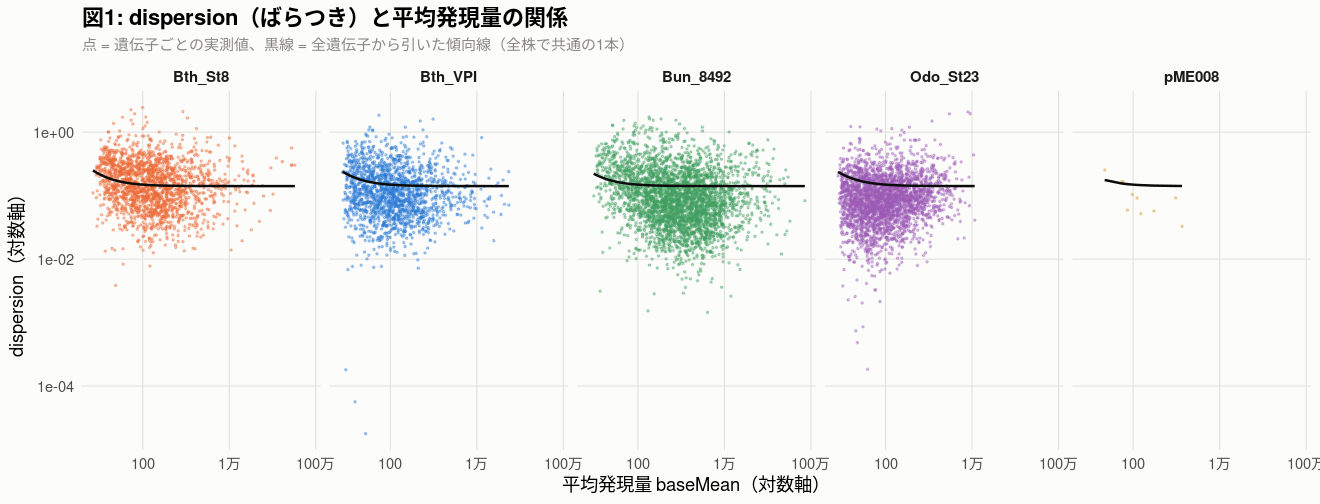

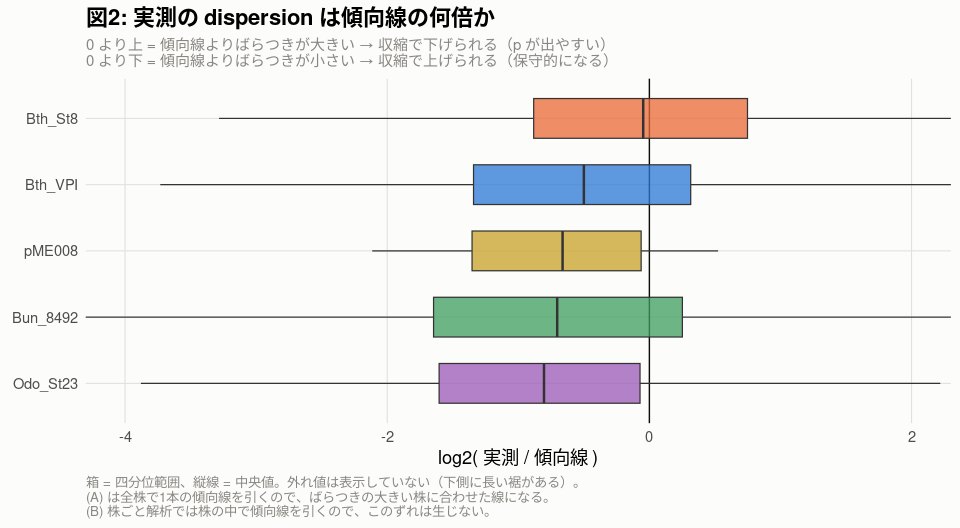

In [11]:
# ── dispersion を図にする ──────────────────────────────────────
# 図1: DESeq2 標準の plotDispEsts と同じ形。ただし【株ごとに分けて】描く
# 図2: 実測が傾向線の何倍かを株ごとに箱ひげで見る（図1 では差が見えにくいため）
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_strain = c(Bth_VPI = '#2a78d6', Bth_St8 = '#eb6834', Bun_8492 = '#3f9e5f',
               Odo_St23 = '#9b59b6', pME008 = '#c9a227')
thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

options(repr.plot.width = 11, repr.plot.height = 4.2)

p1 = ggplot(d_ok, aes(x = baseMean, y = 実測)) +
    geom_point(aes(colour = 株), size = 0.35, alpha = 0.35) +
    geom_line(aes(y = 傾向線), colour = col_text, linewidth = 0.7) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6),
                  labels = c('1', '100', '1万', '100万')) +
    scale_y_log10() +
    scale_colour_manual(values = col_strain) +
    facet_wrap(~ 株, nrow = 1) + guides(colour = 'none') +
    labs(title = '図1: dispersion（ばらつき）と平均発現量の関係',
         subtitle = '点 = 遺伝子ごとの実測値、黒線 = 全遺伝子から引いた傾向線（全株で共通の1本）',
         x = '平均発現量 baseMean（対数軸）', y = 'dispersion（対数軸）') + thm
suppressWarnings(print(p1))

options(repr.plot.width = 8, repr.plot.height = 4.4)

p2 = ggplot(d_ok, aes(x = reorder(株, 実測 / 傾向線, median),
                      y = log2(実測 / 傾向線), fill = 株)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_boxplot(outlier.shape = NA, linewidth = 0.35, width = 0.6, alpha = 0.75) +
    scale_fill_manual(values = col_strain) + guides(fill = 'none') +
    # 下側に長い裾があり、そのままだと肝心の 0 付近が潰れるので範囲を切る
    coord_flip(ylim = c(-4, 2)) +
    labs(title = '図2: 実測の dispersion は傾向線の何倍か',
         subtitle = paste0('0 より上 = 傾向線よりばらつきが大きい → 収縮で下げられる（p が出やすい）\n',
                           '0 より下 = 傾向線よりばらつきが小さい → 収縮で上げられる（保守的になる）'),
         x = NULL, y = 'log2( 実測 / 傾向線 )',
         caption = paste0('箱 = 四分位範囲、縦線 = 中央値。外れ値は表示していない（下側に長い裾がある）。\n',
                          '(A) は全株で1本の傾向線を引くので、ばらつきの大きい株に合わせた線になる。\n',
                          '(B) 株ごと解析では株の中で傾向線を引くので、このずれは生じない。')) + thm
suppressWarnings(print(p2))

## セル7: Wald 検定 → LFC の収縮 → LRT との突き合わせ

### 過去notebook は LRT だった。今回は Wald を主にする

|- | 過去notebook（セル13） | 今回 |
|---|---|---|
| 検定 | `nbinomLRT`（尤度比検定） | **`nbinomWaldTest`**（LRT も併記して照合） |
| LFC | 生の値 | **`lfcShrink(type="apeglm")` で収縮** |

**理由は2つ。**

1. **CLAUDE.md §7 ステージ5 が `lfcShrink(type="apeglm")` を指定**しており、
   apeglm の収縮には **Wald の係数と標準誤差**が要る
2. **ステージ6 の2パネル図は「Wald 統計量の符号付きランク」でスコアを作る。**
   LRT の統計量は**符号を持たない**のでスコアが作れない

2群比較なので **Wald と LRT はほぼ一致するはず**。表5 で確かめる。

### `lfcShrink` とは何か

**生の LFC（`log2FoldChange`）は最尤推定値で、カウントが少ない遺伝子では推定が暴れる。**

```
   2 リード → 20 リード      LFC = +3.3   ← 偶然でも起こりうる
1000 リード → 10000 リード    LFC = +3.3   ← まず偶然では起こらない
```

**生の LFC は両者を区別しない。** だから生の LFC でランク付けすると、
**上位が低カウントのノイズ遺伝子で埋まる。**

`lfcShrink` は**全遺伝子の LFC 分布を事前分布として使い、
情報の少ない遺伝子だけを 0 に向けて縮める**（ベイズ的な縮小推定）。

|- | 収縮の効き方 |
|---|---|
| カウントが多い / ばらつきが小さい | **ほとんど動かない** |
| カウントが少ない / ばらつきが大きい | **強く 0 に縮む** |

**実測（表2）**: `baseMean` < 10 の遺伝子は `|LFC|` の中央値が **35.4% 縮む**のに対し、
`baseMean` 1,000〜1万 では **14.1%** しか縮まない。

#### ★ p 値は変わらない

収縮は **`log2FoldChange` と `lfcSE` だけ**に効く。
`pvalue` / `padj` は収縮前と**完全に同一**（このnotebook で確認済み）。
**「有意かどうか」は変わらず、「どれだけ動いたか」の推定値だけが直る。**

→ **FC でランク付けする箇所は必ず収縮後を使う**（CLAUDE.md §7 ステージ5）。
MA プロットや火山図の横軸も収縮後にする。

#### なぜ `apeglm` を選ぶのか

DESeq2 には `normal` / `apeglm` / `ashr` の3つがある。
**`apeglm` は裾の重い（Cauchy 型の）事前分布**を使うので、
**本当に大きな変化は縮めすぎない。** 古い `normal` は大きな効果まで縮めてしまう。

実際、`_deleted` マーカー（K群でゼロ）は **LFC −14.6 / −13.2 のまま残っている**（表6）。

**※ 片群がゼロの遺伝子は LFC が原理的に定まらない**（log(0) は −∞）ので、
`_deleted` の −12〜−15 という値は**「極端に低い」以上の意味を持たない。**
（生 −10.98 → 収縮後 −13.16 と**より極端になる**こともある）

### ★ 表4 — セル4 の「一律シフト」予測は当たらない

セル4 では**リードのシェア**からシフトを予測したが、**実測とずれる。**

**理由: size factor（median-of-ratios）は「リード数」ではなく「遺伝子の中央値」で決まる。**
株ごとに**遺伝子数の割合とリード数の割合が大きく違う**ので、リードシェアからの予測は当たらない。

| 株 | 遺伝子数の割合 | リード数の割合 |
|---|---|---|
| `Bun_8492` | 34.6% | **75.8%** |
| `Odo_St23` | 29.1% | **3.5%** |
| `Bth_VPI` | 17.5% | **5.5%** |

**正規化の基準になるのは「真ん中の遺伝子」**なので、
リード数は少ないが遺伝子数の多い `Odo_St23`・`Bth_VPI` が正規化に強く効く。

→ **その株の典型的な遺伝子が (A) で受ける変化は、表4 の `LFC_median_observed` の方。**
セル4 の値は**菌叢構成がどう変わったかの記述**として読み、
**(A) の LFC を解釈する基準としては表4 を使う。**

### 表6 — eptA 遺伝子型マーカーは陽性対照

**`_deleted` / `_3p` が強く低下していれば、解析が最後まで正しく動いている証拠。**

**※ `_retained` の LFC は欠失境界の影響を含む**（欠失をまたぐリードは K群で貼れない）。
`4_reads.ipynb` セル14-6 の補正値（VPI 1.96〜2.38倍 / Bun 0.66〜1.90倍の低下）と
突き合わせて読むこと。

### 表の列名を英語にする

**ここから先の表は列名を英語にする。** `de`（1遺伝子1行の表）は
**ステージ6 の2パネル図の元データとしてそのまま渡す**ので、
`gene_id` / `strain` / `LFC_shrunk` / `stat_Wald` のように英語で統一しておく。

In [12]:
# ── Wald 検定 → LFC の収縮 → LRT との突き合わせ ─────────────────
# 過去notebook（セル13-15）は nbinomLRT（尤度比検定）だった。今回は Wald を主にする。
#   理由1: CLAUDE.md §7 ステージ5 が lfcShrink(type="apeglm") を指定しており、
#          apeglm の収縮には Wald の係数と標準誤差が要る
#   理由2: ステージ6 の2パネル図は【Wald 統計量の符号付きランク】でスコアを作る。
#          LRT の統計量は符号を持たないのでスコアが作れない
#   2群比較なので Wald と LRT はほぼ一致するはず。それも確かめる
#
# ★ ここから先の表は列名を英語にする（ステージ6 へそのまま渡すため）

dds = nbinomWaldTest(dds)
resultsNames(dds)          # 収縮に渡す係数名を確認する

# ── 生の結果（収縮前）────────────────────────────────────────
res = results(dds, alpha = 0.05)

# ── LFC を収縮させる（apeglm）──────────────────────────────────
# カウントが少ない遺伝子は LFC の推定が暴れる（2→20 も 1000→10000 も同じ LFC だが
# 前者は偶然で動きうる）。apeglm は全遺伝子の LFC 分布を事前分布に使い、
# 情報の少ない遺伝子だけを 0 に向けて縮める。
#   ・カウントが多い遺伝子はほとんど動かない
#   ・p 値と padj は変わらない（収縮は LFC の推定値にだけ効く）
#   ★ FC でランク付けする箇所は必ず収縮後を使う（CLAUDE.md §7 ステージ5）
res_shr = lfcShrink(dds, coef = 'group_KO_vs_WT', type = 'apeglm', quiet = TRUE)

# ── LRT（過去notebook の方法）でも検定して突き合わせる ──────────
dds_lrt = nbinomLRT(dds, full = ~ group, reduced = ~ 1, quiet = TRUE)
res_lrt = results(dds_lrt, alpha = 0.05)

# ── 1遺伝子1行の表にまとめる（これ以降・ステージ6 の元データ）───────
de = data.frame(
    gene_id    = rownames(res),
    strain     = feat_de$strain,
    product    = feat_de$product,
    marker     = feat_de$marker,            # eptA 遺伝子型マーカー（経路解析から外す印）
    baseMean   = round(res$baseMean, 1),
    LFC_raw    = round(res$log2FoldChange, 4),     # 収縮前（MLE）
    LFC_shrunk = round(res_shr$log2FoldChange, 4), # apeglm。図とランク付けはこちら
    lfcSE      = round(res_shr$lfcSE, 4),
    stat_Wald  = round(res$stat, 4),        # ★ステージ6 の経路スコアに使う
    pvalue     = res$pvalue,
    padj       = res$padj,
    pvalue_LRT = res_lrt$pvalue,
    padj_LRT   = res_lrt$padj,
    row.names  = NULL)

sig = !is.na(de$padj) & de$padj < 0.05

cat("■ Table 1: 検定結果の全体像（padj < 0.05）\n")
data.frame(
    item = c('genes tested (input)', 'padj = NA (independent filtering)',
             'genes with padj', 'DEG (padj < 0.05)',
             'DEG up in KO', 'DEG down in KO'),
    n    = c(nrow(de), sum(is.na(de$padj)), sum(!is.na(de$padj)), sum(sig),
             sum(sig & de$LFC_shrunk > 0), sum(sig & de$LFC_shrunk < 0)),
    check.names = FALSE)

# ── 収縮がどれだけ効いたか ─────────────────────────────────────
# baseMean（平均発現量）が小さいほど強く縮むことを確認する
cat("\n■ Table 2: lfcShrink の効き方（baseMean 帯ごと）\n")
cat("   情報の少ない遺伝子（baseMean が小さい）ほど強く 0 に向けて縮む\n")
de %>% filter(!is.na(LFC_raw)) %>%
    mutate(baseMean_bin = cut(baseMean, c(0, 10, 100, 1000, 1e4, Inf),
                              labels = c('<10','10-100','100-1k','1k-10k','>10k'))) %>%
    group_by(baseMean_bin) %>%
    summarise(n = dplyr::n(),
              median_absLFC_raw    = round(median(abs(LFC_raw)), 3),
              median_absLFC_shrunk = round(median(abs(LFC_shrunk)), 3),
              shrunk_pct = round(100 * (1 - median(abs(LFC_shrunk)) /
                                        median(abs(LFC_raw))), 1),
              .groups = 'drop') %>% as.data.frame()

cat("\n■ Table 3: 株ごとの DEG 数\n")
de %>% group_by(strain) %>%
    summarise(tested = sum(!is.na(padj)),
              DEG     = sum(!is.na(padj) & padj < 0.05),
              DEG_pct = round(100 * sum(!is.na(padj) & padj < 0.05) /
                              sum(!is.na(padj)), 1),
              up   = sum(!is.na(padj) & padj < 0.05 & LFC_shrunk > 0),
              down = sum(!is.na(padj) & padj < 0.05 & LFC_shrunk < 0),
              LFC_median_all = round(median(LFC_shrunk, na.rm = TRUE), 3),
              .groups = 'drop') %>% as.data.frame()

# ── ★ セル4 の「一律シフト」予測と実測を突き合わせる ──────────────
# ずれる理由: size factor（median-of-ratios）は【リード数】ではなく
# 【遺伝子の中央値】で決まる。株ごとに「遺伝子数の割合」と「リード数の割合」が
# 大きく違うので、リードシェアからの予測は当たらない
pred = c(Bth_St8 = -0.49, Bth_VPI = -0.49, Bun_8492 = 0.14, Odo_St23 = -0.18)
ng = table(feat_de$strain)
nr = tapply(rowSums(cnt_de), feat_de$strain, sum)

cat("\n■ Table 4: セル4 のシェア由来の予測と、実測の LFC 中央値\n")
cat("   LFC_median_observed … その株の典型的な遺伝子が (A) で受ける変化。こちらが本当の値\n")
data.frame(
    strain          = names(pred),
    genes_pct       = round(100 * as.integer(ng[names(pred)]) / sum(ng), 1),
    reads_pct       = round(100 * as.numeric(nr[names(pred)]) / sum(nr), 1),
    predicted_cell4 = pred[names(pred)],
    LFC_median_observed = round(tapply(de$LFC_shrunk, de$strain, median,
                                       na.rm = TRUE)[names(pred)], 3),
    row.names = NULL, check.names = FALSE)

cat("\n■ Table 5: Wald と LRT の一致（2群比較なのでほぼ一致するはず）\n")
ok = !is.na(de$padj) & !is.na(de$padj_LRT)
data.frame(
    item  = c('tested by both', 'DEG by Wald', 'DEG by LRT', 'DEG by both',
              'DEG by Wald only', 'DEG by LRT only', 'Spearman r of p-values'),
    value = c(sum(ok), sum(ok & de$padj < 0.05), sum(ok & de$padj_LRT < 0.05),
              sum(ok & de$padj < 0.05 & de$padj_LRT < 0.05),
              sum(ok & de$padj < 0.05 & de$padj_LRT >= 0.05),
              sum(ok & de$padj >= 0.05 & de$padj_LRT < 0.05),
              round(cor(de$pvalue[ok], de$pvalue_LRT[ok], method = 'spearman'), 4)),
    check.names = FALSE)

cat("\n■ Table 6: eptA 遺伝子型マーカー（陽性対照。_deleted が強く低下していれば解析は正常）\n")
de %>% filter(marker) %>%
    dplyr::select(gene_id, strain, baseMean, LFC_raw, LFC_shrunk, padj) %>%
    mutate(baseMean = round(baseMean), LFC_raw = round(LFC_raw, 2),
           LFC_shrunk = round(LFC_shrunk, 2), padj = signif(padj, 3)) %>%
    arrange(LFC_shrunk) %>% as.data.frame()

[1] "Intercept"      "group_KO_vs_WT"

■ Table 1: 検定結果の全体像（padj < 0.05）


item,n
<chr>,<int>
genes tested (input),9795
padj = NA (independent filtering),159
genes with padj,9636
DEG (padj < 0.05),3126
DEG up in KO,1616
DEG down in KO,1510



■ Table 2: lfcShrink の効き方（baseMean 帯ごと）
   情報の少ない遺伝子（baseMean が小さい）ほど強く 0 に向けて縮む


baseMean_bin,n,median_absLFC_raw,median_absLFC_shrunk,shrunk_pct
<fct>,<int>,<dbl>,<dbl>,<dbl>
<10,109,0.555,0.359,35.4
10-100,3598,0.440,0.332,24.6
100-1k,3873,0.477,0.390,18.2
1k-10k,1872,0.597,0.513,14.1
>10k,343,0.632,0.511,19.2



■ Table 3: 株ごとの DEG 数


... (3 outputs left out)


■ Table 5: Wald と LRT の一致（2群比較なのでほぼ一致するはず）


item,value
<chr>,<dbl>
tested by both,9636.0000
DEG by Wald,3126.0000
DEG by LRT,3108.0000
DEG by both,3103.0000
DEG by Wald only,23.0000
DEG by LRT only,5.0000
Spearman r of p-values,0.9999



■ Table 6: eptA 遺伝子型マーカー（陽性対照。_deleted が強く低下していれば解析は正常）


gene_id,strain,baseMean,LFC_raw,LFC_shrunk,padj
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
NQ510_RS14730_deleted,Bun_8492,2495,-14.29,-14.61,2.26e-40
BT_RS09185_deleted,Bth_VPI,170,-10.98,-13.16,2.01e-28
CE91St8_20540_deleted,Bth_St8,1116,-12.57,-12.51,2.26e-40
CE91St23_40970_3p,Odo_St23,103,-10.26,-12.34,1.69e-23
BT_RS09185_retained,Bth_VPI,466,-2.03,-1.94,9.33e-09
NQ510_RS14730_retained,Bun_8492,3834,-2.07,-1.84,2.27e-04
CE91St23_40970_5p,Odo_St23,58,-0.78,-0.69,2.17e-02


## セル8図: MA プロットと火山図

過去notebook（セル16-17）に対応。変更点は3つ。

| 過去notebook | 今回 | 理由 |
|---|---|---|
| `plotMA` / `EnhancedVolcano` | **ggplot2 で描く** | `EnhancedVolcano` は導入済み（2026-10-22）だが、**株ごとの facet と株での色分けが要る**ので ggplot2 で描く |
| 全遺伝子を1枚に | **株ごとに分けて描く** | **(A) は4株をまとめた解析。株ごとの偏りが (A) の要点**（セル7 Table 4） |
| 生の LFC | **収縮後の LFC** | 生の LFC は低カウント遺伝子で暴れる（セル7 Table 2） |

### 色の約束

**上昇 = 赤 / 低下 = 青。** ステージ6 の最終図（2パネル図）と同じにしておく。

### 図1（MA プロット）の見どころ — 黄の破線

**黄の破線 = その株の LFC 中央値**（セル7 Table 4）。
**破線が 0 からずれている分が、その株の全遺伝子が受けている変化。**

点の雲が破線を中心に広がっていれば「その株は全体が一律に動いただけ」、
破線から大きく外れる点が多ければ「個々の遺伝子で違う動きがある」と読める。

### 陽性対照の見せ方 — 金色の菱形

**eptA の遺伝子型マーカー7件は、全図で金色の菱形（黒縁）にして名前を出す。**
株の色とも上昇/低下の色とも重ならないので、どの図でも見分けられる。

`_deleted` が**左上の隅**（強く低下・極めて有意）に来ていれば、解析は正常。

### 軸の切り方

- **縦軸（MA）/ 横軸（火山図）の LFC は ±5 で切る。** `_deleted` が −14 まで振れるため。
  **切った点は三角**で端に表示する（`plotMA` と同じ流儀）
- **火山図の縦軸は株ごとに目盛りを変える**（`scales = 'free_y'`）。株で桁が違うため
- 火山図の横軸は **±7 まで枠を広げてある**（ラベルを置く余白）

---

## 図の構成（6枚）

| 図 | 中身 | 見たいこと |
|---|---|---|
| **図1** | MA プロット・**株ごと** | その株の中で遺伝子がどう散らばっているか |
| **図2** | 火山図・**株ごと** | 陽性対照（`_deleted`）の位置 |
| **図3** | MA プロット・**全株まとめ** | **群集全体として何が起きているか**（＝ (A) の問い） |
| **図4** | 火山図・**全株まとめ** | 同上 |
| **図5** | MA プロット・全株まとめ・**有意遺伝子を株で色分け** | **図3 の動きがどの株から来ているか** |
| **図6** | 火山図・全株まとめ・**有意遺伝子を株で色分け** | 同上 |

**図5・図6 は図3・図4 と同じ点**を描いていて、色の付け方だけが違う。
**有意でない遺伝子は薄い灰色にして背景に下げ、先に描いている**（色付きの点が隠れないように）。

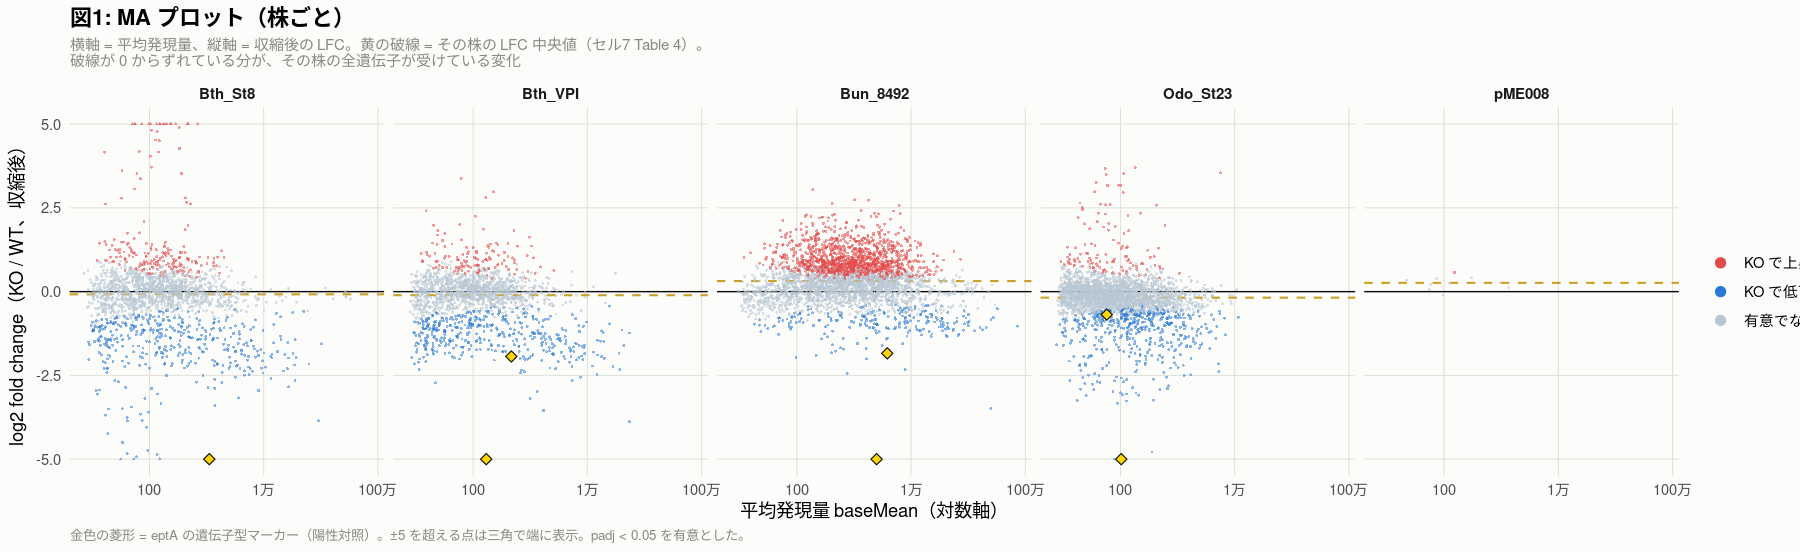

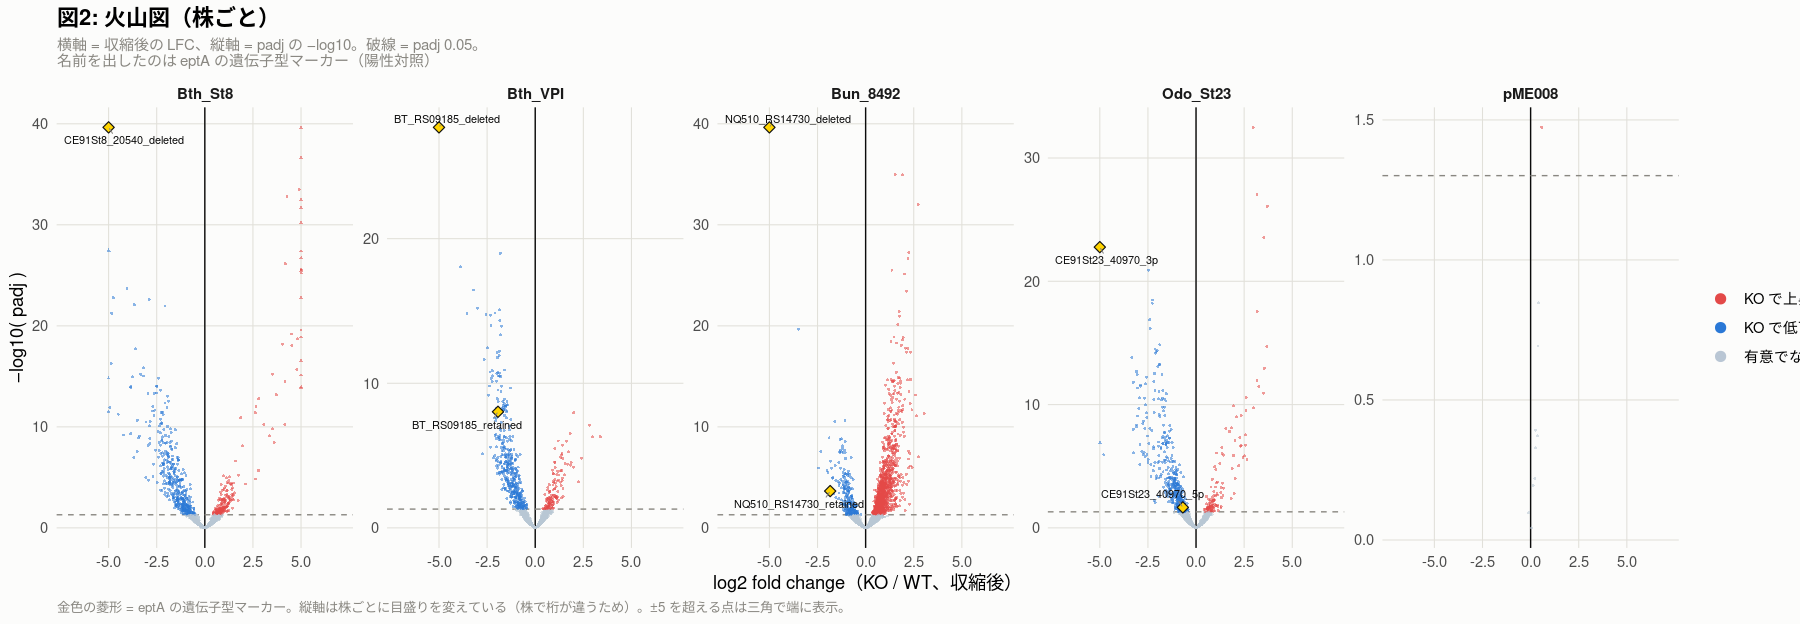

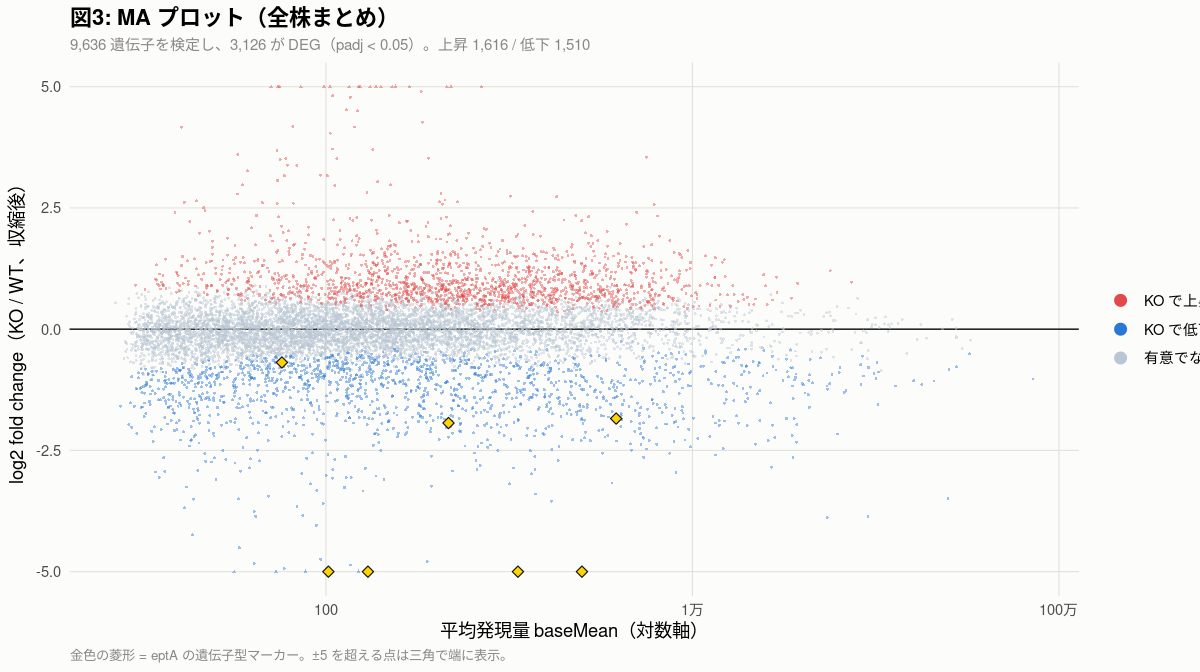

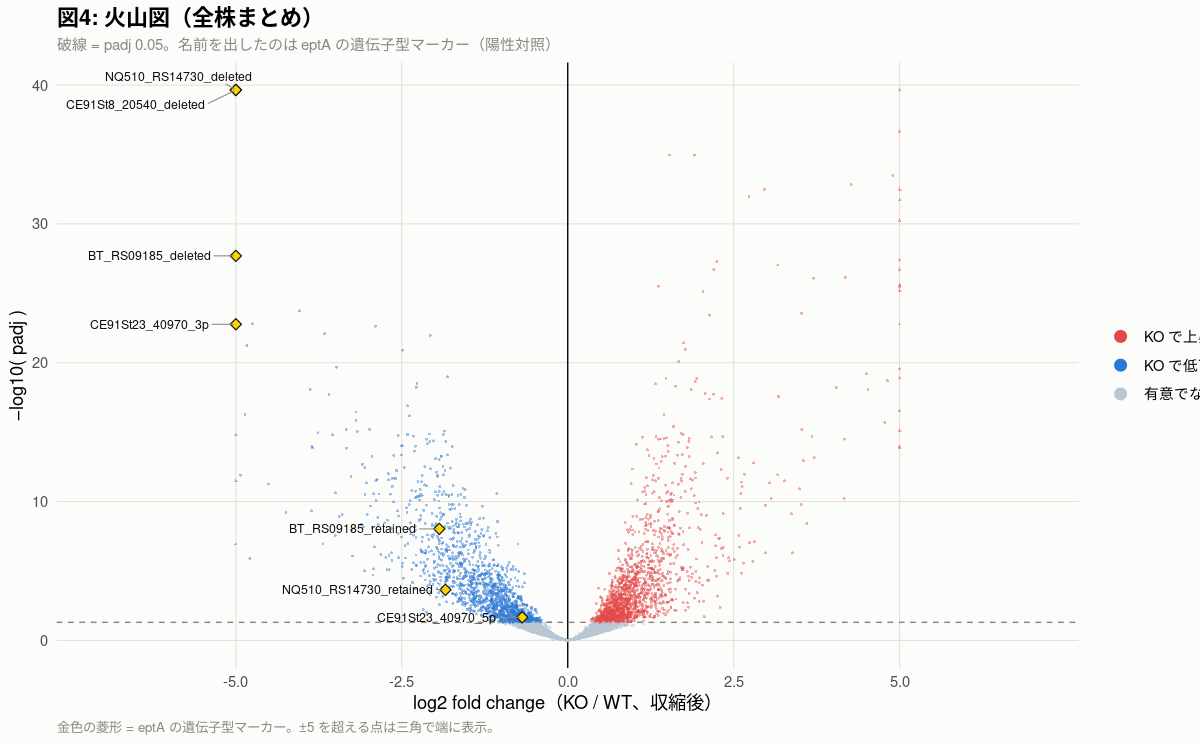

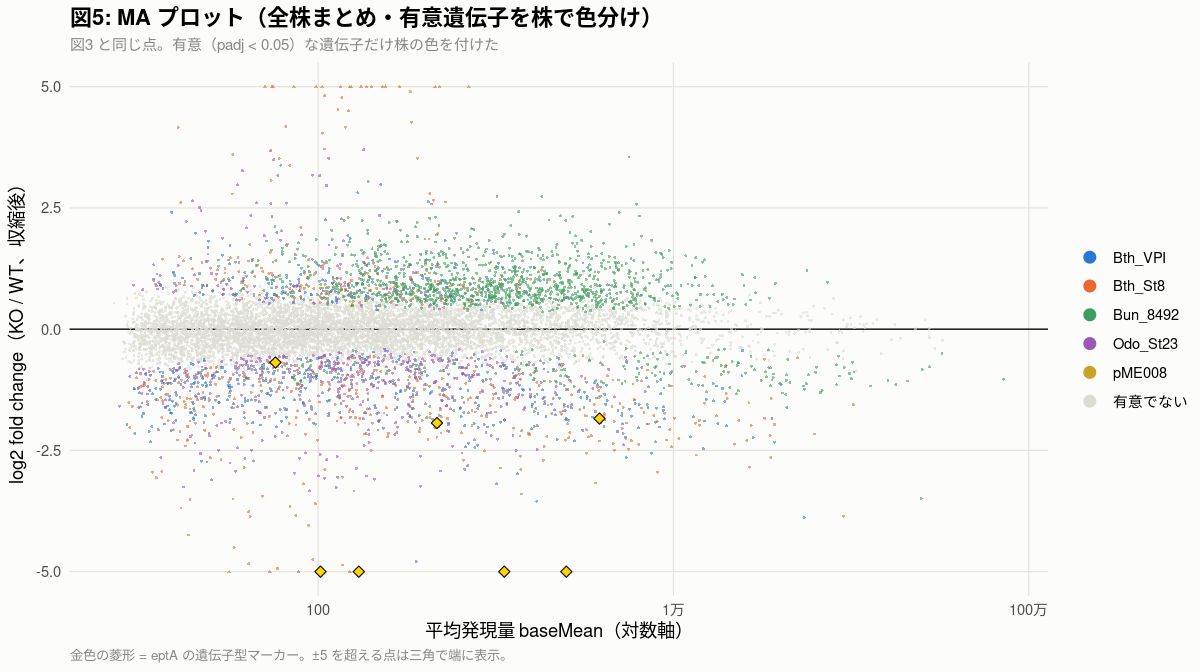

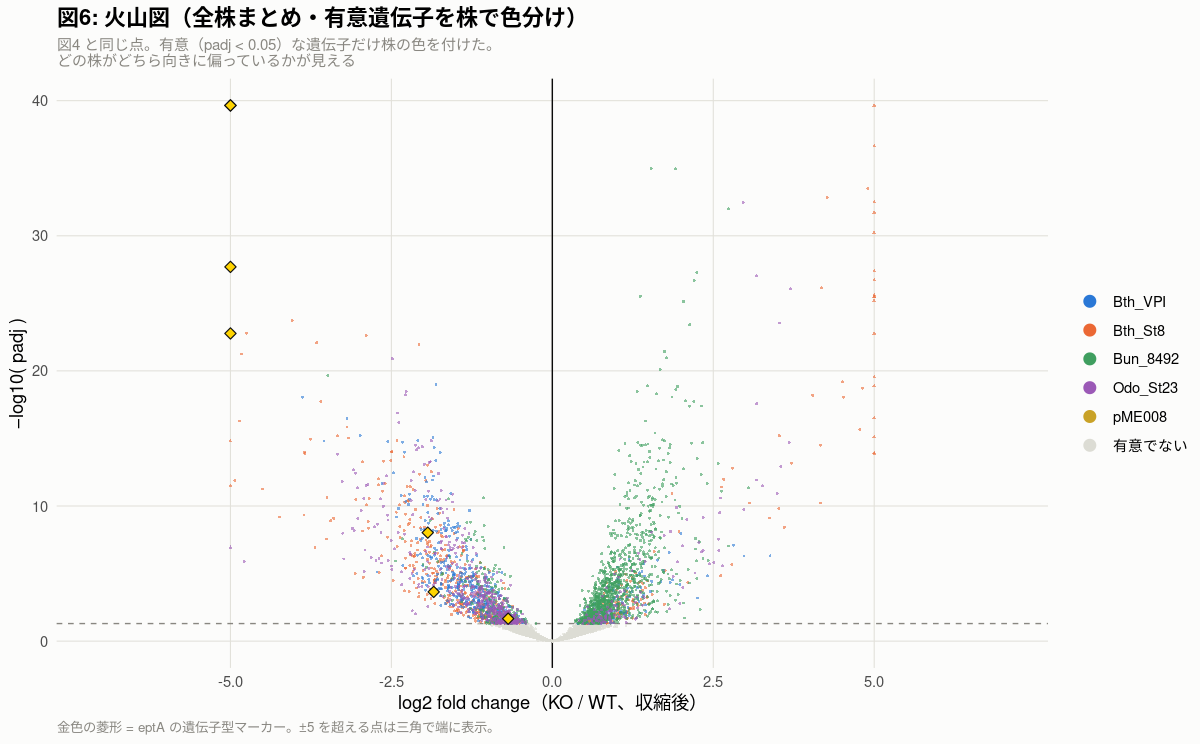

In [13]:
# ── MA プロットと火山図 ─────────────────────────────────────────
# 過去notebook（セル16-17）は plotMA と EnhancedVolcano。
#   ・EnhancedVolcano はこの環境に無いので ggplot2 で描く
#   ・横軸は【収縮後の LFC】にする（生の LFC は低カウント遺伝子で暴れる。セル7）
#   ・(A) は4株をまとめた解析なので【株ごとに分けて】描く。これが (A) の要点
#   ・色は上昇=赤 / 低下=青（ステージ6 の最終図と同じ約束）
library(ggrepel)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_dir = c(`KO で上昇` = '#e34948', `KO で低下` = '#2a78d6', `有意でない` = '#b9c6d4')
# 株の色（セル6図 と同じ。このセル単体でも動くようここでも定義する）
col_strain = c(Bth_VPI = '#2a78d6', Bth_St8 = '#eb6834', Bun_8492 = '#3f9e5f',
               Odo_St23 = '#9b59b6', pME008 = '#c9a227')

# 株ごとの LFC 中央値（セル7 Table 4）。MA プロットに水平線として引く
med = de %>% group_by(strain) %>%
    summarise(med = median(LFC_shrunk, na.rm = TRUE), .groups = 'drop')

plt = de %>%
    filter(!is.na(padj), !is.na(LFC_shrunk)) %>%
    mutate(向き = ifelse(padj >= 0.05, '有意でない',
                  ifelse(LFC_shrunk > 0, 'KO で上昇', 'KO で低下')),
           向き = factor(向き, levels = names(col_dir)),
           # LFC が −14 まで振れるので ±5 で切る（切った点は三角で示す）
           y_ma = pmax(pmin(LFC_shrunk, 5), -5),
           clipped = abs(LFC_shrunk) > 5)

lab = plt %>% filter(marker)      # eptA マーカー（陽性対照）。名前と強調色を付ける
# 強調色は金色の菱形＋黒縁。株の色とも上昇/低下の色とも重ならない
col_mk_fill = '#ffd400'; col_mk_line = '#111111'

thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# ── 図1: MA プロット ───────────────────────────────────────────
options(repr.plot.width = 15, repr.plot.height = 4.6)

p1 = ggplot(plt, aes(x = baseMean, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(data = med, aes(yintercept = med), colour = '#c9a227',
               linewidth = 0.6, linetype = 'dashed') +
    geom_point(aes(colour = 向き, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = lab, aes(x = baseMean, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','1万','100万')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    facet_wrap(~ strain, nrow = 1) +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = '図1: MA プロット（株ごと）',
         subtitle = paste0('横軸 = 平均発現量、縦軸 = 収縮後の LFC。',
                           '黄の破線 = その株の LFC 中央値（セル7 Table 4）。\n',
                           '破線が 0 からずれている分が、その株の全遺伝子が受けている変化'),
         x = '平均発現量 baseMean（対数軸）', y = 'log2 fold change（KO / WT、収縮後）',
         caption = paste0('金色の菱形 = eptA の遺伝子型マーカー（陽性対照）。',
                          '±5 を超える点は三角で端に表示。padj < 0.05 を有意とした。')) + thm
suppressWarnings(print(p1))

# ── 図2: 火山図 ────────────────────────────────────────────────
options(repr.plot.width = 15, repr.plot.height = 5.2)


p2 = ggplot(plt, aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = 向き, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = lab, aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj)),
               shape = 23, size = 2.2, fill = col_mk_fill, colour = col_mk_line,
               stroke = 0.5) +
    geom_text_repel(data = lab,
                    aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj),
                        label = gene_id),
                    size = 2.3, colour = col_text, seed = 1, direction = 'y',
                    nudge_x = ifelse(lab$LFC_shrunk < 0, -1.6, 1.6),
                    min.segment.length = 0, segment.colour = col_muted,
                    segment.size = 0.3, box.padding = 0.3, max.overlaps = Inf) +
    scale_colour_manual(values = col_dir, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    # ラベルを置く余白を左右に取る（点は ±5 で切ってある）
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    facet_wrap(~ strain, nrow = 1, scales = 'free_y') +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = '図2: 火山図（株ごと）',
         subtitle = paste0('横軸 = 収縮後の LFC、縦軸 = padj の −log10。',
                           '破線 = padj 0.05。\n',
                           '名前を出したのは eptA の遺伝子型マーカー（陽性対照）'),
         x = 'log2 fold change（KO / WT、収縮後）', y = '−log10( padj )',
         caption = paste0('金色の菱形 = eptA の遺伝子型マーカー。',
                          '縦軸は株ごとに目盛りを変えている（株で桁が違うため）。',
                          '±5 を超える点は三角で端に表示。')) + thm
suppressWarnings(print(p2))

# ── 図3・図4: 全株をまとめた図（株で分けない）──────────────────
# 株ごとの図は各株の中の動きを見るためのもの。
# ここでは【群集全体として何が起きているか】を1枚で見る。これが (A) の問い
options(repr.plot.width = 10, repr.plot.height = 5.6)

p3 = ggplot(plt, aes(x = baseMean, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_point(aes(colour = 向き, shape = clipped), size = 0.5, alpha = 0.45) +
    geom_point(data = lab, aes(x = baseMean, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','1万','100万')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = '図3: MA プロット（全株まとめ）',
         subtitle = sprintf('%s 遺伝子を検定し、%s が DEG（padj < 0.05）。上昇 %s / 低下 %s',
                            format(sum(!is.na(de$padj)), big.mark = ','),
                            format(sum(sig), big.mark = ','),
                            format(sum(sig & de$LFC_shrunk > 0), big.mark = ','),
                            format(sum(sig & de$LFC_shrunk < 0), big.mark = ',')),
         x = '平均発現量 baseMean（対数軸）', y = 'log2 fold change（KO / WT、収縮後）',
         caption = '金色の菱形 = eptA の遺伝子型マーカー。±5 を超える点は三角で端に表示。') + thm
suppressWarnings(print(p3))

options(repr.plot.width = 10, repr.plot.height = 6.2)

p4 = ggplot(plt, aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = 向き, shape = clipped), size = 0.5, alpha = 0.45) +
    geom_point(data = lab, aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj)),
               shape = 23, size = 2.2, fill = col_mk_fill, colour = col_mk_line,
               stroke = 0.5) +
    geom_text_repel(data = lab,
                    aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj),
                        label = gene_id),
                    size = 2.6, colour = col_text, seed = 1,
                    nudge_x = ifelse(lab$LFC_shrunk < 0, -1.3, 1.3),
                    min.segment.length = 0, segment.colour = col_muted,
                    segment.size = 0.3, box.padding = 0.4, max.overlaps = Inf) +
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = '図4: 火山図（全株まとめ）',
         subtitle = '破線 = padj 0.05。名前を出したのは eptA の遺伝子型マーカー（陽性対照）',
         x = 'log2 fold change（KO / WT、収縮後）', y = '−log10( padj )',
         caption = '金色の菱形 = eptA の遺伝子型マーカー。±5 を超える点は三角で端に表示。') + thm
suppressWarnings(print(p4))

# ── 図5・図6: 全株まとめ、有意遺伝子だけを株で色分け ───────────────
# 図3・図4 で見えた動きが【どの株から来ているか】を見る。
# 有意でない遺伝子は薄い灰色にして背景に下げる
plt2 = plt %>% mutate(色 = ifelse(padj < 0.05, as.character(strain), '有意でない'),
                      色 = factor(色, levels = c(names(col_strain), '有意でない')))
col_sig = c(col_strain, `有意でない` = '#dcdcd4')

options(repr.plot.width = 10, repr.plot.height = 5.6)

# 有意でない点を先に描いて背景に下げる
plt2 = plt2 %>% arrange(desc(色 == '有意でない'))

p5 = ggplot(plt2, aes(x = baseMean, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_point(aes(colour = 色, shape = clipped), size = 0.5, alpha = 0.6) +
    geom_point(data = lab, aes(x = baseMean, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','1万','100万')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_sig, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = '図5: MA プロット（全株まとめ・有意遺伝子を株で色分け）',
         subtitle = '図3 と同じ点。有意（padj < 0.05）な遺伝子だけ株の色を付けた',
         x = '平均発現量 baseMean（対数軸）', y = 'log2 fold change（KO / WT、収縮後）',
         caption = '金色の菱形 = eptA の遺伝子型マーカー。±5 を超える点は三角で端に表示。') + thm
suppressWarnings(print(p5))

options(repr.plot.width = 10, repr.plot.height = 6.2)

p6 = ggplot(plt2, aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = 色, shape = clipped), size = 0.5, alpha = 0.6) +
    geom_point(data = lab, aes(x = pmax(pmin(LFC_shrunk, 5), -5), y = -log10(padj)),
               shape = 23, size = 2.2, fill = col_mk_fill, colour = col_mk_line,
               stroke = 0.5) +
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_sig, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = '図6: 火山図（全株まとめ・有意遺伝子を株で色分け）',
         subtitle = paste0('図4 と同じ点。有意（padj < 0.05）な遺伝子だけ株の色を付けた。\n',
                           'どの株がどちら向きに偏っているかが見える'),
         x = 'log2 fold change（KO / WT、収縮後）', y = '−log10( padj )',
         caption = '金色の菱形 = eptA の遺伝子型マーカー。±5 を超える点は三角で端に表示。') + thm
suppressWarnings(print(p6))

## セル8図（英語版）: MA plot / Volcano plot

**中身はセル8図 と同じ6枚で、文字だけ英語にしたもの。**

### なぜ英語版を別に作るか

**PDF / EPS に出すときの文字化けを避けるため。**
R の既定の PDF / PostScript デバイスは**日本語フォントを埋め込めない**ので、
日本語のタイトルや軸名がそのままでは化ける。

英語版なら、そのまま出せる。

```r
ggsave('fig_MA_bystrain.pdf',  p1_en, width = 15, height = 4.6)
ggsave('fig_MA_bystrain.eps',  p1_en, width = 15, height = 4.6)
```

**※ 日本語版をどうしても PDF にしたい場合**は `device = cairo_pdf` を使えば埋め込める
（ただし EPS は不可）。

```r
ggsave('fig_ja.pdf', p1, width = 15, height = 4.6, device = cairo_pdf)
```

### オブジェクト名

後から保存できるよう、`p1_en` 〜 `p6_en` という名前で残してある。

| 変数 | 図 |
|---|---|
| `p1_en` | Fig 1: MA plot by strain |
| `p2_en` | Fig 2: Volcano plot by strain |
| `p3_en` | Fig 3: MA plot, all strains pooled |
| `p4_en` | Fig 4: Volcano plot, all strains pooled |
| `p5_en` | Fig 5: MA plot, pooled, significant genes coloured by strain |
| `p6_en` | Fig 6: Volcano plot, pooled, significant genes coloured by strain |

### 用語の対応

| 日本語版 | 英語版 |
|---|---|
| KO で上昇 / KO で低下 / 有意でない | `Up in KO` / `Down in KO` / `n.s.` |
| 平均発現量 baseMean | `mean of normalized counts` |
| 収縮後の LFC | `log2 fold change (KO / WT, shrunk)` |

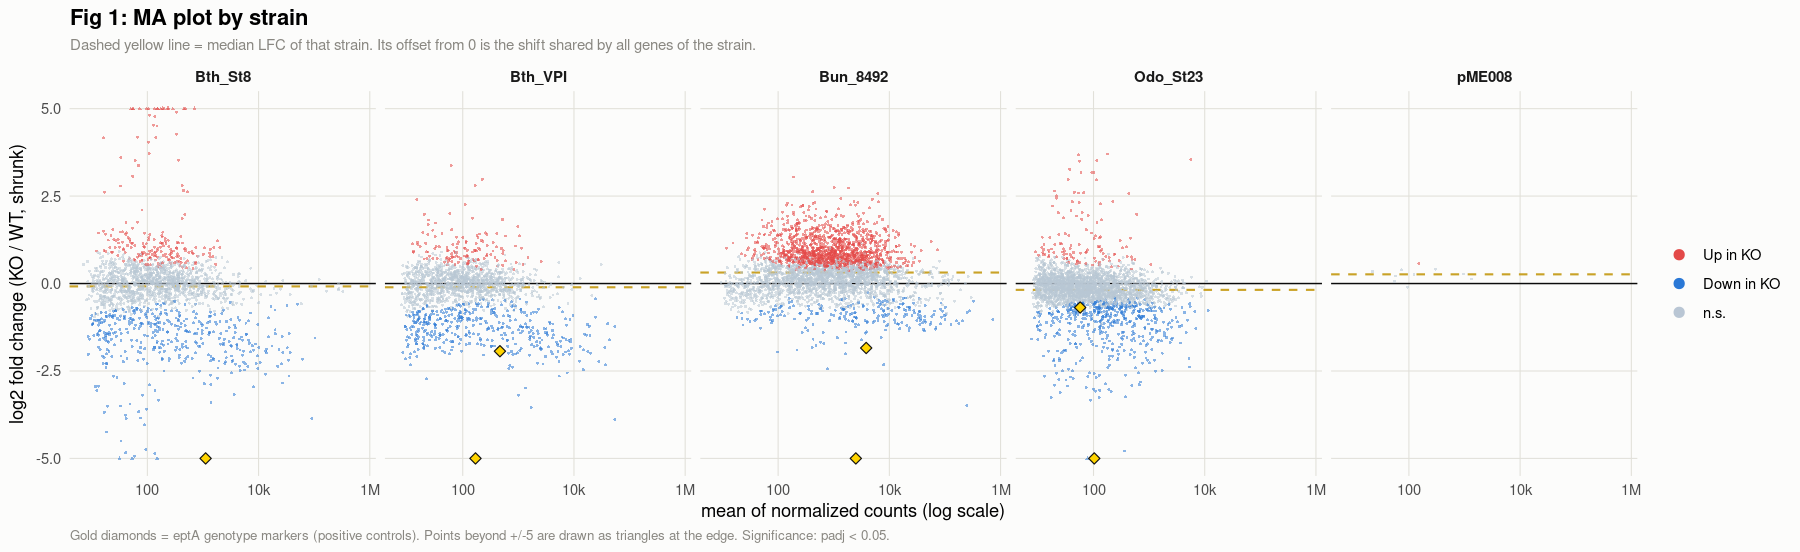

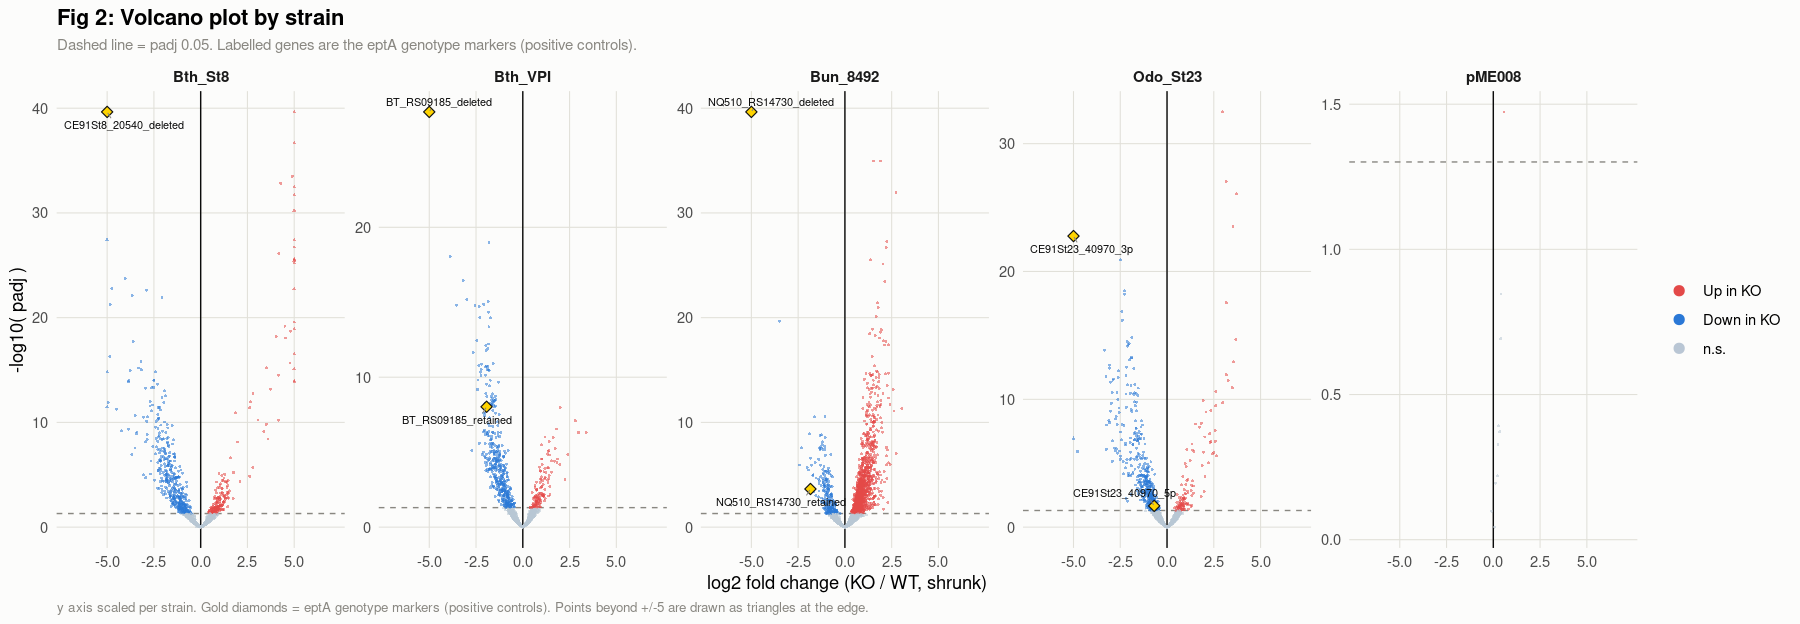

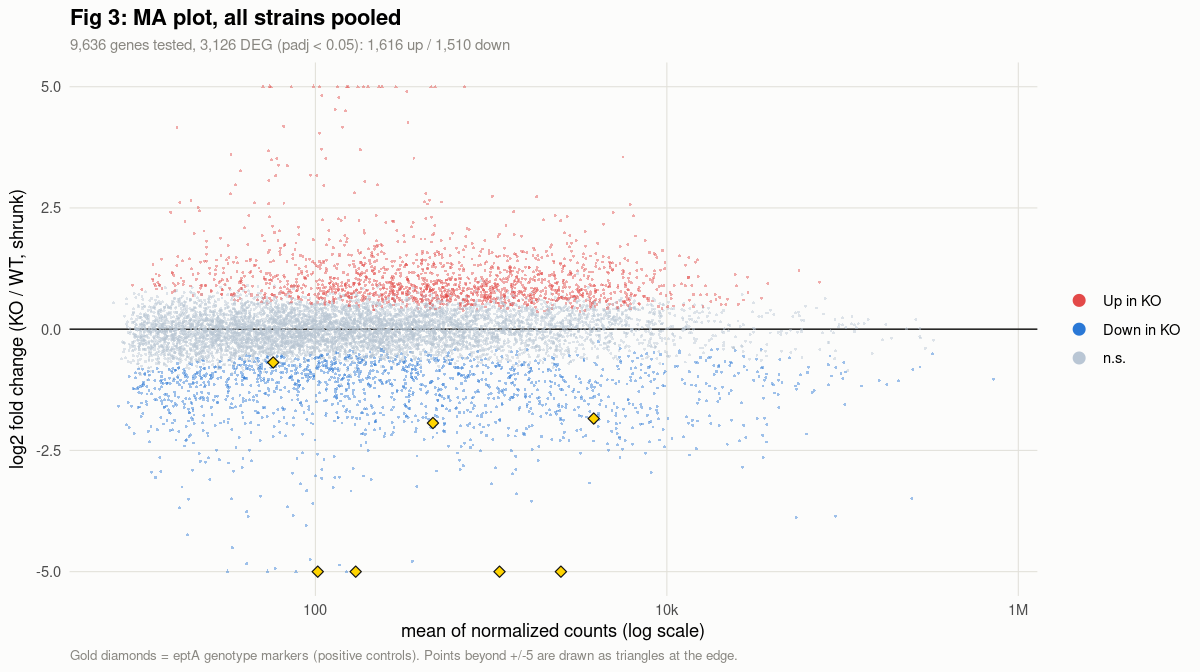

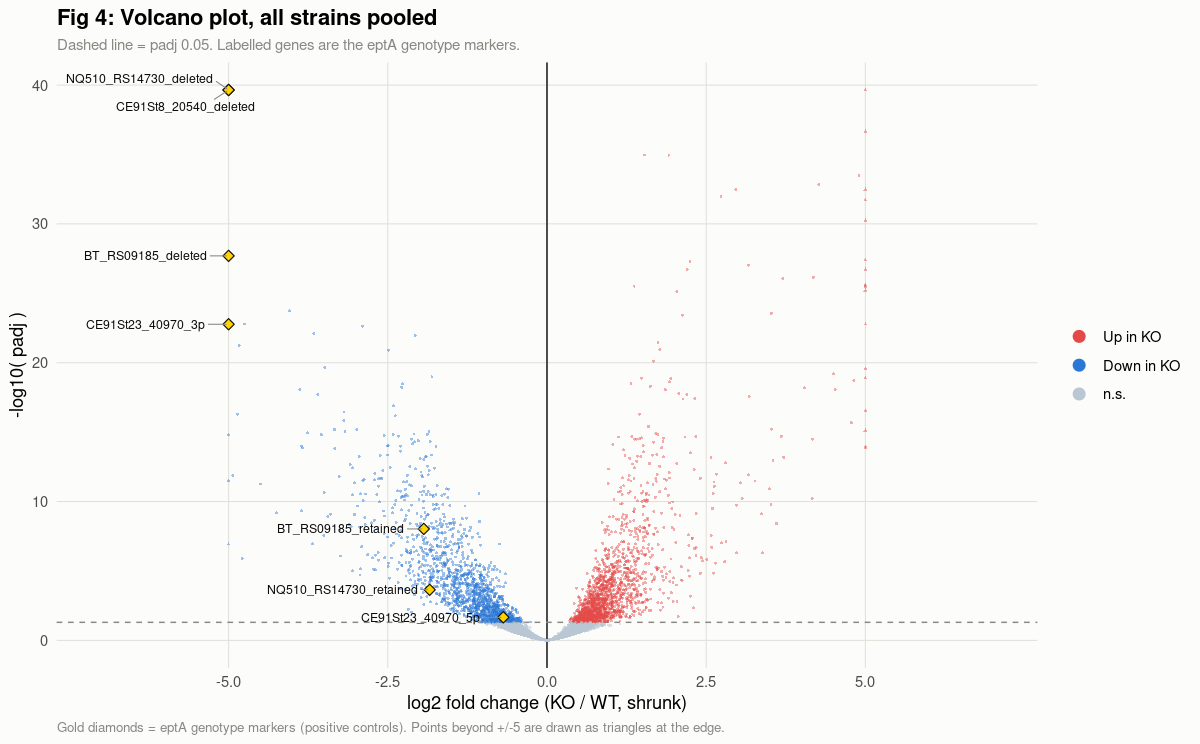

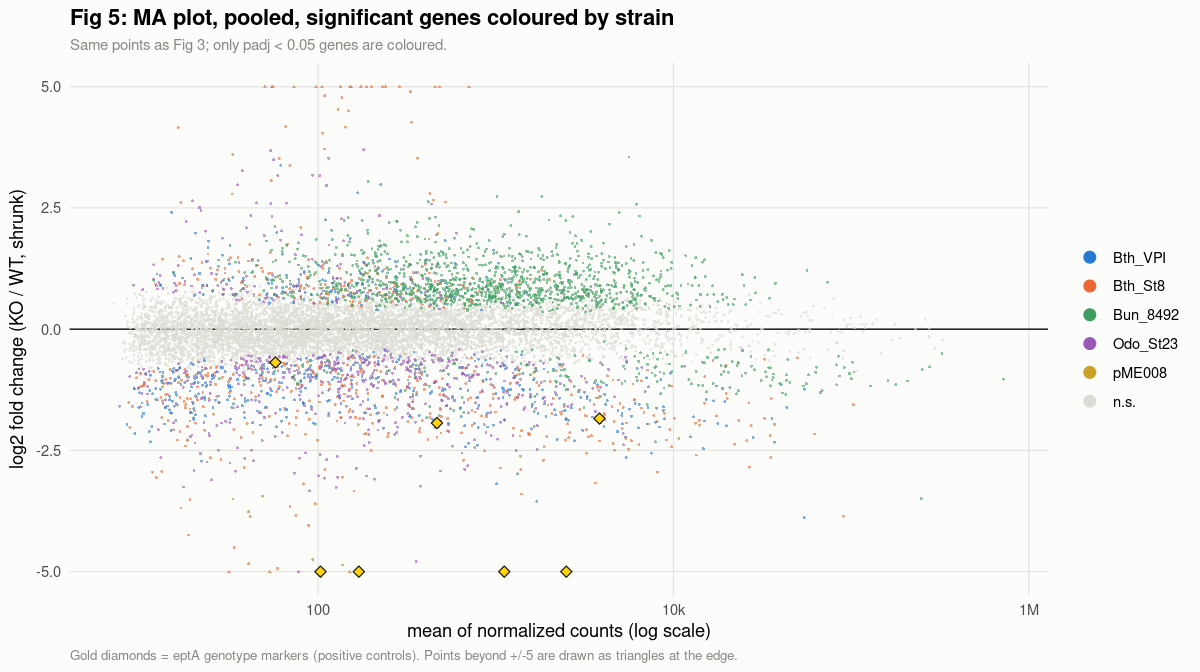

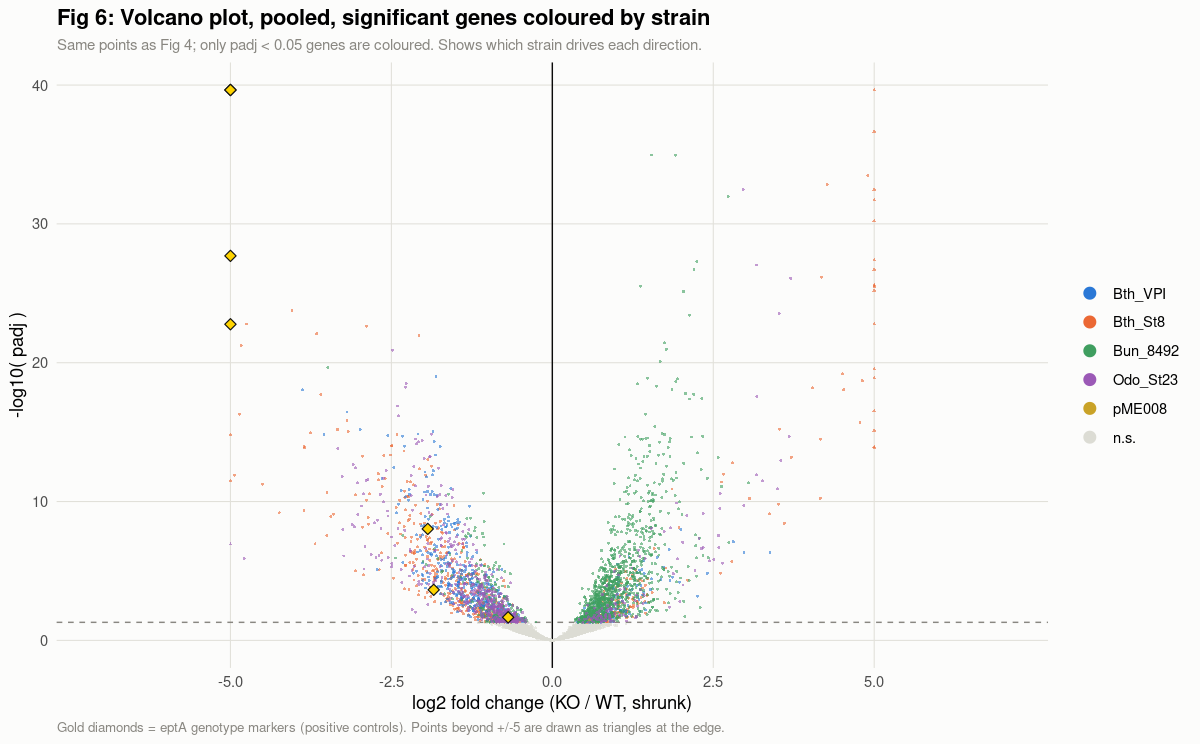

In [14]:
# ── Same figures, English labels（PDF / EPS 出力用）──────────────
# セル8図 と中身は同じで、文字だけ英語にしたもの。
# 日本語フォントを埋め込まずに PDF / EPS に出せるようにするため。
#   例) ggsave('fig.pdf', p1_en, width = 15, height = 4.6, device = cairo_pdf)
#       ggsave('fig.eps', p1_en, width = 15, height = 4.6)
library(ggplot2); library(ggrepel)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_dir_en = c(`Up in KO` = '#e34948', `Down in KO` = '#2a78d6', `n.s.` = '#b9c6d4')
col_strain = c(Bth_VPI = '#2a78d6', Bth_St8 = '#eb6834', Bun_8492 = '#3f9e5f',
               Odo_St23 = '#9b59b6', pME008 = '#c9a227')

med_en = de %>% group_by(strain) %>%
    summarise(med = median(LFC_shrunk, na.rm = TRUE), .groups = 'drop')

plt_en = de %>%
    filter(!is.na(padj), !is.na(LFC_shrunk)) %>%
    mutate(direction = ifelse(padj >= 0.05, 'n.s.',
                       ifelse(LFC_shrunk > 0, 'Up in KO', 'Down in KO')),
           direction = factor(direction, levels = names(col_dir_en)),
           y_ma = pmax(pmin(LFC_shrunk, 5), -5),
           clipped = abs(LFC_shrunk) > 5,
           x_vol = pmax(pmin(LFC_shrunk, 5), -5))


lab_en = plt_en %>% filter(marker)      # eptA genotype markers (positive controls)
col_mk_fill = '#ffd400'; col_mk_line = '#111111'

thm_en = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

lab_ma  = 'log2 fold change (KO / WT, shrunk)'
cap_clip = paste('Gold diamonds = eptA genotype markers (positive controls).',
                 'Points beyond +/-5 are drawn as triangles at the edge.')

# ── Fig 1: MA plot, by strain ──────────────────────────────────
options(repr.plot.width = 15, repr.plot.height = 4.6)
p1_en = ggplot(plt_en, aes(x = baseMean, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(data = med_en, aes(yintercept = med), colour = '#c9a227',
               linewidth = 0.6, linetype = 'dashed') +
    geom_point(aes(colour = direction, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = lab_en, aes(x = baseMean, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','10k','1M')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    facet_wrap(~ strain, nrow = 1) +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = 'Fig 1: MA plot by strain',
         subtitle = paste0('Dashed yellow line = median LFC of that strain. ',
                           'Its offset from 0 is the shift shared by all genes of the strain.'),
         x = 'mean of normalized counts (log scale)', y = lab_ma,
         caption = paste(cap_clip, 'Significance: padj < 0.05.')) + thm_en
suppressWarnings(print(p1_en))

# ── Fig 2: volcano, by strain ──────────────────────────────────
options(repr.plot.width = 15, repr.plot.height = 5.2)
p2_en = ggplot(plt_en, aes(x = x_vol, y = -log10(padj))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = direction, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = lab_en, aes(x = x_vol, y = -log10(padj)), shape = 23,
               size = 2.2, fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    geom_text_repel(data = lab_en, aes(x = x_vol, y = -log10(padj), label = gene_id),
                    size = 2.3, colour = col_text, seed = 1, direction = 'y',
                    nudge_x = ifelse(lab_en$LFC_shrunk < 0, -1.6, 1.6),
                    min.segment.length = 0, segment.colour = col_muted,
                    segment.size = 0.3, box.padding = 0.3, max.overlaps = Inf) +
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    facet_wrap(~ strain, nrow = 1, scales = 'free_y') +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = 'Fig 2: Volcano plot by strain',
         subtitle = paste0('Dashed line = padj 0.05. ',
                           'Labelled genes are the eptA genotype markers (positive controls).'),
         x = lab_ma, y = '-log10( padj )',
         caption = paste('y axis scaled per strain.', cap_clip)) + thm_en
suppressWarnings(print(p2_en))

# ── Fig 3 / 4: all strains pooled ──────────────────────────────
options(repr.plot.width = 10, repr.plot.height = 5.6)
sub_pool = sprintf('%s genes tested, %s DEG (padj < 0.05): %s up / %s down',
                   format(sum(!is.na(de$padj)), big.mark = ','),
                   format(sum(sig), big.mark = ','),
                   format(sum(sig & de$LFC_shrunk > 0), big.mark = ','),
                   format(sum(sig & de$LFC_shrunk < 0), big.mark = ','))

p3_en = ggplot(plt_en, aes(x = baseMean, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_point(aes(colour = direction, shape = clipped), size = 0.5, alpha = 0.45) +
    geom_point(data = lab_en, aes(x = baseMean, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','10k','1M')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = 'Fig 3: MA plot, all strains pooled', subtitle = sub_pool,
         x = 'mean of normalized counts (log scale)', y = lab_ma,
         caption = cap_clip) + thm_en
suppressWarnings(print(p3_en))

options(repr.plot.width = 10, repr.plot.height = 6.2)
p4_en = ggplot(plt_en, aes(x = x_vol, y = -log10(padj))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = direction, shape = clipped), size = 0.5, alpha = 0.45) +
    geom_point(data = lab_en, aes(x = x_vol, y = -log10(padj)), shape = 23,
               size = 2.2, fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    geom_text_repel(data = lab_en, aes(x = x_vol, y = -log10(padj), label = gene_id),
                    size = 2.6, colour = col_text, seed = 1,
                    nudge_x = ifelse(lab_en$LFC_shrunk < 0, -1.3, 1.3),
                    min.segment.length = 0, segment.colour = col_muted,
                    segment.size = 0.3, box.padding = 0.4, max.overlaps = Inf) +
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = 'Fig 4: Volcano plot, all strains pooled',
         subtitle = 'Dashed line = padj 0.05. Labelled genes are the eptA genotype markers.',
         x = lab_ma, y = '-log10( padj )', caption = cap_clip) + thm_en
suppressWarnings(print(p4_en))

# ── Fig 5 / 6: pooled, significant genes coloured by strain ────
plt2_en = plt_en %>%
    mutate(fill_by = ifelse(padj < 0.05, as.character(strain), 'n.s.'),
           fill_by = factor(fill_by, levels = c(names(col_strain), 'n.s.'))) %>%
    arrange(desc(fill_by == 'n.s.'))      # draw n.s. first, behind
col_sig_en = c(col_strain, `n.s.` = '#dcdcd4')

options(repr.plot.width = 10, repr.plot.height = 5.6)
p5_en = ggplot(plt2_en, aes(x = baseMean, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_point(aes(colour = fill_by, shape = clipped), size = 0.5, alpha = 0.6) +
    geom_point(data = lab_en, aes(x = baseMean, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','10k','1M')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_sig_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = 'Fig 5: MA plot, pooled, significant genes coloured by strain',
         subtitle = 'Same points as Fig 3; only padj < 0.05 genes are coloured.',
         x = 'mean of normalized counts (log scale)', y = lab_ma,
         caption = cap_clip) + thm_en
suppressWarnings(print(p5_en))

options(repr.plot.width = 10, repr.plot.height = 6.2)
p6_en = ggplot(plt2_en, aes(x = x_vol, y = -log10(padj))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = fill_by, shape = clipped), size = 0.5, alpha = 0.6) +
    geom_point(data = lab_en, aes(x = x_vol, y = -log10(padj)), shape = 23,
               size = 2.2, fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_sig_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    guides(colour = guide_legend(override.aes = list(size = 3, alpha = 1))) +
    labs(title = 'Fig 6: Volcano plot, pooled, significant genes coloured by strain',
         subtitle = paste0('Same points as Fig 4; only padj < 0.05 genes are coloured. ',
                           'Shows which strain drives each direction.'),
         x = lab_ma, y = '-log10( padj )', caption = cap_clip) + thm_en
suppressWarnings(print(p6_en))

## セル9: eptA 近傍を調べる

セル8図 で、**`_retained` / `_5p`（両群に共通する領域）が3件とも KO で低め**に出ていた。
これが偶然か、何か実体があるのかを確かめる。

| 見る点 | 問い |
|---|---|
| **(1)** | その株の基準（LFC 中央値）からどれだけ外れているか |
| **(2)** | 近傍の遺伝子も下がっているか |
| **(3)** | **欠失点からの距離と LFC が対応するか** → 対応するなら**二重交叉のホモロジーアーム由来のマッピング不良**が疑われる |
| **(4)** | 下がっている遺伝子は **eptA と同じ転写単位にありうるか** → **欠失によるポーラー効果**で説明できるか |

### ★ (4) で上流/下流は「転写方向」で決める

**ゲノム座標ではない。** `Bth_VPI` と `Odo_St23` の eptA は**マイナス鎖**なので、
**座標が小さい側が転写的には下流**になる。ここを取り違えると結論が逆になる。

**ポーラー効果は「同じ鎖の転写下流」にしか及ばない。**
別の鎖、あるいは転写上流の遺伝子が下がっていれば、**欠失の直接の影響では説明できない。**

### 座標の出どころ

**遺伝子の座標は `feature_info.csv` に入っていない**ので、GTF（`oligo_eptA_count.gtf`）から読む。
同じ `gene_id` が複数行ある（`_retained` の2区間など）ので、
**最小 `start` 〜 最大 `end`** にまとめる。この座標は**セル10（CPS 座位の列）でも使う。**

In [15]:
# ── eptA 近傍を調べる ───────────────────────────────────────────
# セル8図 で、_retained / _5p（両群に共通する領域）が3件とも KO で低めに出ていた。
# これが偶然か、何か実体があるのかを確かめる。見るのは3点。
#   (1) その株の基準（LFC 中央値）からどれだけ外れているか
#   (2) 近傍の遺伝子も下がっているか（オペロン/ポーラー効果・協調制御の確認）
#   (3) 欠失点からの距離と LFC が対応するか
#       → 対応するなら二重交叉のホモロジーアーム由来のマッピング不良が疑われる
#
# ★ 遺伝子の座標は feature_info.csv に入っていないので GTF から読む。
#   この座標はセル10（CPS 座位の列）でも使う
library(stringr)

if (!exists('gtf_count')) {
    gtf_count = read.table(path_gtf_count, sep = "\t", header = FALSE, quote = "",
                           comment.char = "", stringsAsFactors = FALSE)
    colnames(gtf_count) = c('contig','source','feature','start','end',
                            'score','strand','frame','attr')
    gtf_count$gene_id = str_match(gtf_count$attr, '^gene_id "([^"]+)"')[, 2]
}

# 同じ gene_id が複数行ある（_retained の2区間など）ので、最小start〜最大end にまとめる
pos = gtf_count %>%
    group_by(gene_id) %>%
    summarise(contig = dplyr::first(contig), strand = dplyr::first(strand),
              start = min(start), end = max(end), .groups = 'drop')

de = de %>% left_join(pos, by = 'gene_id')

# ── (1) マーカーが株の基準からどれだけ外れているか ────────────────
# 「KO で低い」のがその株全体の傾向で説明できるかを見る
strain_med = tapply(de$LFC_shrunk, de$strain, median, na.rm = TRUE)

cat("■ Table 1: eptA マーカーの LFC と、その株の基準からのずれ\n")
cat("   strain_baseline … その株の LFC 中央値（セル7 Table 4）\n")
cat("   deviation       … LFC_shrunk − strain_baseline。株全体の傾向を差し引いた残り\n")
de %>% filter(marker) %>%
    mutate(region = ifelse(grepl('_deleted$|_3p$', gene_id),
                           'lost in KO', 'shared by both groups'),
           strain_baseline = round(strain_med[as.character(strain)], 3),
           deviation = round(LFC_shrunk - strain_med[as.character(strain)], 2),
           LFC_shrunk = round(LFC_shrunk, 2), padj = signif(padj, 2)) %>%
    dplyr::select(gene_id, strain, region, LFC_shrunk, strain_baseline,
                  deviation, padj) %>%
    arrange(region, gene_id) %>% as.data.frame()

# ── (2)(3) 近傍の遺伝子と、欠失点からの距離 ───────────────────────
# eptA の欠失区間（_deleted / _3p）を基準に、前後 4 kb の遺伝子を距離順に並べる
ept = c(Bth_VPI = 'BT_RS09185_deleted',  Bth_St8  = 'CE91St8_20540_deleted',
        Bun_8492 = 'NQ510_RS14730_deleted', Odo_St23 = 'CE91St23_40970_3p')

nbr = do.call(rbind, lapply(names(ept), function(st) {
    d0 = pos %>% filter(gene_id == ept[st])
    de %>%
        filter(strain == st, contig == d0$contig,
               start >= d0$start - 4000, end <= d0$end + 4000,
               !marker) %>%                      # マーカー自身は Table 1 で見たので除く
        mutate(strain = st,
               # 欠失区間と重なっていれば 0、離れていればその距離
               dist_bp = ifelse(start <= d0$end & end >= d0$start, 0L,
                                as.integer(pmin(abs(start - d0$end),
                                                abs(d0$start - end)))),
               # ★ 上流/下流は【転写方向】で決める。ゲノム座標ではない。
               #   eptA がマイナス鎖（Bth_VPI・Odo_St23）のときは、
               #   座標が小さい側が転写的には下流になる
               side = if (d0$strand == '+') ifelse(start > d0$end, 'downstream', 'upstream')
                      else                  ifelse(end < d0$start, 'downstream', 'upstream'),
               same_strand = strand == d0$strand,
               LFC = round(LFC_shrunk, 2), padj = signif(padj, 2),
               product = substr(product, 1, 36)) %>%
        dplyr::select(strain, gene_id, dist_bp, side, strand, same_strand,
                      LFC, padj, product) %>%
        arrange(dist_bp)
}))

cat("\n■ Table 2: eptA 欠失点の前後 4 kb にある遺伝子（距離順）\n")
cat("   dist_bp     … 欠失区間からの距離。ホモロジーアーム由来のマッピング不良なら\n")
cat("                 【距離が近いほど LFC が低い】形になるはず\n")
cat("   side        … eptA から見た【転写方向での】上流/下流（ゲノム座標ではない）\n")
cat("   same_strand … eptA と同じ鎖か。欠失によるポーラー効果は\n")
cat("                 【同じ鎖の転写下流】にしか及ばない。それ以外は別の転写単位\n")
nbr %>% as.data.frame()

cat("\n■ Table 3: 距離と LFC に対応があるか（株ごとの相関）\n")
nbr %>% group_by(strain) %>%
    summarise(n = dplyr::n(),
              nearest_bp = min(dist_bp),
              LFC_of_nearest = LFC[which.min(dist_bp)],
              most_reduced_at_bp = dist_bp[which.min(LFC)],
              lowest_LFC = min(LFC),
              spearman_dist_vs_LFC = round(cor(dist_bp, LFC, method = 'spearman'), 3),
              .groups = 'drop') %>% as.data.frame()

cat("\n■ Table 4: 下がっている近傍遺伝子は eptA と同じ転写単位にありうるか\n")
cat("   同じ鎖かつ下流 … 欠失によるポーラー効果で説明できる位置\n")
cat("   それ以外       … 別の転写単位。欠失の直接の影響では説明できない\n")
nbr %>% filter(!is.na(padj), padj < 0.05, LFC < 0) %>%
    mutate(位置 = ifelse(same_strand & side == 'downstream',
                         '同じ鎖かつ下流（ポーラー効果で説明可）',
                         'それ以外（別の転写単位）')) %>%
    dplyr::select(strain, gene_id, dist_bp, side, same_strand, LFC, 位置) %>%
    arrange(strain, dist_bp) %>% as.data.frame()
cat("   spearman が 0 に近い、または最も下がる遺伝子が最も近い遺伝子でないなら、\n")
cat("   マッピング不良では説明できない\n")

■ Table 1: eptA マーカーの LFC と、その株の基準からのずれ
   strain_baseline … その株の LFC 中央値（セル7 Table 4）
   deviation       … LFC_shrunk − strain_baseline。株全体の傾向を差し引いた残り


gene_id,strain,region,LFC_shrunk,strain_baseline,deviation,padj
<chr>,<chr>,<chr>,<dbl>,<dbl[1d]>,<dbl[1d]>,<dbl>
BT_RS09185_deleted,Bth_VPI,lost in KO,-13.16,-0.107,-13.05,2.0e-28
CE91St23_40970_3p,Odo_St23,lost in KO,-12.34,-0.181,-12.16,1.7e-23
CE91St8_20540_deleted,Bth_St8,lost in KO,-12.51,-0.081,-12.43,2.3e-40
NQ510_RS14730_deleted,Bun_8492,lost in KO,-14.61,0.315,-14.92,2.3e-40
BT_RS09185_retained,Bth_VPI,shared by both groups,-1.94,-0.107,-1.83,9.3e-09
CE91St23_40970_5p,Odo_St23,shared by both groups,-0.69,-0.181,-0.50,2.2e-02
NQ510_RS14730_retained,Bun_8492,shared by both groups,-1.84,0.315,-2.16,2.3e-04



■ Table 2: eptA 欠失点の前後 4 kb にある遺伝子（距離順）
   dist_bp     … 欠失区間からの距離。ホモロジーアーム由来のマッピング不良なら
                 【距離が近いほど LFC が低い】形になるはず
   side        … eptA から見た【転写方向での】上流/下流（ゲノム座標ではない）
   same_strand … eptA と同じ鎖か。欠失によるポーラー効果は
                 【同じ鎖の転写下流】にしか及ばない。それ以外は別の転写単位


strain,gene_id,dist_bp,side,strand,same_strand,LFC,padj,product
<chr>,<chr>,<int>,<chr>,<chr>,<lgl>,<dbl>,<dbl>,<chr>
Bth_VPI,BT_RS09190,117,upstream,-,TRUE,-1.50,9.6e-09,BamA/TamA family outer membrane prot
Bth_VPI,BT_RS09180,1263,downstream,-,TRUE,-1.88,7.5e-07,DnaJ C-terminal domain-containing pr
Bth_VPI,BT_RS09195,1404,upstream,-,TRUE,-0.73,2.1e-02,low specificity L-threonine aldolase
Bth_VPI,BT_RS09175,2243,downstream,-,TRUE,-2.01,2.5e-06,chaperone modulator CbpM
Bth_VPI,BT_RS09170,2670,downstream,+,FALSE,-0.89,6.2e-05,GAF domain-containing protein
Bth_VPI,BT_RS09205,2855,upstream,-,TRUE,-0.65,1.3e-01,RNA polymerase sigma factor
Bth_VPI,BT_RS09210,3559,upstream,+,FALSE,-0.03,9.5e-01,DUF6249 domain-containing protein
Bth_St8,CE91St8_20530,2,upstream,+,TRUE,-1.41,1.7e-05,membrane protein
Bth_St8,CE91St8_20550,214,downstream,+,TRUE,-1.36,2.6e-04,molecular chaperone DnaJ



■ Table 3: 距離と LFC に対応があるか（株ごとの相関）


strain,n,nearest_bp,LFC_of_nearest,most_reduced_at_bp,lowest_LFC,spearman_dist_vs_LFC
<chr>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>
Bth_St8,6,2,-1.41,1185,-1.58,0.771
Bth_VPI,7,117,-1.50,2243,-2.01,0.679
Bun_8492,5,186,-0.23,2931,-1.12,-0.700
Odo_St23,6,202,-0.32,1345,-1.31,0.143



■ Table 4: 下がっている近傍遺伝子は eptA と同じ転写単位にありうるか
   同じ鎖かつ下流 … 欠失によるポーラー効果で説明できる位置
   それ以外       … 別の転写単位。欠失の直接の影響では説明できない


strain,gene_id,dist_bp,side,same_strand,LFC,位置
<chr>,<chr>,<int>,<chr>,<lgl>,<dbl>,<chr>
Bth_St8,CE91St8_20530,2,upstream,TRUE,-1.41,それ以外（別の転写単位）
Bth_St8,CE91St8_20550,214,downstream,TRUE,-1.36,同じ鎖かつ下流（ポーラー効果で説明可）
Bth_St8,CE91St8_20560,1185,downstream,TRUE,-1.58,同じ鎖かつ下流（ポーラー効果で説明可）
Bth_St8,CE91St8_20570,1622,downstream,FALSE,-0.78,それ以外（別の転写単位）
Bth_VPI,BT_RS09190,117,upstream,TRUE,-1.50,それ以外（別の転写単位）
Bth_VPI,BT_RS09180,1263,downstream,TRUE,-1.88,同じ鎖かつ下流（ポーラー効果で説明可）
Bth_VPI,BT_RS09195,1404,upstream,TRUE,-0.73,それ以外（別の転写単位）
Bth_VPI,BT_RS09175,2243,downstream,TRUE,-2.01,同じ鎖かつ下流（ポーラー効果で説明可）
Bth_VPI,BT_RS09170,2670,downstream,FALSE,-0.89,それ以外（別の転写単位）


   spearman が 0 に近い、または最も下がる遺伝子が最も近い遺伝子でないなら、
   マッピング不良では説明できない


### 考察: eptA 近傍（セル9 の結果）— `_retained` が KO で低いのは偶然ではない

## 結論

1. **株全体の傾向では説明できない。** `_retained` / `_5p` は株の基準から **−0.50〜−2.16** 外れている
2. **ホモロジーアーム由来のマッピング不良では説明できない。** 4株とも**最も下がる遺伝子が最も近い遺伝子ではない**
3. **最も強く下がる近傍は「同じ鎖の転写下流」にあり、欠失によるポーラー効果で説明できる**
4. **ただし全部は説明できない。** 下がった12遺伝子のうち **7件は転写上流または別の鎖**
5. **`Bun_8492` が最も明快な反例** — 直近の遺伝子（186 bp）は無影響なのに、1.6〜2.9 kb 離れた**別の鎖**の遺伝子が下がる

## 1. 株全体の傾向では説明できない

| gene_id | 株 | LFC | その株の基準 | **基準からのずれ** | padj |
|---|---|---|---|---|---|
| `BT_RS09185_retained` | Bth_VPI | −1.94 | −0.107 | **−1.83** | 9.3e-09 |
| `NQ510_RS14730_retained` | Bun_8492 | −1.84 | **+0.315** | **−2.16** | 2.3e-04 |
| `CE91St23_40970_5p` | Odo_St23 | −0.69 | −0.181 | −0.50 | 2.2e-02 |

**`Bun_8492` は株全体が +0.315 と上昇側**なのに、eptA 残存領域だけ −1.84。

**※ 「3件が同じ向き」という符号の一致だけでは証拠にならない**（片側二項検定で p = 0.125 = 1/8）。
根拠になるのは**個々の padj と、上の「基準からのずれ」**の方。

## 2. マッピング不良では説明できない

ホモロジーアーム（通常 1〜2 kb）由来の不良なら、**欠失点に近い遺伝子ほど強く下がる**はず。
**4株とも、最も下がる遺伝子は最も近い遺伝子ではない。**

| 株 | 最も近い遺伝子 | その LFC | **最も下がる遺伝子の距離** | その LFC |
|---|---|---|---|---|
| Bth_St8 | 2 bp | −1.41 | **1,185 bp** | −1.58 |
| Bth_VPI | 117 bp | −1.50 | **2,243 bp** | **−2.01** |
| **Bun_8492** | **186 bp** | **−0.23（有意でない）** | **2,931 bp** | −1.12 |
| Odo_St23 | 202 bp | −0.32（有意でない） | **1,345 bp** | −1.31 |

**`Bun_8492` と `Odo_St23` では、直近の遺伝子がそもそも有意でない。**

## 3. 最も強い部分はポーラー効果で説明できる

下がった12遺伝子のうち **5件が「同じ鎖の転写下流」** にある。

| 株 | gene_id | 距離 | LFC | product |
|---|---|---|---|---|
| **Bth_VPI** | `BT_RS09175` | 2,243 | **−2.01** | **chaperone modulator CbpM** |
| **Bth_VPI** | `BT_RS09180` | 1,263 | **−1.88** | **DnaJ** C-terminal domain |
| Bth_St8 | `CE91St8_20560` | 1,185 | −1.58 | hypothetical protein |
| Bth_St8 | `CE91St8_20550` | 214 | −1.36 | **molecular chaperone DnaJ** |
| Odo_St23 | `CE91St23_40950` | 1,345 | −1.31 | hypothetical protein |

**`Bth_VPI` で最も強く下がる2遺伝子（−2.01 / −1.88）がこれに当たる。**
→ **欠失が下流の転写を止めている（ポーラー効果）という読みが、最も強い部分については成り立つ。**

**※ Bth 2株とも DnaJ が eptA の転写下流にある**のは、この領域が
**eptA – dnaJ のシンテニー**を持つためで、**両株は ANI 98% なので独立な2観察ではない。**

## 4. ★ 全部は説明できない — 7件は上流または別の鎖

| 株 | gene_id | 距離 | 位置 | LFC | product |
|---|---|---|---|---|---|
| Bth_VPI | `BT_RS09190` | 117 | 転写上流・同じ鎖 | −1.50 | **BamA/TamA 外膜タンパク質** |
| Bth_VPI | `BT_RS09195` | 1,404 | 転写上流・同じ鎖 | −0.73 | threonine aldolase |
| Bth_VPI | `BT_RS09170` | 2,670 | **別の鎖** | −0.89 | GAF domain |
| Bth_St8 | `CE91St8_20530` | 2 | 転写上流・同じ鎖 | −1.41 | membrane protein |
| Bth_St8 | `CE91St8_20570` | 1,622 | **別の鎖** | −0.78 | hypothetical protein |
| **Bun_8492** | `NQ510_RS14720` | 1,588 | **別の鎖** | −0.94 | NAD(P)/FAD oxidoreductase |
| **Bun_8492** | `NQ510_RS14715` | 2,931 | **別の鎖** | −1.12 | DoxX family protein |

**ポーラー効果は転写上流にも別の鎖にも及ばない。**
**`Bun_8492` の2件はどちらも別の鎖**で、しかも**直近の同じ鎖の遺伝子（186 bp、`BamA/TamA`）は無影響。**
→ **機械的な原因だけでは説明がつかない。**

## 残る3つの候補（まだ区別できていない）

| 候補 | 支持する所見 | 反する所見 |
|---|---|---|
| **(a) 欠失した eptA mRNA 自体の不安定化** | `_retained` が両方の側で下がる（内部欠失なので同一転写産物） | — |
| **(b) ポーラー効果** | 最も強い近傍が同じ鎖の転写下流（上記3） | 上流・別鎖の7件を説明できない |
| **(c) 表層生合成遺伝子の協調制御** | **シャペロン（DnaJ / CbpM）と BamA/TamA** が下がる。eptA は lipid A 修飾酵素なので表層として筋が通る | 領域が eptA の近傍に限られる理由が要る |

**※ `_retained` には欠失境界の影響も残る**（欠失をまたぐリードは KO で貼れない）。
`4_reads.ipynb` セル14-6 で補正したが、補正後も **VPI 1.96〜2.38倍の低下**が残っていた。

## 申し送り

- **`_retained` / `_5p` は経路解析から外す**（セル4 の `marker` 列。方針は変えない）
- **近傍遺伝子（上の12件）は DE に残す。** ただし**「eptA 近傍」という列を付けて追跡できるようにする**
- **(c) を検証するには、eptA 近傍以外のシャペロン・BamA・表層生合成遺伝子も
  同じ向きに動いているかを見る**（ステージ6 の経路解析でまとめて扱う）

## セル10図: DEG のヒートマップで解析がうまくいっているかを確認する

過去notebook（`230313_T19_33mix_metatranscriptome/4_DESeq2_allmapped_fractionmode_R.ipynb`
**セル20**）と同じ手順。

```
VST 変換 → DEG の行だけ取り出す → pheatmap（行ごとに z 化して描く）
```

### ★ このヒートマップが「証拠」にならない点

**行の選び方（DEG）を同じデータから決めている**ので、**きれいな2ブロックになるのは当たり前。**
**「群間差がある」ことの証拠にはならない**（循環論法）。

**では何を確認するのか。3点。**

| 確認 | 見るところ |
|---|---|
| **(1) 検体が群ごとにまとまるか** | 列のクラスタリング（上の樹形図） |
| **(2) 外れた検体がないか** | ステージ3 で `eptAW4` が3つの指標で外れ値だった |
| **(3) 行のまとまりが「株」に対応していないか** | 左の `strain` 注釈。対応していれば **(A) の DEG は株ごとの一律の動きを見ている**ことになる |

### VST は `blind = TRUE`（既定）

群の情報を使わずに分散安定化するので、**変換そのものが群を強調することはない。**
循環が入るのは**行の選び方**だけ。

### 2枚目は全遺伝子を使う

**検体どうしの距離**（過去notebook セル33）は**全遺伝子**を使うので、
**DEG を選ぶ循環が入らない。** 検体が群ごとにまとまるかの、**より公平な確認**になる。

### 図の文字は英語

ヒートマップのタイトルと注釈は最初から英語にしてある（PDF / EPS にそのまま出せる）。

■ ヒートマップに載せる DEG: 3,126 遺伝子 × 11 検体

 Bth_St8  Bth_VPI Bun_8492 Odo_St23   pME008 
     601      535     1397      592        1 


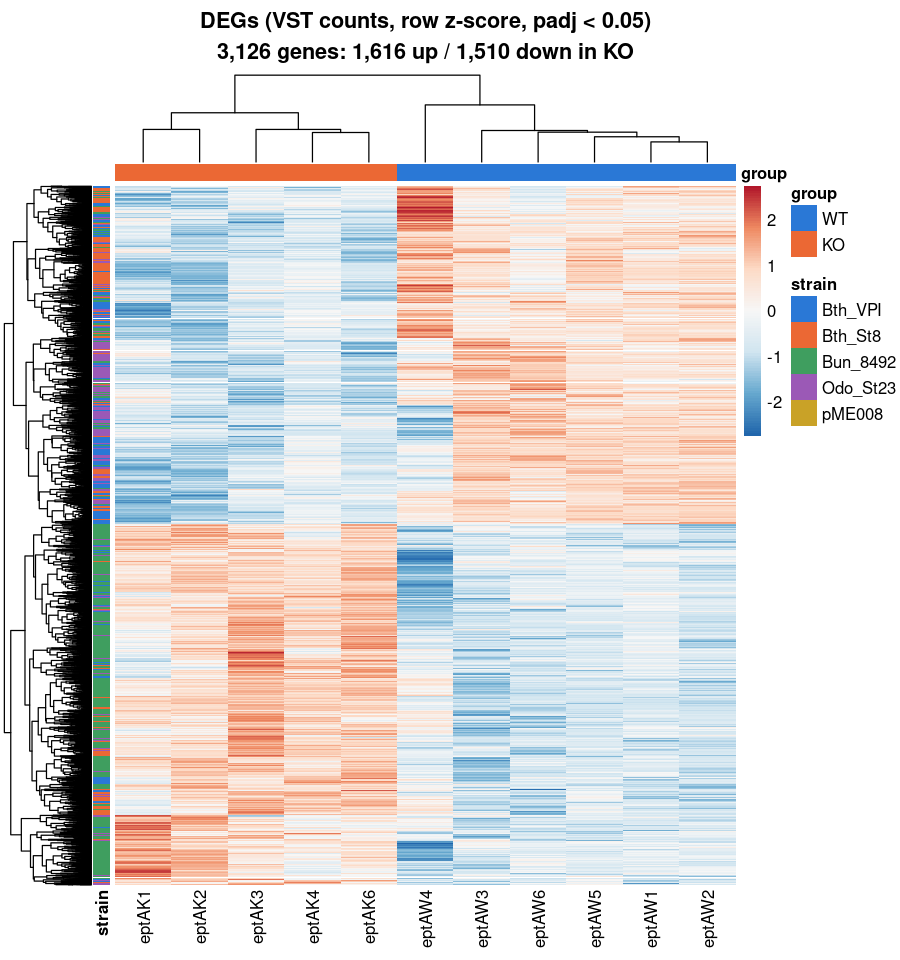

In [16]:
# ── DEG のヒートマップで、解析がうまくいっているかを確認する ───────
# 過去notebook（230313_T19_33mix の 4_DESeq2_allmapped_fractionmode_R.ipynb セル20）
# と同じ手順。
#   VST 変換 → DEG の行だけ取り出す → pheatmap（行ごとに z 化して描く）
#
# ★ VST は blind = TRUE（既定）で行う。
#   群の情報を使わずに分散安定化するので、変換そのものが群を強調することはない。
#   ただし【行の選び方（DEG）は同じデータから決めている】ので、
#   きれいな2ブロックになるのは当たり前。これは「群間差があること」の証拠にはならない。
#
# ★ では何を確認するのか。3点。
#   (1) 検体が群ごとにまとまるか（列のクラスタリング）
#   (2) 外れた検体がないか（ステージ3 で eptAW4 が3つの指標で外れ値だった）
#   (3) 行のまとまりが【株】に対応していないか
#       → 対応していれば、(A) の DEG は株ごとの一律の動きを見ていることになる
library(pheatmap); library(RColorBrewer)

vsd  = varianceStabilizingTransformation(dds, blind = TRUE)
vstc = assay(vsd)

deg_id = de$gene_id[!is.na(de$padj) & de$padj < 0.05]
mat    = vstc[deg_id, ]

# 列（検体）の注釈 = 群、行（遺伝子）の注釈 = 株
ann_col = data.frame(group = coldata$group, row.names = rownames(coldata))
ann_row = data.frame(strain = factor(de$strain[match(deg_id, de$gene_id)]),
                     row.names = deg_id)
ann_colors = list(
    group  = c(WT = '#2a78d6', KO = '#eb6834'),
    strain = c(Bth_VPI = '#2a78d6', Bth_St8 = '#eb6834', Bun_8492 = '#3f9e5f',
               Odo_St23 = '#9b59b6', pME008 = '#c9a227'))

cat(sprintf("■ ヒートマップに載せる DEG: %s 遺伝子 × %d 検体\n",
            format(nrow(mat), big.mark = ','), ncol(mat)))
print(table(ann_row$strain))

options(repr.plot.width = 7.5, repr.plot.height = 8)

pheatmap(mat,
         color = colorRampPalette(rev(brewer.pal(n = 7, name = 'RdBu')))(100),
         scale = 'row',                 # 行ごとに z 化（発現量の絶対値ではなく形を見る）
         cluster_rows = TRUE, cluster_cols = TRUE,
         show_rownames = FALSE,
         annotation_col = ann_col, annotation_row = ann_row,
         annotation_colors = ann_colors,
         border_color = NA, fontsize = 10, angle_col = 90,
         main = sprintf('DEGs (VST counts, row z-score, padj < 0.05)\n%s genes: %s up / %s down in KO',
                        format(nrow(mat), big.mark = ','),
                        format(sum(de$padj < 0.05 & de$LFC_shrunk > 0, na.rm = TRUE), big.mark = ','),
                        format(sum(de$padj < 0.05 & de$LFC_shrunk < 0, na.rm = TRUE), big.mark = ',')))


■ 群内と群間の距離（上のヒートマップの数値）


comparison,n,mean,min,max
<chr>,<int>,<dbl>,<dbl>,<dbl>
WT 群内,15,76.2,36.9,134.1
KO 群内,10,77.3,51.3,110.3
WT vs KO,30,115.0,90.3,156.5


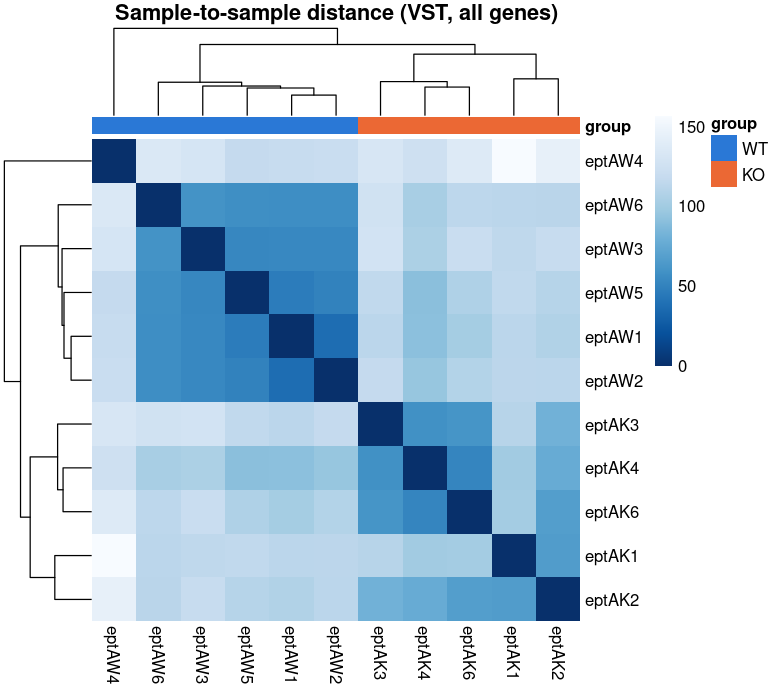

In [17]:
# ── 検体どうしの距離をヒートマップで見る ───────────────────────
# 過去notebook（同 セル33）と同じ。
# ★ こちらは【全遺伝子】を使うので、DEG を選ぶ循環が入らない。
#   検体が群ごとにまとまるかの、より公平な確認になる
sampleDists = dist(t(assay(vsd)))
m = as.matrix(sampleDists)

options(repr.plot.width = 6.5, repr.plot.height = 5.8)

pheatmap(m,
         clustering_distance_rows = sampleDists,
         clustering_distance_cols = sampleDists,
         col = colorRampPalette(rev(brewer.pal(9, 'Blues')))(255),
         annotation_col = ann_col, annotation_colors = ann_colors,
         border_color = NA, fontsize = 10,
         main = 'Sample-to-sample distance (VST, all genes)')

cat("\n■ 群内と群間の距離（上のヒートマップの数値）\n")
g = coldata$group
within_wt = m[g=='WT', g=='WT'][upper.tri(m[g=='WT', g=='WT'])]
within_ko = m[g=='KO', g=='KO'][upper.tri(m[g=='KO', g=='KO'])]
between   = as.vector(m[g=='WT', g=='KO'])
data.frame(
    comparison = c('WT 群内', 'KO 群内', 'WT vs KO'),
    n     = c(length(within_wt), length(within_ko), length(between)),
    mean  = round(c(mean(within_wt), mean(within_ko), mean(between)), 1),
    min   = round(c(min(within_wt), min(within_ko), min(between)), 1),
    max   = round(c(max(within_wt), max(within_ko), max(between)), 1),
    check.names = FALSE)

### 考察: DEG ヒートマップ（セル10図 の結果）

## 結論: 解析は正常に動いている。`eptAW4` は群の中に収まっている

### (1) 検体は群ごとに完全に分かれた

**DEG ヒートマップ**: 列の樹形図が**最上位で KO 5検体 / WT 6検体に分かれる。**

**検体どうしの距離（全遺伝子・循環なし）**: こちらも**最上位で WT / KO に分かれる。**

| 比較 | n | 平均距離 | 最小 | 最大 |
|---|---|---|---|---|
| WT 群内 | 15 | **76.2** | 36.9 | 134.1 |
| KO 群内 | 10 | **77.3** | 51.3 | 110.3 |
| **WT vs KO** | 30 | **115.0** | **90.3** | 156.5 |

**群間の最小距離（90.3）が群内の平均（76〜77）より大きい。**
**DEG を使わない指標でも群が分かれている**ので、これは循環ではない。

### (2) ★ `eptAW4` は WT の中で最も離れているが、群は外れていない

検体距離のヒートマップで、**`eptAW4` は WT の中で単独の枝**になり、
他の WT との距離が最も大きい。

ステージ3 の RLE の IQR（1.37）・PCA の PC2/PC3・Salmon の整合率（95.66%）、
セル5 の size factor のフィルタ感受性（最大のずれ）に続き、**5つ目の独立な指標**。

**ただし KO 側に寄ってはいない。** 除外しない判断は変えず、
**ステージ5 の感度解析（`eptAW4` を除いた再解析）で確認する。**

### (3) 行のまとまりは株に完全対応はしていない

左の `strain` 注釈を見ると、**上のブロック（KO で低下）にも下のブロック（KO で上昇）にも
4株が混ざっている。**

| 株 | DEG 数 |
|---|---|
| Bun_8492 | 1,397 |
| Bth_St8 | 601 |
| Odo_St23 | 592 |
| Bth_VPI | 535 |
| pME008 | 1 |

**「ある株の遺伝子が丸ごと片側に寄る」形ではない。**
ただしセル7 Table 3 のとおり**向きには株ごとの偏りがある**
（`Bun_8492` は 1,173上昇 / 224低下、他3株は低下が優勢）。

→ **(A) の DEG は「株ごとの一律の動き」だけでは説明できない。**
各株の中にも上下両方向の変化がある。**これを (B) で分離する。**

## 注意: このヒートマップで言えないこと

- **「群間差がある」ことの証拠にはならない**（行の選び方が循環）
- **DEG の数（3,126）が多いことの妥当性も、ここでは判断できない**
  → セル7 Table 4 の「株ごとの一律シフト」と (B) との対比で判断する

## セル11: raw / TPM / normalized / VST を並べて検算する

過去notebook（`230313_T19_33mix_metatranscriptome/4_DESeq2_allmapped_fractionmode_R.ipynb`
**セル21-30**）と同じ確認。4つのスケールを同じ検体について並べ、
**正規化が意図どおり効いているか**を見る。

| スケール | 中身 | 期待される性質 |
|---|---|---|
| **raw** | featureCounts の素のカウント | **深さの差がそのまま残る** |
| **TPM** | 遺伝子長と総量で割る | **検体間の総和が 1e6 に揃う** |
| **normalized** | DESeq2 の median-of-ratios（size factor で割る） | 「真ん中の遺伝子」が揃う。**総和は揃わない** |
| **VST** | 分散安定化変換 | **平均と分散の依存が消える** |

### このセル単体でも動くようにしてある

`gtf_count`（セル9 で読む）と `vsd`（セル10 で作る）が無ければ、
**このセルの冒頭で自分で用意する。**
セル9・セル10 を飛ばしても、セル1〜8 まで実行してあれば動く。

### TPM の遺伝子長は GTF から作る

同じ `gene_id` が複数行ある（`_retained` の2区間など）ので**区間長を足し上げる。**
featureCounts も同じ `gene_id` の区間を合算して数えているので、**これが対応する長さ**になる。

### 図の変更点（過去notebook との違い）

| 過去notebook | 今回 | 理由 |
|---|---|---|
| base graphics（`boxplot` / `barplot` / `plot`） | **ggplot2** | ステージ3 からの作図の約束（色・テーマ）をそろえ、PDF/EPS に出しやすくする |
| 図2 を全遺伝子で描く | **フィルタ前の CDS 全部 と フィルタ後 を並べる** | `cnt_de` は prefilter 済みで**ほぼ全遺伝子が検出扱い**になり、図にする意味がないため |
| 図2 を4スケールで描く | **生カウントの1枚** | **raw / TPM / normalized は検出数が完全に一致**（0 は割っても 0）。**VST は 0 も正の値に写すので全遺伝子が検出扱い**になり、指標として意味を持たない |

### 見どころ

- **図1**: `raw` だけ箱の位置がばらつき、`normalized` と `VST` で揃えば正規化は効いている
- **図2**: 検体ごとに検出数が大きく違えば、深さか品質の問題を疑う
- **図3**: **`VST` のパネルだけ傾きが消えていれば**、分散安定化は効いている

In [18]:
# ── raw / TPM / normalized / VST を並べて検算する ──────────────────
# 過去notebook（230313_T19_33mix の 4_DESeq2_allmapped_fractionmode_R.ipynb
# セル21-30）と同じ確認。4つのスケールを同じ検体について並べ、
# 正規化が意図どおり効いているかを見る。
#
#   raw        … featureCounts の素のカウント。深さの差がそのまま残る
#   TPM        … 遺伝子長と総量で割る。検体間の総和が 1e6 に揃う
#   normalized … DESeq2 の median-of-ratios（size factor で割っただけ）
#   VST        … 分散安定化変換。平均と分散の依存を消す
#
# ★ 図は過去notebook の base graphics ではなく ggplot2 で描く。
#   ステージ3 からの作図の約束（色・テーマ）をそろえ、PDF/EPS に出しやすくするため。

# ── このセル単体でも動くように、前段のオブジェクトが無ければ用意する ──
#   gtf_count … セル9 で読む（遺伝子の座標と長さ）
#   vsd       … セル10 で作る（VST 変換した値）
library(stringr)

if (!exists('gtf_count')) {
    gtf_count = read.table(path_gtf_count, sep = "\t", header = FALSE, quote = "",
                           comment.char = "", stringsAsFactors = FALSE)
    colnames(gtf_count) = c('contig','source','feature','start','end',
                            'score','strand','frame','attr')
    gtf_count$gene_id = str_match(gtf_count$attr, '^gene_id "([^"]+)"')[, 2]
    cat("gtf_count を読み込んだ（セル9 未実行のため）\n")
}
if (!exists('vsd')) {
    vsd = varianceStabilizingTransformation(dds, blind = TRUE)
    cat("vsd を作成した（セル10 未実行のため）\n")
}

# ── TPM に必要な遺伝子長を GTF から作る ───────────────────────
# 同じ gene_id が複数行ある（_retained の2区間など）ので、区間長を足し上げる。
# featureCounts も同じ gene_id の区間を合算して数えているので、これが対応する長さ
gene_len = gtf_count %>%
    mutate(len = end - start + 1) %>%
    group_by(gene_id) %>%
    summarise(length = sum(len), .groups = 'drop')

len_v = gene_len$length[match(rownames(cnt_de), gene_len$gene_id)]
stopifnot(!any(is.na(len_v)))

# ── 4つのスケールを作る ────────────────────────────────────────
raw_m  = as.matrix(cnt_de)
rpk    = raw_m / (len_v / 1000)                       # reads per kilobase
tpm_m  = t(t(rpk) * 1e6 / colSums(rpk))               # 総和を 1e6 に揃える
norm_m = counts(dds, normalized = TRUE)
vst_m  = assay(vsd)

cat("■ Table 1: 4つのスケールの検体ごとの総和（正規化が効いているかの確認）\n")
data.frame(
    sample     = colnames(raw_m),
    group      = as.character(coldata$group),
    raw_M      = round(colSums(raw_m) / 1e6, 2),
    TPM_sum    = round(colSums(tpm_m)),
    norm_M     = round(colSums(norm_m) / 1e6, 2),
    VST_median = round(apply(vst_m, 2, median), 2),
    row.names = NULL, check.names = FALSE)
cat("   TPM_sum が全検体 1,000,000 なら TPM の計算は正しい\n")
cat("   norm_M は揃わない（median-of-ratios は「真ん中の遺伝子」を揃える方式。セル5 参照）\n")

■ Table 1: 4つのスケールの検体ごとの総和（正規化が効いているかの確認）


sample,group,raw_M,TPM_sum,norm_M,VST_median
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,25.33,1e+06,27.11,7.41
eptAW2,WT,21.95,1e+06,26.47,7.41
eptAW3,WT,19.07,1e+06,25.54,7.43
eptAW4,WT,21.93,1e+06,22.70,7.47
eptAW5,WT,27.79,1e+06,24.95,7.45
eptAW6,WT,16.23,1e+06,24.68,7.41
eptAK1,KO,23.07,1e+06,28.05,7.36
eptAK2,KO,18.16,1e+06,19.90,7.38
eptAK3,KO,42.89,1e+06,18.20,7.49


   TPM_sum が全検体 1,000,000 なら TPM の計算は正しい
   norm_M は揃わない（median-of-ratios は「真ん中の遺伝子」を揃える方式。セル5 参照）


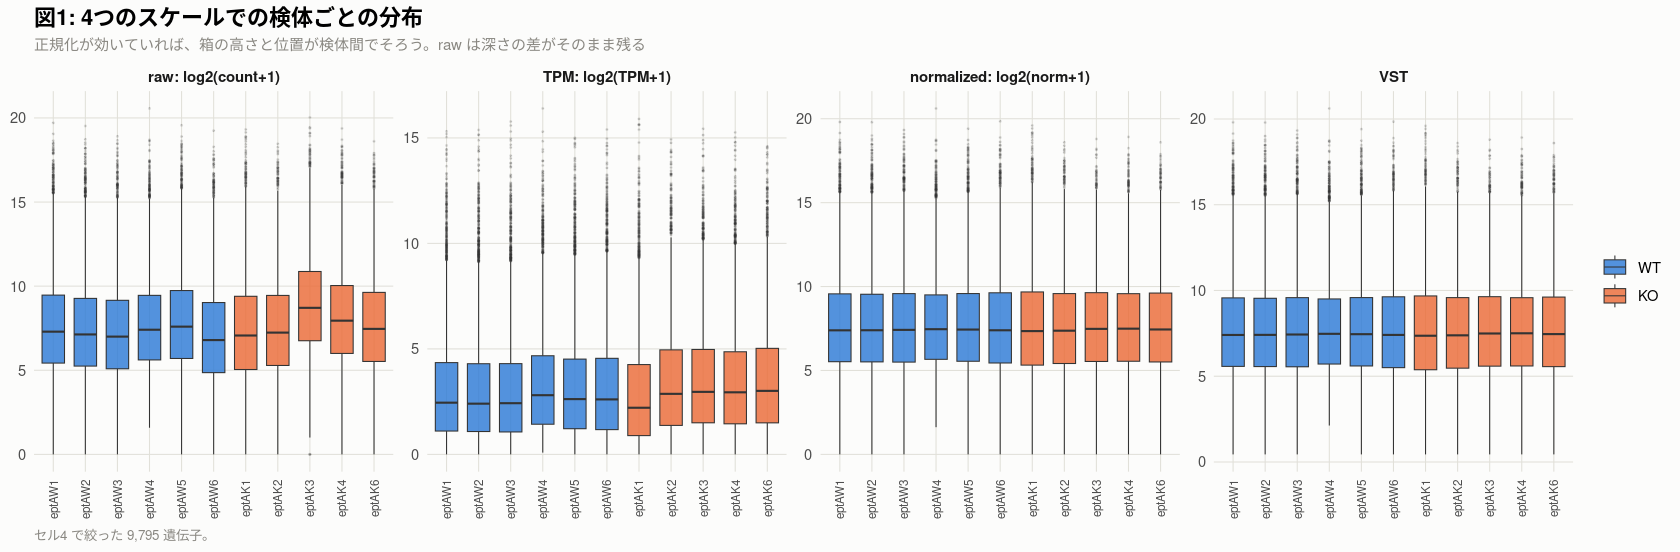

`geom_smooth()` using formula = 'y ~ x'


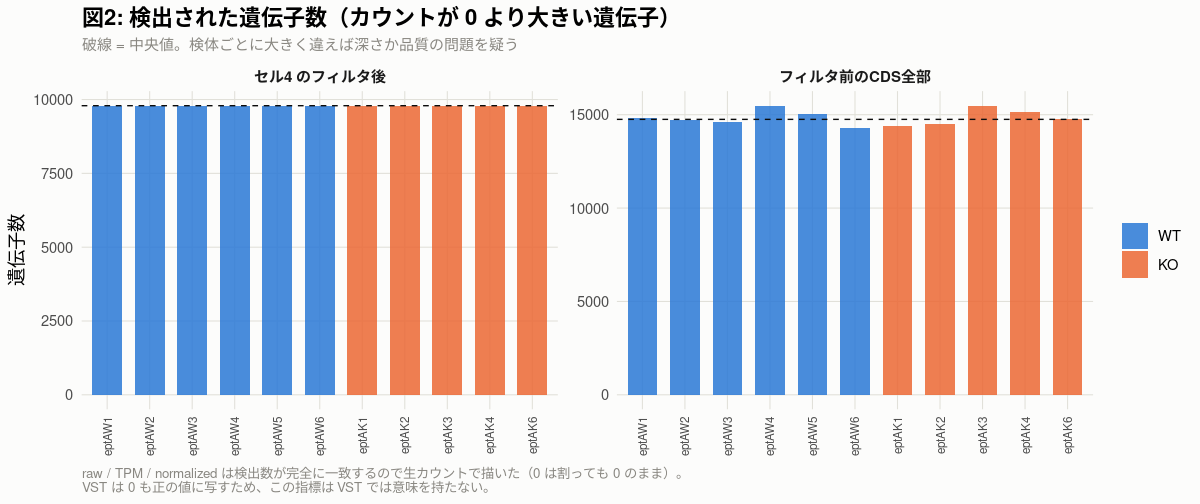

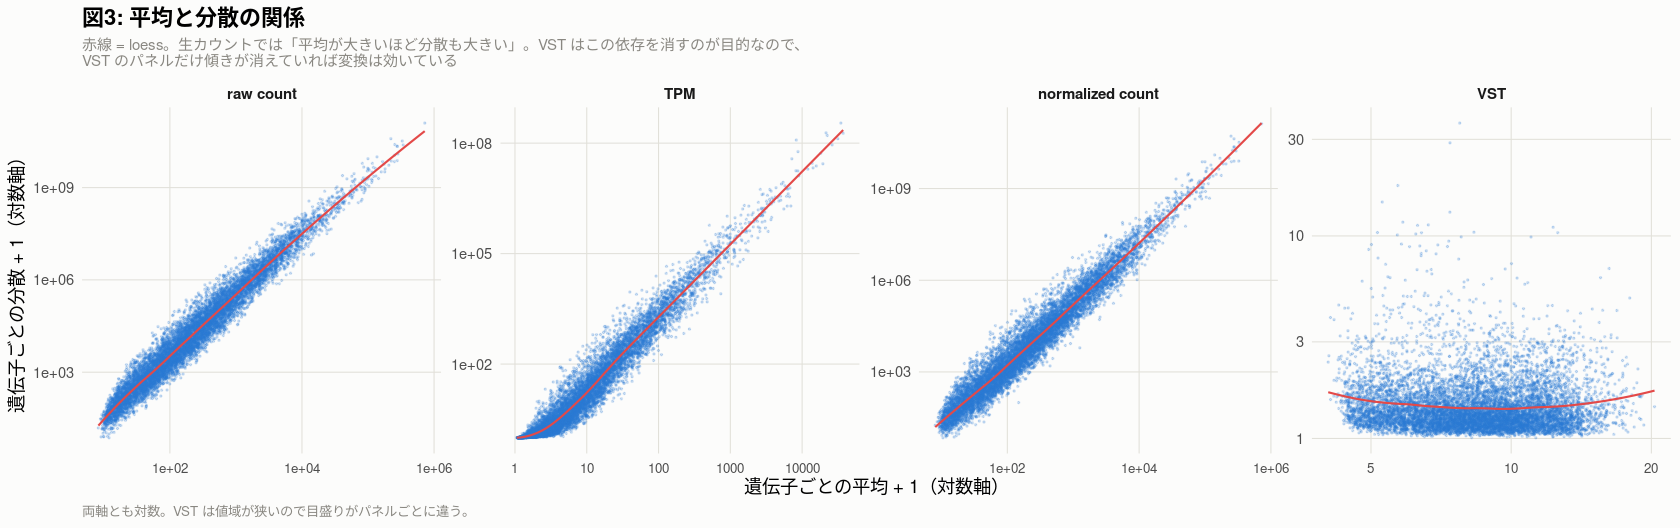

In [19]:
# ── 4つのスケールを図で比べる ───────────────────────────────────
# 過去notebook セル28-30 に対応（base graphics → ggplot2 に置き換え）
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_group = c(WT = '#2a78d6', KO = '#eb6834')
thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 7),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

sc_lv = c('raw: log2(count+1)', 'TPM: log2(TPM+1)',
          'normalized: log2(norm+1)', 'VST')

long = rbind(
  data.frame(scale = sc_lv[1], sample = rep(colnames(raw_m),  each = nrow(raw_m)),
             value = as.vector(log2(raw_m  + 1))),
  data.frame(scale = sc_lv[2], sample = rep(colnames(tpm_m),  each = nrow(tpm_m)),
             value = as.vector(log2(tpm_m  + 1))),
  data.frame(scale = sc_lv[3], sample = rep(colnames(norm_m), each = nrow(norm_m)),
             value = as.vector(log2(norm_m + 1))),
  data.frame(scale = sc_lv[4], sample = rep(colnames(vst_m),  each = nrow(vst_m)),
             value = as.vector(vst_m))) %>%
  mutate(scale  = factor(scale, levels = sc_lv),
         sample = factor(sample, levels = colnames(raw_m)),
         group  = coldata$group[match(sample, rownames(coldata))])

# ── 図1: 検体ごとの分布 ────────────────────────────────────────
options(repr.plot.width = 14, repr.plot.height = 4.6)
p1 = ggplot(long, aes(x = sample, y = value, fill = group)) +
    geom_boxplot(outlier.size = 0.2, outlier.alpha = 0.15,
                 linewidth = 0.3, width = 0.7, alpha = 0.8) +
    scale_fill_manual(values = col_group, name = NULL) +
    facet_wrap(~ scale, nrow = 1, scales = 'free_y') +
    labs(title = '図1: 4つのスケールでの検体ごとの分布',
         subtitle = paste0('正規化が効いていれば、箱の高さと位置が検体間でそろう。',
                           'raw は深さの差がそのまま残る'),
         x = NULL, y = NULL,
         caption = sprintf('セル4 で絞った %s 遺伝子。',
                           format(nrow(raw_m), big.mark = ','))) + thm
suppressWarnings(print(p1))

# ── 図2: 検出された遺伝子数 ────────────────────────────────────
# 過去notebook セル29 に対応。ただし過去は【フィルタ前の全遺伝子】で描いていた。
#   ・今回の cnt_de は prefilter 済み（count>=10 を5検体以上）なので、
#     ほぼ全遺伝子がどの検体でも検出扱いになり、図にする意味がない
#   ・そこで【フィルタ前の CDS 全部】で描く。検体ごとに検出数が大きく違えば
#     深さか品質の問題を疑う
#
# ★ raw / TPM / normalized は検出数が完全に一致する（0 は割っても 0 のまま）。
#   VST は 0 も正の値に写すので全遺伝子が検出扱いになる。
#   → 4スケールを並べる意味がないので、生カウントの1枚にする
cds_all = as.matrix(cnt_q10[feat$gene_id[feat$biotype == 'CDS'], ])

det = data.frame(
    sample = factor(colnames(cds_all), levels = colnames(cds_all)),
    group  = coldata$group,
    `フィルタ前のCDS全部` = colSums(cds_all > 0),
    `セル4 のフィルタ後`  = colSums(as.matrix(cnt_de) > 0),
    check.names = FALSE) %>%
    tidyr::pivot_longer(c(`フィルタ前のCDS全部`, `セル4 のフィルタ後`),
                        names_to = 'set', values_to = 'n')

options(repr.plot.width = 10, repr.plot.height = 4.2)
p2 = ggplot(det, aes(x = sample, y = n, fill = group)) +
    geom_col(alpha = 0.85, width = 0.7) +
    geom_hline(data = det %>% group_by(set) %>%
                   summarise(m = median(n), .groups = 'drop'),
               aes(yintercept = m), linetype = 'dashed',
               colour = col_text, linewidth = 0.4) +
    scale_fill_manual(values = col_group, name = NULL) +
    facet_wrap(~ set, nrow = 1, scales = 'free_y') +
    labs(title = '図2: 検出された遺伝子数（カウントが 0 より大きい遺伝子）',
         subtitle = '破線 = 中央値。検体ごとに大きく違えば深さか品質の問題を疑う',
         x = NULL, y = '遺伝子数',
         caption = paste0('raw / TPM / normalized は検出数が完全に一致するので生カウントで描いた',
                          '（0 は割っても 0 のまま）。\n',
                          'VST は 0 も正の値に写すため、この指標は VST では意味を持たない。')) + thm
suppressWarnings(print(p2))

# ── 図3: 平均と分散の関係（VST の効き目）──────────────────────
# 生カウントでは「平均が大きい遺伝子ほど分散も大きい」。
# VST はこの依存を消すのが目的なので、VST のパネルだけ傾きが消えるはず
# ★ ここは【変換前の値】の平均と分散を見る（図1 の log2 とは別物なのでラベルも変える）
mv_lv = c('raw count', 'TPM', 'normalized count', 'VST')
mv = rbind(
  data.frame(scale = mv_lv[1], mean = rowMeans(raw_m),  var = apply(raw_m, 1, var)),
  data.frame(scale = mv_lv[2], mean = rowMeans(tpm_m),  var = apply(tpm_m, 1, var)),
  data.frame(scale = mv_lv[3], mean = rowMeans(norm_m), var = apply(norm_m, 1, var)),
  data.frame(scale = mv_lv[4], mean = rowMeans(vst_m),  var = apply(vst_m, 1, var))) %>%
  mutate(scale = factor(scale, levels = mv_lv))

options(repr.plot.width = 14, repr.plot.height = 4.4)
p3 = ggplot(mv, aes(x = mean + 1, y = var + 1)) +
    geom_point(size = 0.3, alpha = 0.2, colour = '#2a78d6') +
    geom_smooth(method = 'loess', se = FALSE, colour = '#e34948',
                linewidth = 0.6, span = 0.5) +
    scale_x_log10() + scale_y_log10() +
    facet_wrap(~ scale, nrow = 1, scales = 'free') +
    labs(title = '図3: 平均と分散の関係',
         subtitle = paste0('赤線 = loess。生カウントでは「平均が大きいほど分散も大きい」。',
                           'VST はこの依存を消すのが目的なので、\n',
                           'VST のパネルだけ傾きが消えていれば変換は効いている'),
         x = '遺伝子ごとの平均 + 1（対数軸）', y = '遺伝子ごとの分散 + 1（対数軸）',
         caption = '両軸とも対数。VST は値域が狭いので目盛りがパネルごとに違う。') + thm +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5, size = 8))
suppressWarnings(print(p3))

### 考察: 4つのスケールの比較（セル11 の結果）

## 結論: 正規化も分散安定化も意図どおり効いている

### 表1 — 計算が正しいことの確認

| 確認 | 結果 |
|---|---|
| **TPM の総和** | **全11検体で 1,000,000 ちょうど** → TPM の計算は正しい |
| **normalized の総和** | **揃わない**（18.2〜28.1 M）。median-of-ratios は「真ん中の遺伝子」を揃える方式なので、これが正しい挙動（セル5 と同じ理由） |
| **VST の中央値** | 7.36〜7.50 と**ほぼ一定** |

### 図1 — raw だけがばらつく

`raw` では **`eptAK3` の箱が明らかに高く、`eptAW6` が低い**（深さの差）。
`normalized` と `VST` ではこれが消えて検体間でそろう。

**`TPM` も総量は揃うが、群間で中央値がわずかにずれている**
（WT ≈ 2.6 / KO ≈ 3.1）。これは**組成の違いが残る**ため。
TPM は検体内の相対量なので、**群間比較には使わない**（DE は生カウント + size factor）。

### 図2 — 検出遺伝子数に大きな外れはない

**フィルタ前の CDS 全部**（17,918 遺伝子）で 13,800〜15,400。
`eptAW4` と `eptAK3` がやや多く、`eptAW6` と `eptAK1` がやや少ないが、
**深さの順とおおむね一致**しており、品質の問題を示す外れ方ではない。

**セル4 のフィルタ後**はほぼ全遺伝子が検出扱い（9,795 のうち 9,700 以上）。
prefilter が効いていることの確認になる。

### 図3 — ★ VST は効いている

`raw` / `TPM` / `normalized` はいずれも
**「平均が大きい遺伝子ほど分散も大きい」**という強い傾きを示す（対数軸でほぼ直線）。

**`VST` のパネルだけ傾きが消え、ほぼ水平**になる。
→ **分散安定化が効いている。** PCA・ヒートマップ・検体距離に VST を使う前提が成り立つ。

**※ VST のパネルがわずかに U 字**なのは、
低発現側で分散が残り、高発現側で少数の外れ値が効いているため。
DESeq2 の VST では通常見られる形で、問題ではない。

## どのスケールを何に使うか（確定）

| 用途 | 使うもの | 理由 |
|---|---|---|
| **DE 検定** | **生カウント + size factor** | CLAUDE.md §6-2。変換したカウントを渡さない |
| **PCA・ヒートマップ・検体距離** | **VST** | 平均と分散の依存が消えているため |
| 発現量の提示（表・個別遺伝子の図） | **normalized counts** | 元のカウントのスケールが保たれる |
| **群間比較には使わない** | **TPM** | 検体内の相対量。組成の違いが残る |

## セル12: VST で PCA をかけて全体を確認する

過去notebook（`230313_T19_33mix` の `4_DESeq2_allmapped_fractionmode_R.ipynb`
**セル34-35**）と同じ手順。

```
prcomp(t(VSTカウント)) → 寄与率 → PC1-PC2 / PC2-PC3 → PC1 を決めている遺伝子
```

### `plotPCA` ではなく `prcomp` を使う

**DESeq2 の `plotPCA` は分散上位500遺伝子だけ**を使う。
過去notebook は `prcomp` で**全遺伝子**を使っていたので、そちらに合わせる。

### ★ 確認すること

| 確認 | 見るところ |
|---|---|
| **PC1 は群を分けるか** | Table 3 の `p_group` |
| **★ PC1 は技術的な artifact でないか** | Table 3 の `r_sizefactor`。**強ければ深さを見ている** |
| PC1 を決めているのは何か | Table 4・5 の loading、Table 6 の株の内訳 |
| **マーカーが PC1 を作っていないか** | Table 7。**除いた版との PC1 の相関** |

ステージ3 セル15-9 では、**`log2(count+1)` の PCA は PC1 が size factor と
r = +0.940 で相関する技術的な artifact** だった。VST にすると消えた。**ここでも同じ確認をする。**

### マーカーを除いた版も作る

Table 5 のとおり、**PC1 の負側の上位4件は eptA の `_deleted` / `_3p` そのもの。**
これは「KO で欠失している」という**設計どおりの差**であって、発現制御の差ではない。

ステージ3 セル15-9 と同じく、**除かない版と除いた版の2つ**を作って比べる。

### 図の構成（3枚）

**facet では軸ごとに軸タイトルを変えられない**ので、
**PC1 vs PC2** と **PC2 vs PC3** を別の図にして、**軸タイトルに PC と寄与率を明記する。**

| 図 | 中身 |
|---|---|
| 図1 | 各主成分の寄与率（過去notebook セル34 の barplot に対応） |
| **図2** | **PC1 vs PC2**（左 = マーカーを含む、右 = 除く） |
| **図3** | **PC2 vs PC3**（同上） |

2版の寄与率はサブタイトルに併記してある（パネル見出しに入れると長すぎて切れるため）。


In [20]:
# ── VST で PCA をかけて全体を確認する ──────────────────────────
# 過去notebook（230313_T19_33mix の 4_DESeq2_allmapped_fractionmode_R.ipynb
# セル34-35）と同じ手順。
#   prcomp(t(VSTカウント)) → 寄与率 → PC1-PC2 / PC2-PC3 → PC1 を決めている遺伝子
#
# ★ DESeq2 の plotPCA は【分散上位500遺伝子だけ】を使う。
#   過去notebook は prcomp で【全遺伝子】を使っていたので、そちらに合わせる。
#
# ★ ステージ3 セル15-9 で、log2(count+1) の PCA は
#   PC1 が size factor と r = +0.940 で相関する技術的な artifact だった。
#   VST にすると消えた。ここでも同じ確認をする。
if (!exists('vsd')) vsd = varianceStabilizingTransformation(dds, blind = TRUE)
vstc = assay(vsd)

pca = prcomp(t(vstc))                      # center = TRUE, scale. = FALSE（prcomp の既定）
ve  = round(100 * pca$sdev^2 / sum(pca$sdev^2), 2)

cat("■ Table 1: 各主成分の寄与率\n")
data.frame(PC = paste0('PC', seq_along(ve)),
           variance_pct = ve,
           cumulative_pct = round(cumsum(ve), 2),
           row.names = NULL)[1:min(8, length(ve)), ]

cat("\n■ Table 2: 検体ごとの主成分得点\n")
data.frame(sample = rownames(pca$x),
           group  = as.character(coldata$group),
           PC1 = round(pca$x[, 1], 1), PC2 = round(pca$x[, 2], 1),
           PC3 = round(pca$x[, 3], 1),
           row.names = NULL)

# ── ★ PC1 が技術的な artifact でないかの確認 ──────────────────
# size factor（＝深さ）と相関していたら、生物学ではなく深さを見ていることになる
cat("\n■ Table 3: 各主成分と、群・size factor との関係\n")
cat("   群との差 … Wilcoxon 順位和検定（n=6 vs 5 なので最小 p は 0.0043）\n")
cat("   size factor との相関 … 強ければその主成分は深さを見ている（artifact）\n")
sf = sizeFactors(dds); is_wt = coldata$group == 'WT'
do.call(rbind, lapply(1:4, function(i) {
    v = pca$x[, i]
    data.frame(PC = paste0('PC', i), variance_pct = ve[i],
               WT_mean = round(mean(v[is_wt]), 1),
               KO_mean = round(mean(v[!is_wt]), 1),
               p_group = round(suppressWarnings(
                   wilcox.test(v[is_wt], v[!is_wt])$p.value), 4),
               r_sizefactor = round(cor(v, sf), 3),
               p_sizefactor = round(cor.test(v, sf)$p.value, 4))
}))

# ── PC1 を決めている遺伝子（過去notebook セル35）────────────────
cat("\n■ Table 4: PC1 への寄与が大きい上位20遺伝子（PC1 が正の側）\n")
ld = data.frame(gene_id = rownames(pca$rotation),
                PC1 = pca$rotation[, 1], PC2 = pca$rotation[, 2]) %>%
     left_join(de %>% dplyr::select(gene_id, strain, product, LFC_shrunk, padj),
               by = 'gene_id')
ld %>% arrange(desc(PC1)) %>% head(20) %>%
    mutate(PC1 = round(PC1, 4), LFC_shrunk = round(LFC_shrunk, 2),
           padj = signif(padj, 2), product = substr(product, 1, 40)) %>%
    dplyr::select(gene_id, strain, PC1, LFC_shrunk, padj, product)

cat("\n■ Table 5: PC1 への寄与が大きい上位20遺伝子（PC1 が負の側）\n")
ld %>% arrange(PC1) %>% head(20) %>%
    mutate(PC1 = round(PC1, 4), LFC_shrunk = round(LFC_shrunk, 2),
           padj = signif(padj, 2), product = substr(product, 1, 40)) %>%
    dplyr::select(gene_id, strain, PC1, LFC_shrunk, padj, product)

cat("\n■ Table 6: |PC1| 上位200遺伝子の株の内訳\n")
cat("   特定の1株で占められていたら、PC1 はその株の動きを見ていることになる\n")
thr = quantile(abs(ld$PC1), 1 - 200 / nrow(ld))
ld %>% mutate(top200 = abs(PC1) >= thr) %>%
    group_by(strain) %>%
    summarise(genes = dplyr::n(),
              in_top200 = sum(top200),
              pct_of_top200 = round(100 * sum(top200) / sum(ld$PC1 >= thr | ld$PC1 <= -thr), 1),
              .groups = 'drop') %>% as.data.frame()

■ Table 1: 各主成分の寄与率


,PC,variance_pct,cumulative_pct
,<chr>,<dbl>,<dbl>
1,PC1,42.96,42.96
2,PC2,26.10,69.06
3,PC3,12.89,81.95
4,PC4,4.39,86.34
5,PC5,3.24,89.58
6,PC6,3.00,92.58
7,PC7,2.60,95.18
8,PC8,2.15,97.33



■ Table 2: 検体ごとの主成分得点


sample,group,PC1,PC2,PC3
<chr>,<chr>,<dbl>,<dbl>,<dbl>
eptAW1,WT,-38.5,8.2,11.2
eptAW2,WT,-43.8,9.5,7.4
eptAW3,WT,-51.2,20.7,1.0
eptAW4,WT,-23.8,-96.1,-35.3
eptAW5,WT,-41.2,5.2,10.3
eptAW6,WT,-43.5,26.2,3.4
eptAK1,KO,39.0,44.5,-52.6
eptAK2,KO,55.0,19.6,-21.4
eptAK3,KO,58.9,-22.6,25.8



■ Table 3: 各主成分と、群・size factor との関係
   群との差 … Wilcoxon 順位和検定（n=6 vs 5 なので最小 p は 0.0043）
   size factor との相関 … 強ければその主成分は深さを見ている（artifact）


PC,variance_pct,WT_mean,KO_mean,p_group,r_sizefactor,p_sizefactor
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PC1,42.96,-40.3,48.4,0.0043,0.525,0.0974
PC2,26.10,-4.4,5.3,0.7922,-0.329,0.3226
PC3,12.89,-0.3,0.4,0.5368,0.451,0.1641
PC4,4.39,-0.7,0.9,0.6623,0.448,0.1666


... (2 outputs left out)


■ Table 5: PC1 への寄与が大きい上位20遺伝子（PC1 が負の側）


,gene_id,strain,PC1,LFC_shrunk,padj,product
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
1,NQ510_RS14730_deleted,Bun_8492,-0.1203,-14.61,2.3e-40,eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）
2,CE91St8_20540_deleted,Bth_St8,-0.1090,-12.51,2.3e-40,eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）
3,BT_RS09185_deleted,Bth_VPI,-0.0853,-13.16,2.0e-28,eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）
4,CE91St23_40970_3p,Odo_St23,-0.0771,-12.34,1.7e-23,eptA: 挿入点より3'側（K群でゼロなら転写終結）
5,CE91St8_37650,Bth_St8,-0.0539,-5.69,3.4e-28,UDP-glucose dehydrogenase
6,CE91St23_44470,Odo_St23,-0.0486,-4.79,1.2e-06,hypothetical protein
7,CE91St8_37680,Bth_St8,-0.0474,-4.75,1.6e-23,transcriptional regulator
8,CE91St8_09700,Bth_St8,-0.0469,-3.85,1.0e-14,cysteine synthase
9,BT_RS15610,Bth_VPI,-0.0453,-3.88,8.7e-19,cysteine synthase A



■ Table 6: |PC1| 上位200遺伝子の株の内訳
   特定の1株で占められていたら、PC1 はその株の動きを見ていることになる


strain,genes,in_top200,pct_of_top200
<chr>,<int>,<int>,<dbl>
Bth_St8,1830,103,51.5
Bth_VPI,1712,21,10.5
Bun_8492,3392,15,7.5
Odo_St23,2851,61,30.5
pME008,10,0,0.0


■ Table 7: マーカーを除くと PCA はどう変わるか


version,genes,PC1_pct,PC2_pct,PC3_pct,PC1_p_group
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
マーカーを含む,9795,42.96,26.10,12.89,0.0043
マーカーを除く,9788,42.00,26.51,13.12,0.0043


   2版の PC1 得点の相関: r = 0.9998
   相関が 1 に近ければ、マーカー7件は PC1 の向きを決めていない


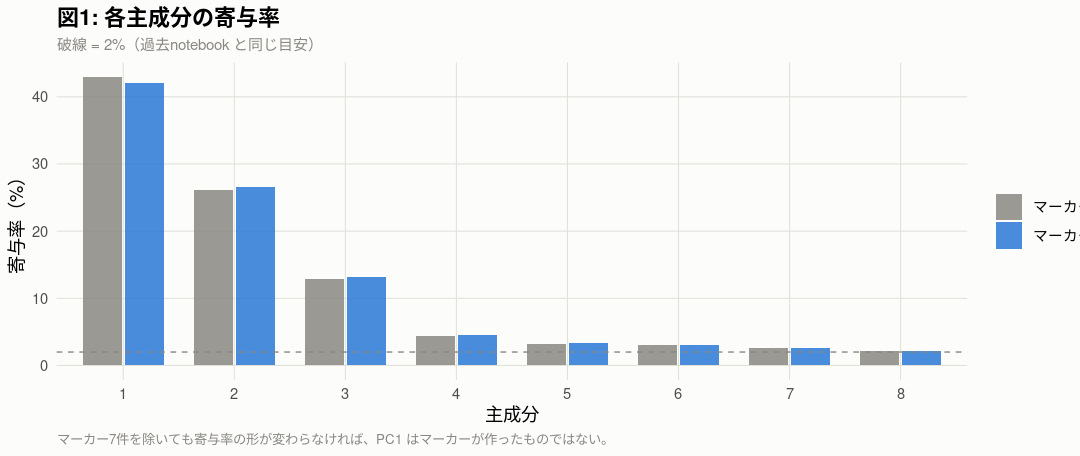

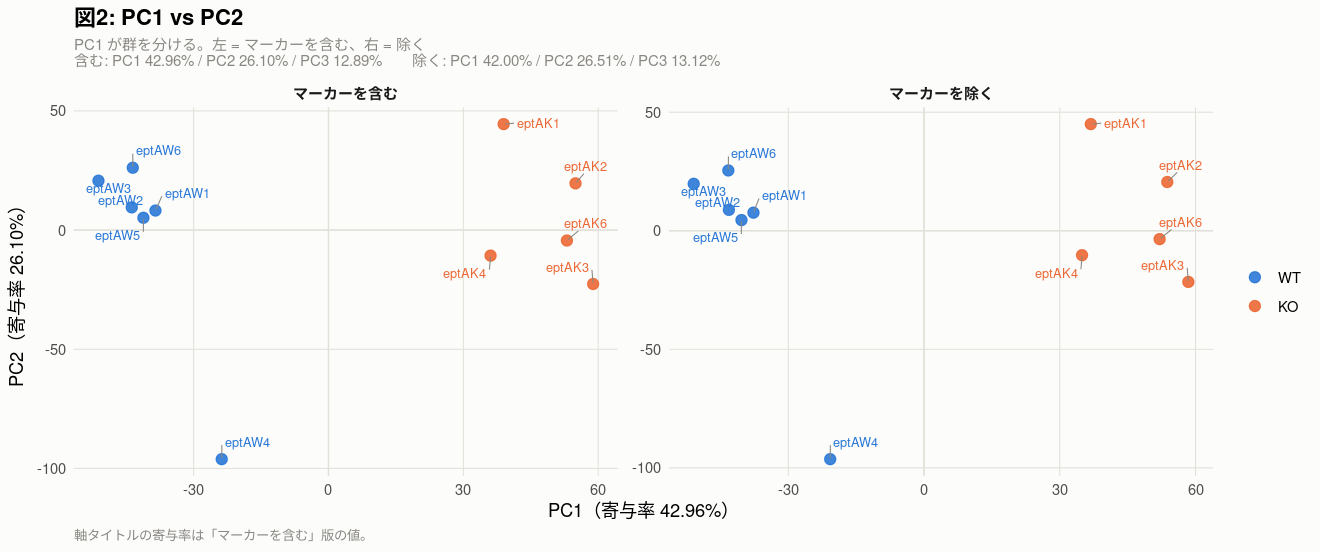

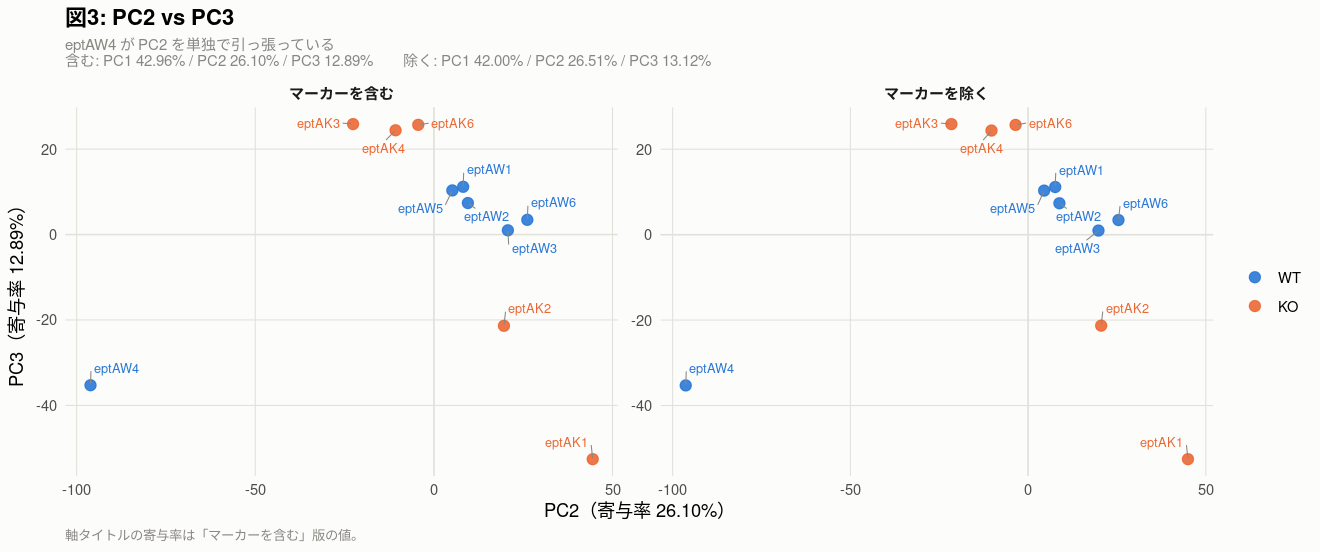

In [21]:
# ── 遺伝子型マーカーを除いた PCA も作る ─────────────────────────
# Table 5 のとおり、PC1 の負側の上位4件は eptA の _deleted / _3p そのもの。
# これは「KO で欠失している」という設計どおりの差で、発現制御の差ではない。
# ステージ3 セル15-9 と同じく【除かない版】と【除いた版】の2つを作って比べる
pca_ex = prcomp(t(vstc[!de$marker[match(rownames(vstc), de$gene_id)], ]))
ve_ex  = round(100 * pca_ex$sdev^2 / sum(pca_ex$sdev^2), 2)

cat("■ Table 7: マーカーを除くと PCA はどう変わるか\n")
rbind(
  data.frame(version = 'マーカーを含む', genes = nrow(vstc),
             PC1_pct = ve[1], PC2_pct = ve[2], PC3_pct = ve[3],
             PC1_p_group = round(suppressWarnings(
                 wilcox.test(pca$x[is_wt,1], pca$x[!is_wt,1])$p.value), 4)),
  data.frame(version = 'マーカーを除く', genes = nrow(pca_ex$rotation),
             PC1_pct = ve_ex[1], PC2_pct = ve_ex[2], PC3_pct = ve_ex[3],
             PC1_p_group = round(suppressWarnings(
                 wilcox.test(pca_ex$x[is_wt,1], pca_ex$x[!is_wt,1])$p.value), 4)))
cat(sprintf("   2版の PC1 得点の相関: r = %.4f\n",
            abs(cor(pca$x[,1], pca_ex$x[,1]))))
cat("   相関が 1 に近ければ、マーカー7件は PC1 の向きを決めていない\n")

# ── 図 ─────────────────────────────────────────────────────────
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_group = c(WT = '#2a78d6', KO = '#eb6834')
thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# 図1: 寄与率（過去notebook セル34 の barplot に対応）
scree = rbind(
  data.frame(version = 'マーカーを含む', PC = seq_along(ve),    pct = ve),
  data.frame(version = 'マーカーを除く', PC = seq_along(ve_ex), pct = ve_ex)) %>%
  filter(PC <= 8) %>%
  mutate(version = factor(version, levels = c('マーカーを含む','マーカーを除く')))

options(repr.plot.width = 9, repr.plot.height = 3.8)
p1 = ggplot(scree, aes(x = factor(PC), y = pct, fill = version)) +
    geom_col(position = position_dodge(width = 0.75), width = 0.7, alpha = 0.85) +
    geom_hline(yintercept = 2, linetype = 'dashed', colour = col_muted, linewidth = 0.4) +
    scale_fill_manual(values = c('マーカーを含む' = '#898781',
                                 'マーカーを除く' = '#2a78d6'), name = NULL) +
    labs(title = '図1: 各主成分の寄与率',
         subtitle = '破線 = 2%（過去notebook と同じ目安）',
         x = '主成分', y = '寄与率（%）',
         caption = 'マーカー7件を除いても寄与率の形が変わらなければ、PC1 はマーカーが作ったものではない。') + thm
suppressWarnings(print(p1))

# 図2・図3: 主成分得点（過去notebook セル34 の plot に対応）
#   ★ facet では軸ごとに軸タイトルを変えられないので、
#     【PC1 vs PC2】と【PC2 vs PC3】を別の図にして、軸タイトルを明記する
strip = c('マーカーを含む', 'マーカーを除く')
# 2版の寄与率はサブタイトルに書く（見出しに入れると長すぎて切れる）
sub_ve = sprintf('含む: PC1 %.2f%% / PC2 %.2f%% / PC3 %.2f%%　　除く: PC1 %.2f%% / PC2 %.2f%% / PC3 %.2f%%',
                 ve[1], ve[2], ve[3], ve_ex[1], ve_ex[2], ve_ex[3])

sc = rbind(
  data.frame(version = strip[1], PC1 = pca$x[,1],    PC2 = pca$x[,2],    PC3 = pca$x[,3]),
  data.frame(version = strip[2], PC1 = pca_ex$x[,1], PC2 = pca_ex$x[,2], PC3 = pca_ex$x[,3])) %>%
  mutate(sample = rep(rownames(pca$x), 2),
         group  = rep(coldata$group, 2),
         version = factor(version, levels = strip))

# 共通の描き方（軸だけ差し替える）
pc_plot = function(xv, yv, xlab, ylab, ttl, sub, cap) {
    ggplot(sc, aes(x = .data[[xv]], y = .data[[yv]], colour = group)) +
        geom_hline(yintercept = 0, colour = col_grid, linewidth = 0.4) +
        geom_vline(xintercept = 0, colour = col_grid, linewidth = 0.4) +
        geom_point(size = 2.8, alpha = 0.9) +
        ggrepel::geom_text_repel(aes(label = sample), size = 2.7, seed = 1,
                                 min.segment.length = 0, segment.colour = col_muted,
                                 segment.size = 0.3, box.padding = 0.45,
                                 show.legend = FALSE) +
        scale_colour_manual(values = col_group, name = NULL) +
        facet_wrap(~ version, nrow = 1, scales = 'free') +
        labs(title = ttl, subtitle = sub, x = xlab, y = ylab, caption = cap) + thm
}

options(repr.plot.width = 11, repr.plot.height = 4.6)
suppressWarnings(print(pc_plot(
  'PC1', 'PC2',
  sprintf('PC1（寄与率 %.2f%%）', ve[1]), sprintf('PC2（寄与率 %.2f%%）', ve[2]),
  '図2: PC1 vs PC2',
  paste0('PC1 が群を分ける。左 = マーカーを含む、右 = 除く\n', sub_ve),
  '軸タイトルの寄与率は「マーカーを含む」版の値。')))

options(repr.plot.width = 11, repr.plot.height = 4.6)
suppressWarnings(print(pc_plot(
  'PC2', 'PC3',
  sprintf('PC2（寄与率 %.2f%%）', ve[2]), sprintf('PC3（寄与率 %.2f%%）', ve[3]),
  '図3: PC2 vs PC3',
  paste0('eptAW4 が PC2 を単独で引っ張っている\n', sub_ve),
  '軸タイトルの寄与率は「マーカーを含む」版の値。')))

## セル12図（英語版）: PCA

**中身はセル12図 と同じ3枚で、文字だけ英語にしたもの。**
PDF / EPS に出すときの文字化けを避けるため（セル8図 英語版 と同じ理由）。

```r
ggsave('fig_PCA_scree.pdf',   p1_pca_en, width =  9, height = 3.8)
ggsave('fig_PCA_PC1PC2.pdf',  p2_pca_en, width = 11, height = 4.6)
ggsave('fig_PCA_PC2PC3.pdf',  p3_pca_en, width = 11, height = 4.6)
```

| 変数 | 図 |
|---|---|
| `p1_pca_en` | Fig 1: Variance explained by each principal component |
| `p2_pca_en` | Fig 2: PC1 vs PC2 |
| `p3_pca_en` | Fig 3: PC2 vs PC3 |

| 日本語版 | 英語版 |
|---|---|
| マーカーを含む / 除く | `with genotype markers` / `markers excluded` |
| 寄与率 | `% of variance` |

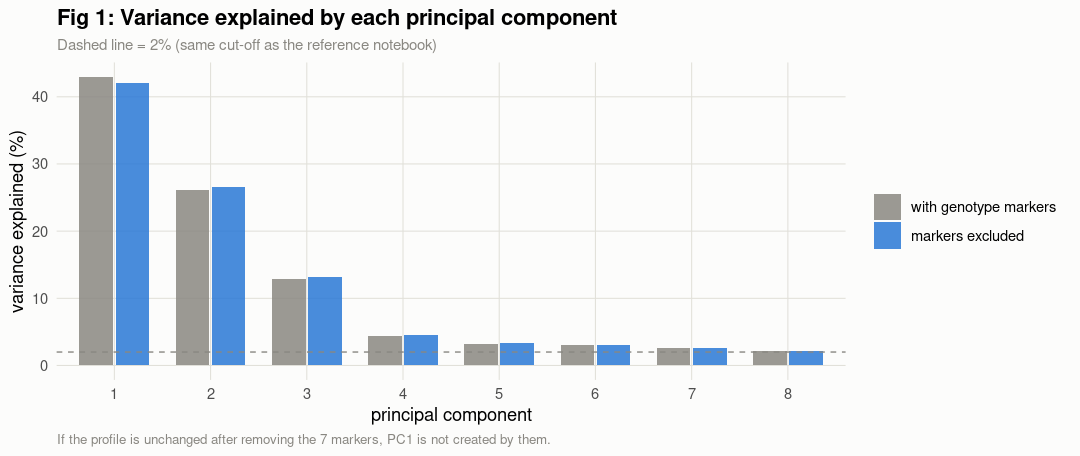

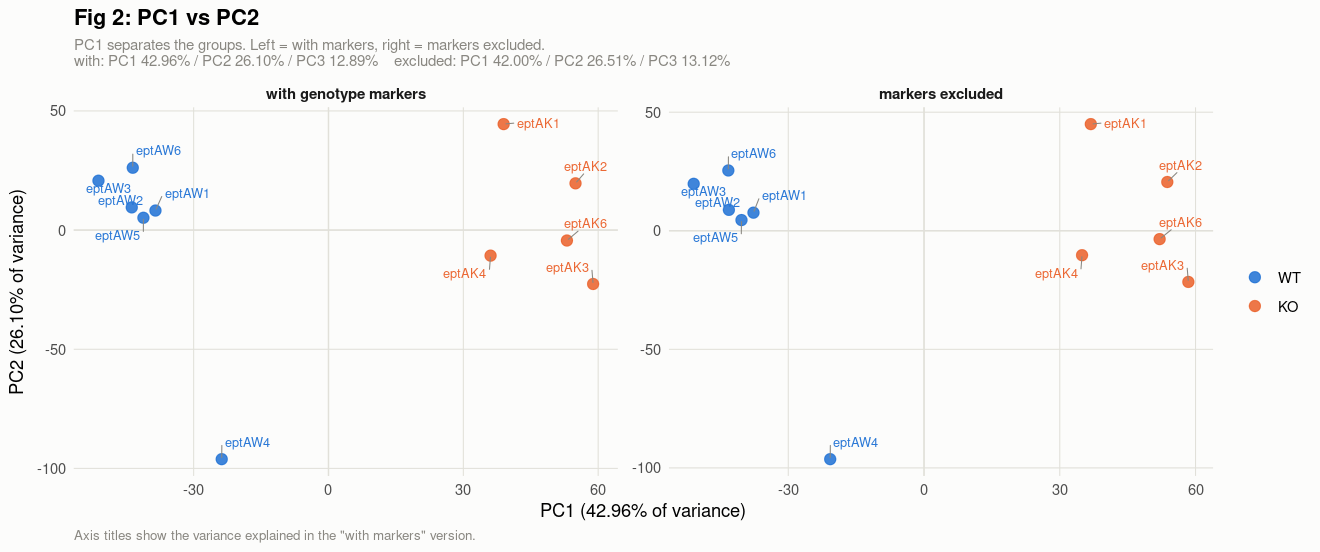

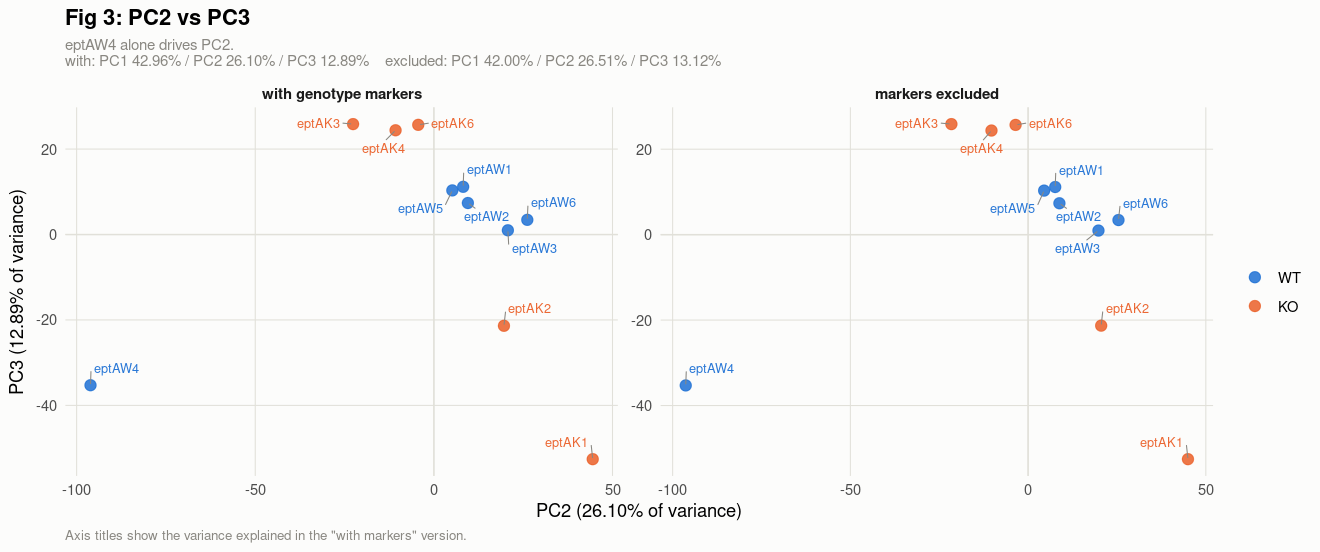

In [22]:
# ── Same figures, English labels（PDF / EPS 出力用）──────────────
# セル12図 と中身は同じで、文字だけ英語にしたもの。
#   例) ggsave('fig_PCA_PC1PC2.pdf', p2_pca_en, width = 11, height = 4.6)
library(ggplot2); library(ggrepel)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_group = c(WT = '#2a78d6', KO = '#eb6834')
thm_en = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

lab_en  = c('with genotype markers', 'markers excluded')
strip_en = lab_en
# variance explained of both versions goes in the subtitle (too long for the strip)
sub_ve_en = sprintf('with: PC1 %.2f%% / PC2 %.2f%% / PC3 %.2f%%    excluded: PC1 %.2f%% / PC2 %.2f%% / PC3 %.2f%%',
                    ve[1], ve[2], ve[3], ve_ex[1], ve_ex[2], ve_ex[3])

sc_en = rbind(
  data.frame(version = strip_en[1], PC1 = pca$x[,1],    PC2 = pca$x[,2],    PC3 = pca$x[,3]),
  data.frame(version = strip_en[2], PC1 = pca_ex$x[,1], PC2 = pca_ex$x[,2], PC3 = pca_ex$x[,3])) %>%
  mutate(sample = rep(rownames(pca$x), 2),
         group  = rep(coldata$group, 2),
         version = factor(version, levels = strip_en))

# ── Fig 1: scree plot ──────────────────────────────────────────
scree_en = rbind(
  data.frame(version = lab_en[1], PC = seq_along(ve),    pct = ve),
  data.frame(version = lab_en[2], PC = seq_along(ve_ex), pct = ve_ex)) %>%
  filter(PC <= 8) %>% mutate(version = factor(version, levels = lab_en))

options(repr.plot.width = 9, repr.plot.height = 3.8)
p1_pca_en = ggplot(scree_en, aes(x = factor(PC), y = pct, fill = version)) +
    geom_col(position = position_dodge(width = 0.75), width = 0.7, alpha = 0.85) +
    geom_hline(yintercept = 2, linetype = 'dashed', colour = col_muted, linewidth = 0.4) +
    scale_fill_manual(values = setNames(c('#898781','#2a78d6'), lab_en), name = NULL) +
    labs(title = 'Fig 1: Variance explained by each principal component',
         subtitle = 'Dashed line = 2% (same cut-off as the reference notebook)',
         x = 'principal component', y = 'variance explained (%)',
         caption = paste('If the profile is unchanged after removing the 7 markers,',
                         'PC1 is not created by them.')) + thm_en
suppressWarnings(print(p1_pca_en))

# ── Fig 2 / 3: principal component scores ──────────────────────
pc_plot_en = function(xv, yv, xlab, ylab, ttl, sub) {
    ggplot(sc_en, aes(x = .data[[xv]], y = .data[[yv]], colour = group)) +
        geom_hline(yintercept = 0, colour = col_grid, linewidth = 0.4) +
        geom_vline(xintercept = 0, colour = col_grid, linewidth = 0.4) +
        geom_point(size = 2.8, alpha = 0.9) +
        geom_text_repel(aes(label = sample), size = 2.7, seed = 1,
                        min.segment.length = 0, segment.colour = col_muted,
                        segment.size = 0.3, box.padding = 0.45, show.legend = FALSE) +
        scale_colour_manual(values = col_group, name = NULL) +
        facet_wrap(~ version, nrow = 1, scales = 'free') +
        labs(title = ttl, subtitle = sub, x = xlab, y = ylab,
             caption = 'Axis titles show the variance explained in the "with markers" version.') +
        thm_en
}

options(repr.plot.width = 11, repr.plot.height = 4.6)
p2_pca_en = pc_plot_en('PC1', 'PC2',
    sprintf('PC1 (%.2f%% of variance)', ve[1]),
    sprintf('PC2 (%.2f%% of variance)', ve[2]),
    'Fig 2: PC1 vs PC2',
    paste0('PC1 separates the groups. Left = with markers, right = markers excluded.\n',
           sub_ve_en))
suppressWarnings(print(p2_pca_en))

options(repr.plot.width = 11, repr.plot.height = 4.6)
p3_pca_en = pc_plot_en('PC2', 'PC3',
    sprintf('PC2 (%.2f%% of variance)', ve[2]),
    sprintf('PC3 (%.2f%% of variance)', ve[3]),
    'Fig 3: PC2 vs PC3',
    paste0('eptAW4 alone drives PC2.\n', sub_ve_en))
suppressWarnings(print(p3_pca_en))

### 考察: VST での PCA（セル12 の結果）

## 結論

1. **PC1（42.96%）が群を完全に分ける**（p = 0.0043、n=6 vs 5 で到達できる最小値）
2. **PC1 は技術的な artifact ではない**（size factor との相関は r = 0.525、**p = 0.097 で有意でない**）
3. **PC1 の正体は CPS 座位の切り替わり** — 正側の上位20が**すべて `CE91St8_295xx`〜`297xx`**
4. **★ PC2（26.10%）は `eptAW4` 1検体が作っている**
5. **遺伝子型マーカーは PC1 を作っていない**（除いた版との PC1 の相関 **r = 0.9998**）

## 1〜2. PC1 は群を分け、深さの artifact ではない

| PC | 寄与率 | WT 平均 | KO 平均 | 群との p | size factor との r | その p |
|---|---|---|---|---|---|---|
| **PC1** | **42.96%** | **−40.3** | **+48.4** | **0.0043** | 0.525 | 0.097 |
| PC2 | 26.10% | −4.4 | +5.3 | 0.7922 | −0.329 | 0.323 |
| PC3 | 12.89% | −0.3 | +0.4 | 0.5368 | 0.451 | 0.164 |

**ステージ3 セル15-9 の `log2(count+1)` 版では r = +0.940（p < 0.0001）だった**のが、
VST では **r = 0.525（p = 0.097）** まで落ちている。**深さを見ているのではない。**

## 3. ★ PC1 の正体 — CPS 座位の切り替わり

**正側（KO で高い）の上位20が、1件の例外もなく `CE91St8_295xx`〜`297xx`。**
`UDP-glucose dehydrogenase`、`N-acetylneuraminate synthase`、
`capsular polysaccharide biosynthesis protein`、`lipid II flippase MurJ` など、
**ステージ3 で CPS 座位2 と同定した領域そのもの。**

**負側（WT で高い）**は、上位4件が eptA マーカー、続いて
**`CE91St8_376xx`（CPS 座位3）** と **`CE91St8_260xx`（CPS 座位1）**。

### |PC1| 上位200の株の内訳

| 株 | DE 入力の遺伝子数 | 上位200 に入る数 | 上位200 に占める割合 |
|---|---|---|---|
| **Bth_St8** | 1,830 | **103** | **51.5%** |
| **Odo_St23** | 2,851 | **61** | **30.5%** |
| Bth_VPI | 1,712 | 21 | 10.5% |
| Bun_8492 | 3,392 | 15 | 7.5% |

**`Bth_St8` と `Odo_St23` で 82%。** `Bun_8492` は遺伝子数が最多（3,392）なのに 7.5% しかない。
→ **PC1 は主に Bth_St8 と Odo_St23 の動きを見ている。**
セル11 の検討で見つけた **Odo_St23 の CPS 座位切り替わり**と整合する。

## 4. ★ PC2（26.10%）は `eptAW4` 1検体が作っている

| 検体 | PC2 |
|---|---|
| **eptAW4** | **−96.1** |
| 他10検体 | −22.6 〜 +44.5 |

**`eptAW4` だけが桁違いに離れている。**
**全分散の 26% を1検体が占めている**ことになる。

RLE の IQR（1.37）・PCA の PC2/PC3（ステージ3）・Salmon の整合率（95.66%）・
size factor のフィルタ感受性・検体距離（WT 内で単独の枝）に続き、**6つ目の独立な指標。**
しかも**今回が最も定量的に大きい。**

**ただし PC1 では WT 側に収まっている**（−23.8。WT の範囲 −51.2〜−23.8 の端ではあるが群を外れない）。
→ **除外しない判断は変えない。ステージ5 の感度解析で必ず確認する。**

## 5. 遺伝子型マーカーは PC1 を作っていない

| 版 | 遺伝子数 | PC1 | PC2 | PC3 | PC1 の群間 p |
|---|---|---|---|---|---|
| マーカーを含む | 9,795 | 42.96% | 26.10% | 12.89% | 0.0043 |
| **マーカーを除く** | 9,788 | **42.00%** | 26.51% | 13.12% | **0.0043** |

**2版の PC1 得点の相関は r = 0.9998。**

マーカー7件は**個々の loading は最大**（Table 5 の上位4件）だが、
**CPS 座位の37遺伝子がまとまって効く方が大きい**ので、PC1 の向きは変わらない。

→ **ステージ3 セル15-9 とは状況が違う。** あちらでは
マーカーが PC1 の上位を占めていたが、今回は **DE のフィルタで
mappability の低い遺伝子が落ち、CPS 座位の寄与が相対的に大きくなった**ためと考えられる。

## 気づいた点: cysteine synthase が3株で並ぶ

PC1 負側（WT で高い）の上位20に、**3株にまたがって cysteine synthase が入っている。**

| gene_id | 株 | LFC | product |
|---|---|---|---|
| `CE91St8_09700` | Bth_St8 | −3.85 | cysteine synthase |
| `BT_RS15610` | Bth_VPI | −3.88 | cysteine synthase A |
| `NQ510_RS04250` | Bun_8492 | −3.49 | cysteine synthase A |

**株をまたいで同じ機能が同じ向きに動いている。**
ステージ6 の「収束」の候補として記録する（ここでは3遺伝子なので判断しない）。

## セル13: 株ごとに遺伝子数(n)とリードカウント数(cnt)をまとめる

過去notebook（`230313_T19_33mix` の `4_DESeq2_allmapped_fractionmode_R.ipynb`
**セル59-66**）の `numberscounts` / `compare_allvsupvsdown` に対応。

### 過去notebook との違い

| 過去 | 今回 | 理由 |
|---|---|---|
| `gene_id` の接頭辞を `str_split` で切って株を判定 | **`feature_info.csv` の `strain` 列を使う** | ステージ2 で GTF に `strain` 属性を入れてあるので切り出す必要がない |
| 生カウントのみ | **生と正規化後の両方** | 生は深さの差を含むので、**株どうしの比較には正規化後**を見る |
| — | **Table 5・6 を追加** | 下記 |

### ★ Table 5・6 を足した理由

**「その株の転写産物の総量がどれだけ動いたか」（`cnt_log2FC`）と、
「典型的な遺伝子がどれだけ動いたか」（セル7 Table 4 の `LFC 中央値`）は別物。**

総量は**発現量の高い少数の遺伝子**で決まるので、
両者がずれるなら**発現量の高い遺伝子と低い遺伝子で動きが違う**ということになる。
**Table 6 で発現量の帯ごとに切って確かめる。**

In [23]:
# ── 株ごとに遺伝子数(n)とリードカウント数(cnt)をまとめる ───────────
# 過去notebook（230313_T19_33mix の 4_DESeq2_allmapped_fractionmode_R.ipynb
# セル59-66）の numberscounts / compare_allvsupvsdown に対応。
#
# ★ 過去notebook は gene_id の接頭辞を str_split で切って株を判定していたが、
#   今回は feature_info.csv に strain 列があるのでそれを使う（セル3）。
#
# ★ カウントは【生】と【正規化後】の両方を出す。
#   生は深さの差を含むので、株どうしの比較には正規化後を見る

m_raw  = as.matrix(cnt_de)
m_norm = counts(dds, normalized = TRUE)
st     = feat_de$strain
lv     = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23','pME008')

cat("■ Table 1: 株ごと・検体ごとの検出遺伝子数（カウント > 0）\n")
n_tbl = do.call(rbind, lapply(lv, function(s) {
    i = st == s
    data.frame(strain = s, genes_in_input = sum(i),
               t(colSums(m_raw[i, , drop = FALSE] > 0)), check.names = FALSE)
}))
n_tbl

cat("\n■ Table 2: 株ごと・検体ごとの正規化カウント合計（百万）\n")
c_tbl = do.call(rbind, lapply(lv, function(s) {
    i = st == s
    data.frame(strain = s,
               t(round(colSums(m_norm[i, , drop = FALSE]) / 1e6, 2)),
               check.names = FALSE)
}))
c_tbl

# ── 群平均と DEG 数をまとめる（過去notebook の compare_allvsupvsdown）──
is_wt = coldata$group == 'WT'

cat("\n■ Table 3: 株ごとのまとめ（群平均と DEG 数）\n")
cat("   n_mean    … 検出遺伝子数の群平均\n")
cat("   cnt_mean  … 正規化カウント合計の群平均（百万）\n")
cat("   cnt_log2FC… log2(KO / WT)。その株の転写産物量が群間でどれだけ動いたか\n")
summary_tbl = do.call(rbind, lapply(lv, function(s) {
    i   = st == s
    nn  = colSums(m_raw[i, , drop = FALSE] > 0)
    cc  = colSums(m_norm[i, , drop = FALSE])
    d   = de[i, ]
    sg  = !is.na(d$padj) & d$padj < 0.05
    data.frame(
        strain        = s,
        genes_in_input = sum(i),
        tested        = sum(!is.na(d$padj)),
        WT_n_mean     = round(mean(nn[is_wt])),
        KO_n_mean     = round(mean(nn[!is_wt])),
        WT_cnt_mean_M = round(mean(cc[is_wt]) / 1e6, 2),
        KO_cnt_mean_M = round(mean(cc[!is_wt]) / 1e6, 2),
        cnt_log2FC    = round(log2(mean(cc[!is_wt]) / mean(cc[is_wt])), 3),
        upDEGs        = sum(sg & d$LFC_shrunk > 0),
        downDEGs      = sum(sg & d$LFC_shrunk < 0),
        DEG_pct       = round(100 * sum(sg) / sum(!is.na(d$padj)), 1),
        row.names = NULL)
}))
summary_tbl

cat("\n■ Table 4: 合計（検算用）\n")
data.frame(
    item = c('遺伝子数（セル4 の入力）', '検定された遺伝子', 'DEG 合計',
             'うち上昇', 'うち低下'),
    n    = c(sum(summary_tbl$genes_in_input), sum(summary_tbl$tested),
             sum(summary_tbl$upDEGs) + sum(summary_tbl$downDEGs),
             sum(summary_tbl$upDEGs), sum(summary_tbl$downDEGs)),
    check.names = FALSE)

# ── ★ 総量の変化と、典型的な遺伝子の変化がずれる ─────────────────
# cnt_log2FC（その株の転写産物の総量）と、セル7 Table 4 の LFC 中央値
# （典型的な遺伝子）は別物。ずれるなら、発現量の高い遺伝子と低い遺伝子で
# 動きが違うということなので、発現量の帯ごとに見る
cat("\n■ Table 5: 総量の変化 vs 典型的な遺伝子の変化\n")
cat("   差 = LFC中央値 − 総量log2FC。正なら【発現量の高い遺伝子ほど下がっている】\n")
do.call(rbind, lapply(setdiff(lv, 'pME008'), function(s) {
    i  = st == s
    cc = colSums(m_norm[i, , drop = FALSE])
    dd = de$LFC_shrunk[i]
    data.frame(strain = s,
               total_log2FC  = round(log2(mean(cc[!is_wt]) / mean(cc[is_wt])), 3),
               LFC_median    = round(median(dd, na.rm = TRUE), 3),
               difference    = round(median(dd, na.rm = TRUE) -
                                     log2(mean(cc[!is_wt]) / mean(cc[is_wt])), 3),
               row.names = NULL)
}))

cat("\n■ Table 6: 発現量の帯ごとの LFC 中央値（株ごと）\n")
cat("   pct_of_reads … その帯がその株の総リードに占める割合\n")
de %>% filter(!is.na(padj), strain != 'pME008') %>%
    mutate(bin = cut(baseMean, c(0, 100, 1000, 1e4, 1e5, Inf),
                     labels = c('<100','100-1k','1k-10k','10k-100k','>100k'))) %>%
    group_by(strain, bin) %>%
    summarise(n = dplyr::n(),
              LFC_median = round(median(LFC_shrunk), 3),
              up   = sum(padj < 0.05 & LFC_shrunk > 0),
              down = sum(padj < 0.05 & LFC_shrunk < 0),
              reads = sum(baseMean), .groups = 'drop_last') %>%
    mutate(pct_of_reads = round(100 * reads / sum(reads), 1)) %>%
    ungroup() %>% dplyr::select(-reads) %>% as.data.frame()

■ Table 1: 株ごと・検体ごとの検出遺伝子数（カウント > 0）


strain,genes_in_input,eptAW1,eptAW2,eptAW3,eptAW4,eptAW5,eptAW6,eptAK1,eptAK2,eptAK3,eptAK4,eptAK6
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Bth_VPI,1712,1712,1712,1711,1712,1712,1711,1703,1708,1711,1711,1711
Bth_St8,1830,1828,1829,1826,1830,1828,1815,1819,1823,1829,1830,1827
Bun_8492,3392,3392,3391,3392,3392,3392,3391,3390,3391,3392,3391,3391
Odo_St23,2851,2850,2851,2851,2851,2851,2850,2847,2849,2850,2850,2850
pME008,10,10,10,10,10,10,10,10,10,10,10,10



■ Table 2: 株ごと・検体ごとの正規化カウント合計（百万）


strain,eptAW1,eptAW2,eptAW3,eptAW4,eptAW5,eptAW6,eptAK1,eptAK2,eptAK3,eptAK4,eptAK6
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Bth_VPI,1.84,2.16,1.53,1.35,1.68,1.83,0.86,0.76,0.67,1.00,0.91
Bth_St8,4.33,4.66,5.18,3.64,4.64,3.36,4.86,2.17,2.49,2.43,1.89
Bun_8492,20.01,18.69,17.70,17.10,17.71,18.32,21.43,16.31,14.42,15.27,15.48
Odo_St23,0.92,0.95,1.13,0.62,0.92,1.17,0.90,0.66,0.62,0.67,0.60
pME008,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00



■ Table 3: 株ごとのまとめ（群平均と DEG 数）


   n_mean    … 検出遺伝子数の群平均
   cnt_mean  … 正規化カウント合計の群平均（百万）
   cnt_log2FC… log2(KO / WT)。その株の転写産物量が群間でどれだけ動いたか


... (3 outputs left out)


■ Table 5: 総量の変化 vs 典型的な遺伝子の変化
   差 = LFC中央値 − 総量log2FC。正なら【発現量の高い遺伝子ほど下がっている】


strain,total_log2FC,LFC_median,difference
<chr>,<dbl>,<dbl>,<dbl>
Bth_VPI,-1.048,-0.107,0.941
Bth_St8,-0.635,-0.081,0.554
Bun_8492,-0.139,0.315,0.453
Odo_St23,-0.458,-0.181,0.277



■ Table 6: 発現量の帯ごとの LFC 中央値（株ごと）
   pct_of_reads … その帯がその株の総リードに占める割合


strain,bin,n,LFC_median,up,down,pct_of_reads
<chr>,<fct>,<int>,<dbl>,<int>,<int>,<dbl>
Bth_St8,<100,752,-0.087,74,152,0.9
Bth_St8,100-1k,777,0.031,115,131,7.2
Bth_St8,1k-10k,218,-0.426,10,90,18.2
Bth_St8,10k-100k,39,-1.520,0,28,30.5
Bth_St8,>100k,7,-0.182,0,1,43.3
Bth_VPI,<100,838,-0.070,59,178,2.6
Bth_VPI,100-1k,650,-0.031,62,117,15.9
Bth_VPI,1k-10k,160,-0.958,5,94,36.8
Bth_VPI,10k-100k,23,-1.493,0,20,44.8


### 考察: 株ごとの集計（セル13 の結果）

## 結論

1. **検出遺伝子数は株・検体によらずほぼ一定**（入力の 99.5% 以上）。prefilter が効いている
2. **DEG の向きは株ごとにはっきり違う** — `Bun_8492` だけ上昇が優勢（1,173 / 224）
3. **★ 4株すべてで、最高発現の帯は上昇遺伝子がほぼゼロ**（ただし下記のとおり
   「高発現が下がった」のか「残りが上がった」のかは**原理的に区別できない**）
4. **★ `Bun_8492` の最高発現遺伝子は抗酸化系で、まとめて KO で低下**

## 1. 検出遺伝子数（Table 1）

入力 9,795 遺伝子に対し、どの株・どの検体でも **99.5% 以上が検出**されている
（例: `Bth_VPI` 1,712 中 1,703〜1,712）。
**prefilter（`count>=10` を5検体以上）が効いている**ことの確認になる。
→ **検出遺伝子数は今回の解析では情報を持たない。**

## 2. 株ごとの DEG（Table 3）

| 株 | 検定された | 上昇 | 低下 | DEG% | 総量 log2FC |
|---|---|---|---|---|---|
| Bth_VPI | 1,671 | 126 | **409** | 32.0 | **−1.048** |
| Bth_St8 | 1,793 | 199 | **402** | 33.5 | −0.635 |
| **Bun_8492** | 3,323 | **1,173** | 224 | **42.0** | **−0.139** |
| Odo_St23 | 2,839 | 117 | **475** | 20.9 | −0.458 |

**`Bun_8492` だけが上昇優勢**で、他3株は低下が優勢。

## 3. ★ 総量と典型的な遺伝子の動きがずれる（Table 5）

| 株 | 総量 log2FC | LFC 中央値 | **差** |
|---|---|---|---|
| Bth_VPI | −1.048 | −0.107 | **+0.941** |
| Bth_St8 | −0.635 | −0.081 | **+0.554** |
| **Bun_8492** | **−0.139** | **+0.315** | **+0.453** |
| Odo_St23 | −0.458 | −0.181 | **+0.277** |

**差が4株すべてで正**＝**発現量の高い遺伝子ほど KO で下がっている。**

`Bun_8492` が特に極端で、**総量は下がっている（−0.139）のに典型的な遺伝子は上がっている（+0.315）。**

### Table 6 — 発現量の帯で切ると、4株すべてで同じ形

**最高発現の帯では、どの株も上昇遺伝子がほぼゼロ。**

| 株 | 最高発現の帯 | 遺伝子数 | LFC 中央値 | 上昇 | 低下 | 総リードに占める割合 |
|---|---|---|---|---|---|---|
| Bth_St8 | 10k–100k | 39 | **−1.520** | **0** | 28 | 30.5% |
| Bth_VPI | 10k–100k | 23 | **−1.493** | **0** | 20 | 44.8% |
| Bun_8492 | >100k | 27 | −0.501 | **0** | 12 | 29.6% |
| Odo_St23 | 1k–10k | 178 | −0.410 | 2 | 64 | 49.5% |

一方 `Bun_8492` の中程度の帯（100〜10k、2,590遺伝子）では **1,063 が上昇**。

## ★ ただし、これが「高発現遺伝子が下がった」のか「残りが上がった」のかは決められない

**median-of-ratios は「真ん中の遺伝子」を 1 に合わせる方式**（セル5・セル7 Table 4）。

```
高発現の少数の遺伝子が実際に下がる
  → ライブラリ全体の総量が減る
  → 真ん中の遺伝子を 1 に合わせるため size factor が調整される
  → 残りの遺伝子が「上がった」ように見える
```

**逆に「残りが上がった」場合も、まったく同じ数字になる。**
相対量しか測っていないので、**どちらが起きたかは原理的に区別できない**（compositionality）。

**区別するには spike-in か総菌量 qPCR が要る**（CLAUDE.md 付録 A-1 の 1・2）。本実験には無い。

→ **(B) でも解決しない**（株の中でも同じ相対量の問題が起きる）。
**「高発現側と中発現側で向きが逆」という事実の記述にとどめる。**

## 4. ★ `Bun_8492` の最高発現遺伝子は抗酸化系

| gene_id | baseMean | LFC | padj | product |
|---|---|---|---|---|
| `NQ510_RS12460` | 721,331 | **−1.03** | 1.4e-04 | **superoxide dismutase** |
| `NQ510_RS16430` | 324,756 | −0.51 | 3.4e-02 | **thiol peroxidase** |
| `NQ510_RS10630` | 275,646 | −0.78 | 1.2e-04 | phosphopyruvate hydratase |
| `NQ510_RS11780` | 251,337 | −0.83 | 7.6e-06 | phosphogluconate dehydrogenase |
| **`NQ510_RS04250`** | 248,108 | **−3.49** | 2.1e-20 | **cysteine synthase A** |
| `NQ510_RS10870` | 208,159 | **−1.07** | 2.5e-11 | **thioredoxin family protein** |

**スーパーオキシドディスムターゼ・チオールペルオキシダーゼ・チオレドキシン・
システイン合成酵素**が、いずれも**KO でまとまって低下**している。

**`cysteine synthase A` はセル12 の PC1 負側でも3株にまたがって出ていた**
（`CE91St8_09700` −3.85 / `BT_RS15610` −3.88 / `NQ510_RS04250` −3.49）。

→ **酸化ストレス応答・レドックス系が KO で下がっている**という読みの候補。
**※ ただし上記の compositionality の留保がかかる。**
これらは `Bun_8492` の最高発現遺伝子なので、
**「相対的に下がった」以上のことは言えない。**
システイン合成はグルタチオン前駆体の供給でもある。
**ステージ6 の経路解析で、株をまたぐ収束として扱う。**
ここでは個別遺伝子の観察にとどめる。

## 申し送り

- **検出遺伝子数の表（Table 1）は今後不要**（prefilter 後は一定）
- **株ごとの DEG 数（Table 3）はステージ6 の「担い手」の分母になる**
- **Table 5 の「差」は (A) を読むときの注意点**:
  「株が増えた/減った」は**総量の話**であって、**典型的な遺伝子の話ではない**
- **★ 高発現遺伝子の低下は、経路解析で必ず上位に来る**（リボソーム・解糖系・
  抗酸化系など、もともと発現量の大きい経路）。
  **compositionality の留保を図の注記に必ず書く**

## セル14図: 個別遺伝子の箱ひげ図（正規化カウント）

過去notebook（`230313_T19_33mix` の `4_DESeq2_allmapped_fractionmode_R.ipynb`
**セル69-75**）に対応。**正規化カウントを群ごとに箱ひげで描き、検体の点を重ねる。**

**経路レベルの主張を遺伝子レベルで裏打ちする**ための図（CLAUDE.md §9 の「変えない方がよいもの」）。

### 過去notebook との違い

| 過去 | 今回 | 理由 |
|---|---|---|
| `ggpubr::ggboxplot` を1遺伝子ずつ作って `+` で足す | **ggplot2 の `facet_wrap`** | 遺伝子数が変わっても同じコードで描ける。目盛りを遺伝子ごとに変えられる |
| 並べ替えは生の `log2FoldChange` | **収縮後の LFC** | CLAUDE.md §7 ステージ5。生の LFC は低カウント遺伝子で暴れる |
| `gene_id2` = `contig_geneid_genename` | **パネル見出しに gene_id / 株 / product / LFC / padj** | どの株のどんな遺伝子かを図の中で読めるように |
| — | **eptA マーカーを別の図に分ける** | マーカーは LFC で上位を独占するので、top20 から外さないと他が見えない |

### 図の構成（3枚）

| 図 | 中身 |
|---|---|
| 図1 | **KO で上昇した遺伝子 top20**（マーカー除く） |
| 図2 | **KO で低下した遺伝子 top20**（マーカー除く） |
| 図3 | **eptA の遺伝子型マーカー 7件**（陽性対照） |

### 箱の外れ値点を消してある

`geom_boxplot(outlier.shape = NA)` + `geom_jitter` にしてある。
**全検体を点で描くので、箱の外れ値点を出すと同じ検体が二重に表示される。**

■ 上昇 top20 の LFC 範囲: +4.82 〜 +6.60
■ 低下 top20 の LFC 範囲: -5.69 〜 -3.60
■ eptA マーカー: 7 件


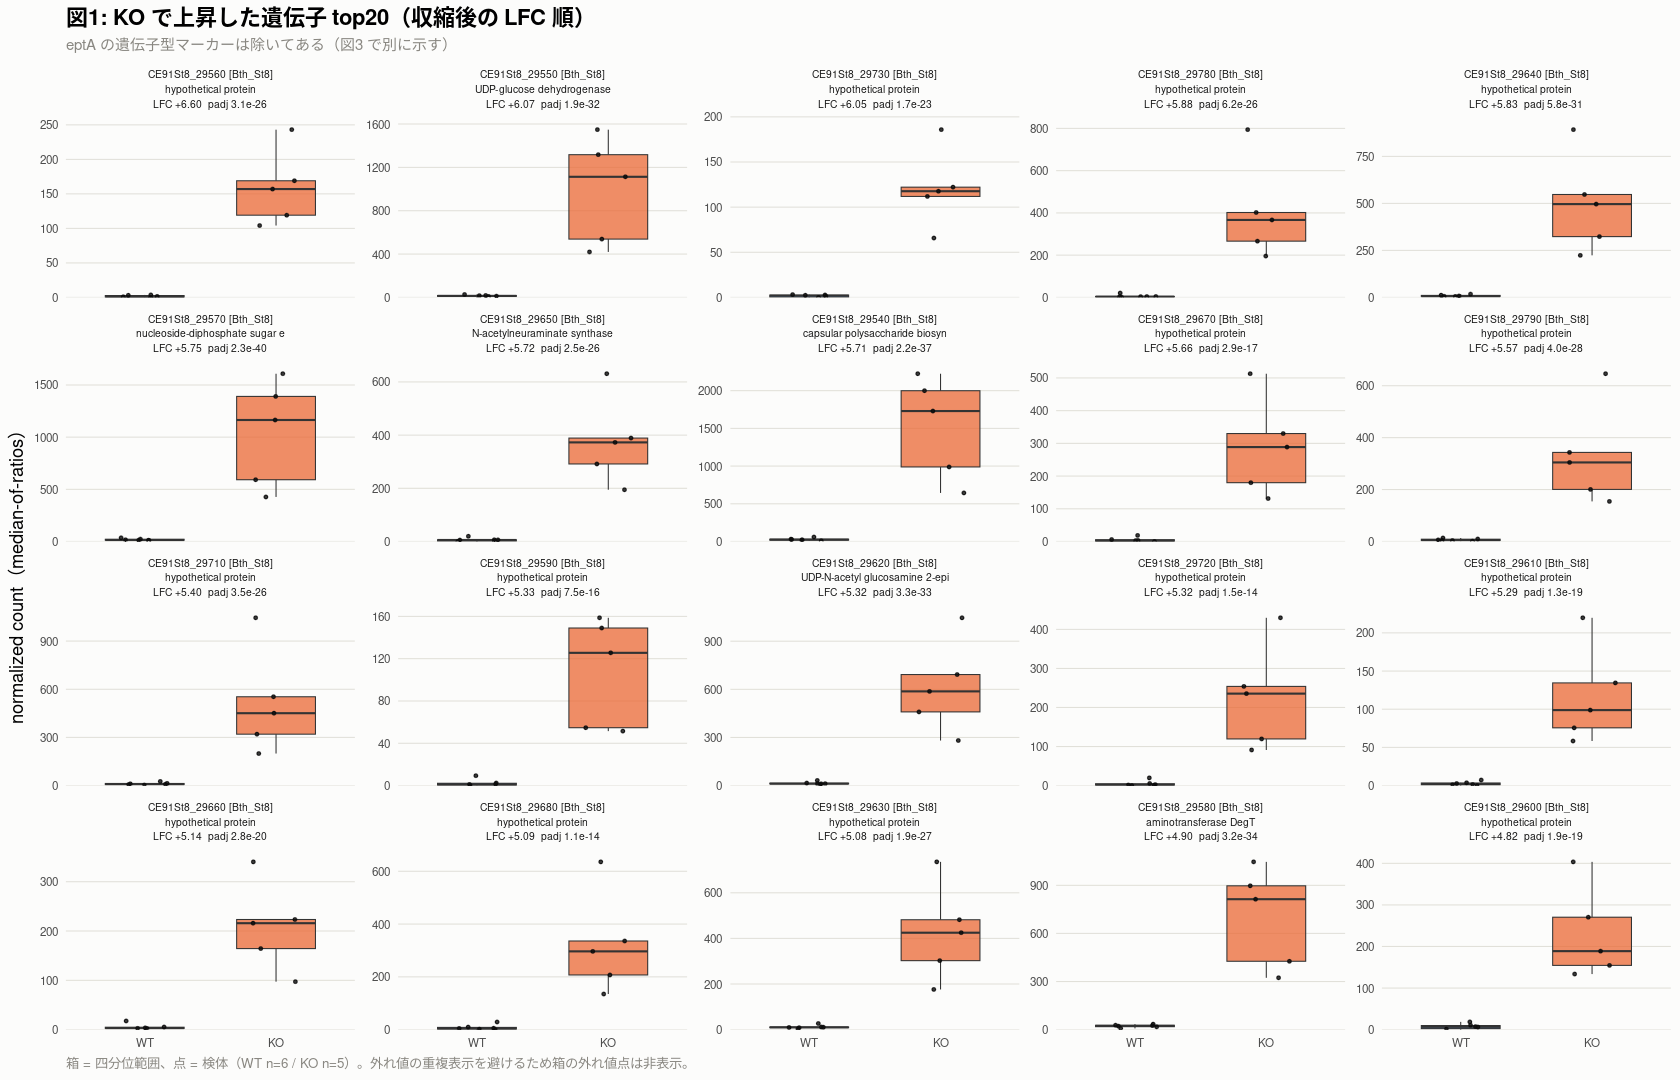

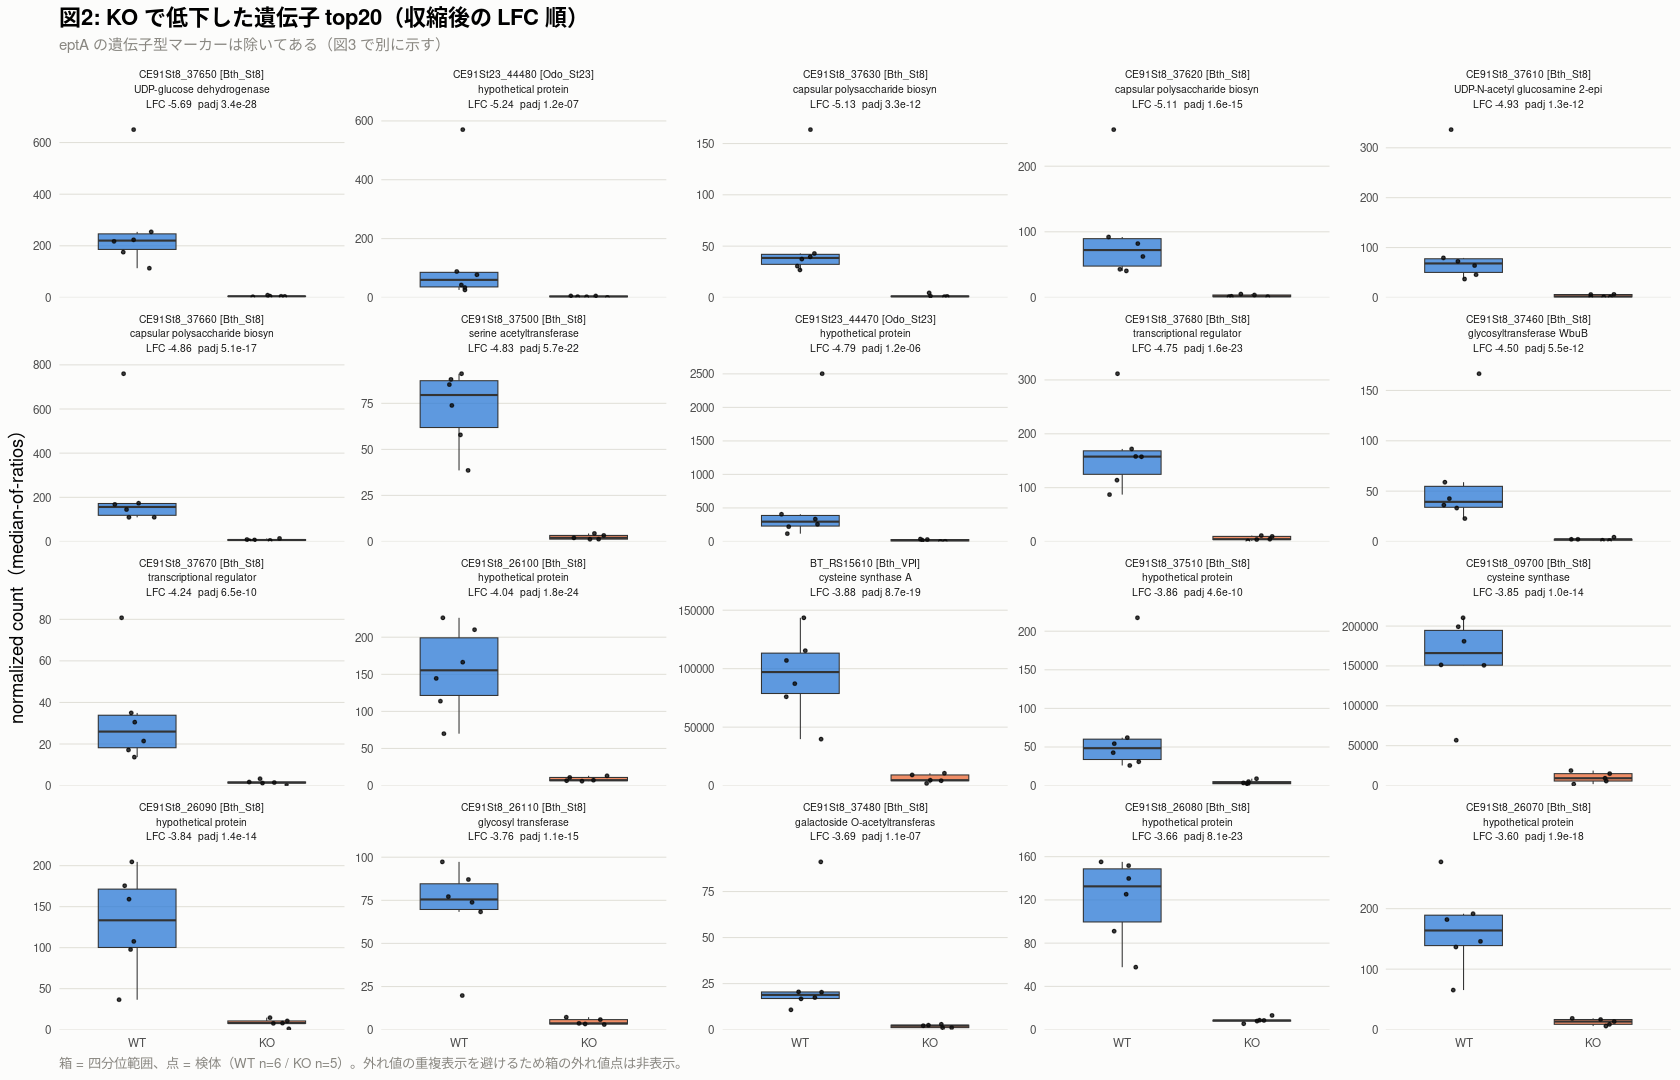

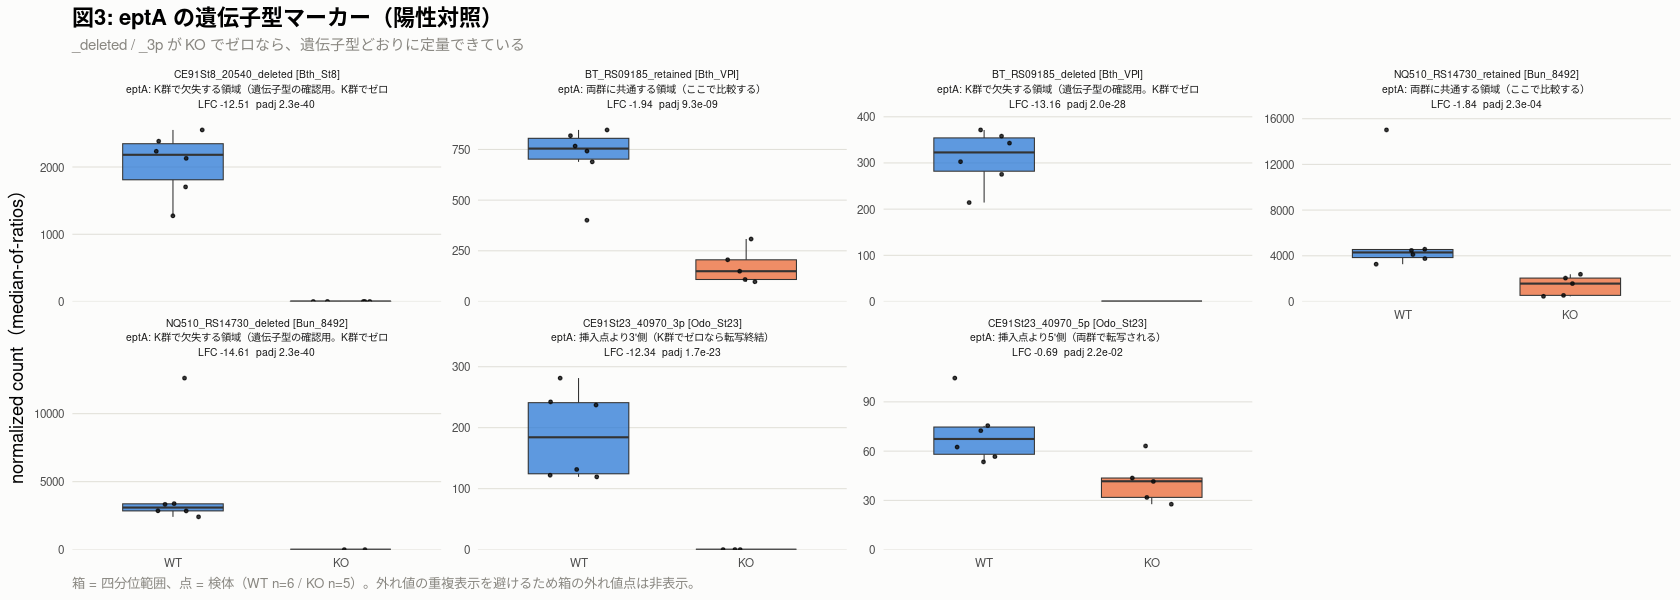

In [24]:
# ── 個別遺伝子の棒グラフ（箱ひげ＋点）で確認する ──────────────────
# 過去notebook（230313_T19_33mix の 4_DESeq2_allmapped_fractionmode_R.ipynb
# セル69-75）に対応。
#   正規化カウントを群ごとに箱ひげで描き、検体の点を重ねる。
#   経路レベルの主張を【遺伝子レベルで裏打ちする】ための図
#
# 過去notebook との違い
#   ・ggpubr の ggboxplot を1遺伝子ずつ作って + で足す方式 → ggplot2 の facet_wrap
#     （遺伝子数が変わっても同じコードで描ける。目盛りも遺伝子ごとに変えられる）
#   ・並べ替えは【収縮後の LFC】で行う（CLAUDE.md §7 ステージ5）
#   ・パネル見出しに gene_id・株・product を入れる（過去の gene_id2 に相当）
#   ・eptA マーカーは上位を独占するので、上昇/低下の top20 からは外し、別の図にする
library(tidyr)

norm_long = counts(dds, normalized = TRUE) %>% as.data.frame() %>%
    tibble::rownames_to_column('gene_id') %>%
    pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm_count') %>%
    mutate(group = factor(coldata$group[match(sample, rownames(coldata))],
                          levels = c('WT','KO')))

# パネル見出し（gene_id / 株 / product を1行に）
de_lab = de %>%
    mutate(panel = sprintf('%s [%s]\n%s\nLFC %+.2f  padj %s',
                           gene_id, strain, substr(product, 1, 30),
                           LFC_shrunk, format(signif(padj, 2), scientific = TRUE)))

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_group = c(WT = '#2a78d6', KO = '#eb6834')
thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major.x = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(size = 6.2, lineheight = 1.2),
          axis.text = element_text(size = 7),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# 共通の描き方
gene_panels = function(ids, ttl, sub, ncol = 5) {
    d = norm_long %>% filter(gene_id %in% ids) %>%
        left_join(de_lab %>% dplyr::select(gene_id, panel), by = 'gene_id') %>%
        mutate(panel = factor(panel, levels = de_lab$panel[match(ids, de_lab$gene_id)]))
    ggplot(d, aes(x = group, y = norm_count, fill = group)) +
        geom_boxplot(outlier.shape = NA, linewidth = 0.3, width = 0.6, alpha = 0.75) +
        geom_jitter(width = 0.18, size = 0.7, alpha = 0.8, colour = col_text) +
        scale_fill_manual(values = col_group) + guides(fill = 'none') +
        scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
        facet_wrap(~ panel, ncol = ncol, scales = 'free_y') +
        labs(title = ttl, subtitle = sub, x = NULL,
             y = 'normalized count（median-of-ratios）',
             caption = paste0('箱 = 四分位範囲、点 = 検体（WT n=6 / KO n=5）。',
                              '外れ値の重複表示を避けるため箱の外れ値点は非表示。')) + thm
}

sig_de = de %>% filter(!is.na(padj), padj < 0.05, !marker)

up20   = sig_de %>% arrange(desc(LFC_shrunk)) %>% head(20) %>% pull(gene_id)
down20 = sig_de %>% arrange(LFC_shrunk)       %>% head(20) %>% pull(gene_id)
mk     = de$gene_id[de$marker]

cat(sprintf("■ 上昇 top20 の LFC 範囲: %+.2f 〜 %+.2f\n",
            min(de$LFC_shrunk[de$gene_id %in% up20]),
            max(de$LFC_shrunk[de$gene_id %in% up20])))
cat(sprintf("■ 低下 top20 の LFC 範囲: %+.2f 〜 %+.2f\n",
            min(de$LFC_shrunk[de$gene_id %in% down20]),
            max(de$LFC_shrunk[de$gene_id %in% down20])))
cat(sprintf("■ eptA マーカー: %d 件\n", length(mk)))

options(repr.plot.width = 14, repr.plot.height = 9)
suppressWarnings(print(gene_panels(up20,
    '図1: KO で上昇した遺伝子 top20（収縮後の LFC 順）',
    'eptA の遺伝子型マーカーは除いてある（図3 で別に示す）')))

options(repr.plot.width = 14, repr.plot.height = 9)
suppressWarnings(print(gene_panels(down20,
    '図2: KO で低下した遺伝子 top20（収縮後の LFC 順）',
    'eptA の遺伝子型マーカーは除いてある（図3 で別に示す）')))

options(repr.plot.width = 14, repr.plot.height = 5)
suppressWarnings(print(gene_panels(mk,
    '図3: eptA の遺伝子型マーカー（陽性対照）',
    '_deleted / _3p が KO でゼロなら、遺伝子型どおりに定量できている', ncol = 4)))

## セル14図（英語版）: Per-gene boxplots

**中身はセル14図 と同じ3枚で、文字だけ英語にしたもの。**
PDF / EPS に出すときの文字化けを避けるため。

```r
ggsave('fig_top20_up.pdf',   p1_gene_en, width = 14, height = 9)
ggsave('fig_top20_down.pdf', p2_gene_en, width = 14, height = 9)
ggsave('fig_eptA_markers.pdf', p3_gene_en, width = 14, height = 5)
```

| 変数 | 図 |
|---|---|
| `p1_gene_en` | Fig 1: Top 20 genes up in KO |
| `p2_gene_en` | Fig 2: Top 20 genes down in KO |
| `p3_gene_en` | Fig 3: eptA genotype markers (positive controls) |

### ★ eptA マーカーの `product` は GTF 内が日本語

パネル見出しに出るので、このセルで英語に置き換える。

| GTF の `product` | 英語版 |
|---|---|
| `eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）` | `eptA: region deleted in KO (genotype control)` |
| `eptA: 両群に共通する領域（ここで比較する）` | `eptA: region shared by both groups` |
| `eptA: 挿入点より3'側（K群でゼロなら転写終結）` | `eptA: 3' of the insertion point` |
| `eptA: 挿入点より5'側（両群で転写される）` | `eptA: 5' of the insertion point` |

**※ ステージ2 で GTF に日本語の `product` を入れたのはこの4件だけ。**
他の遺伝子は NCBI / DDBJ の英語の `product` がそのまま入っている。

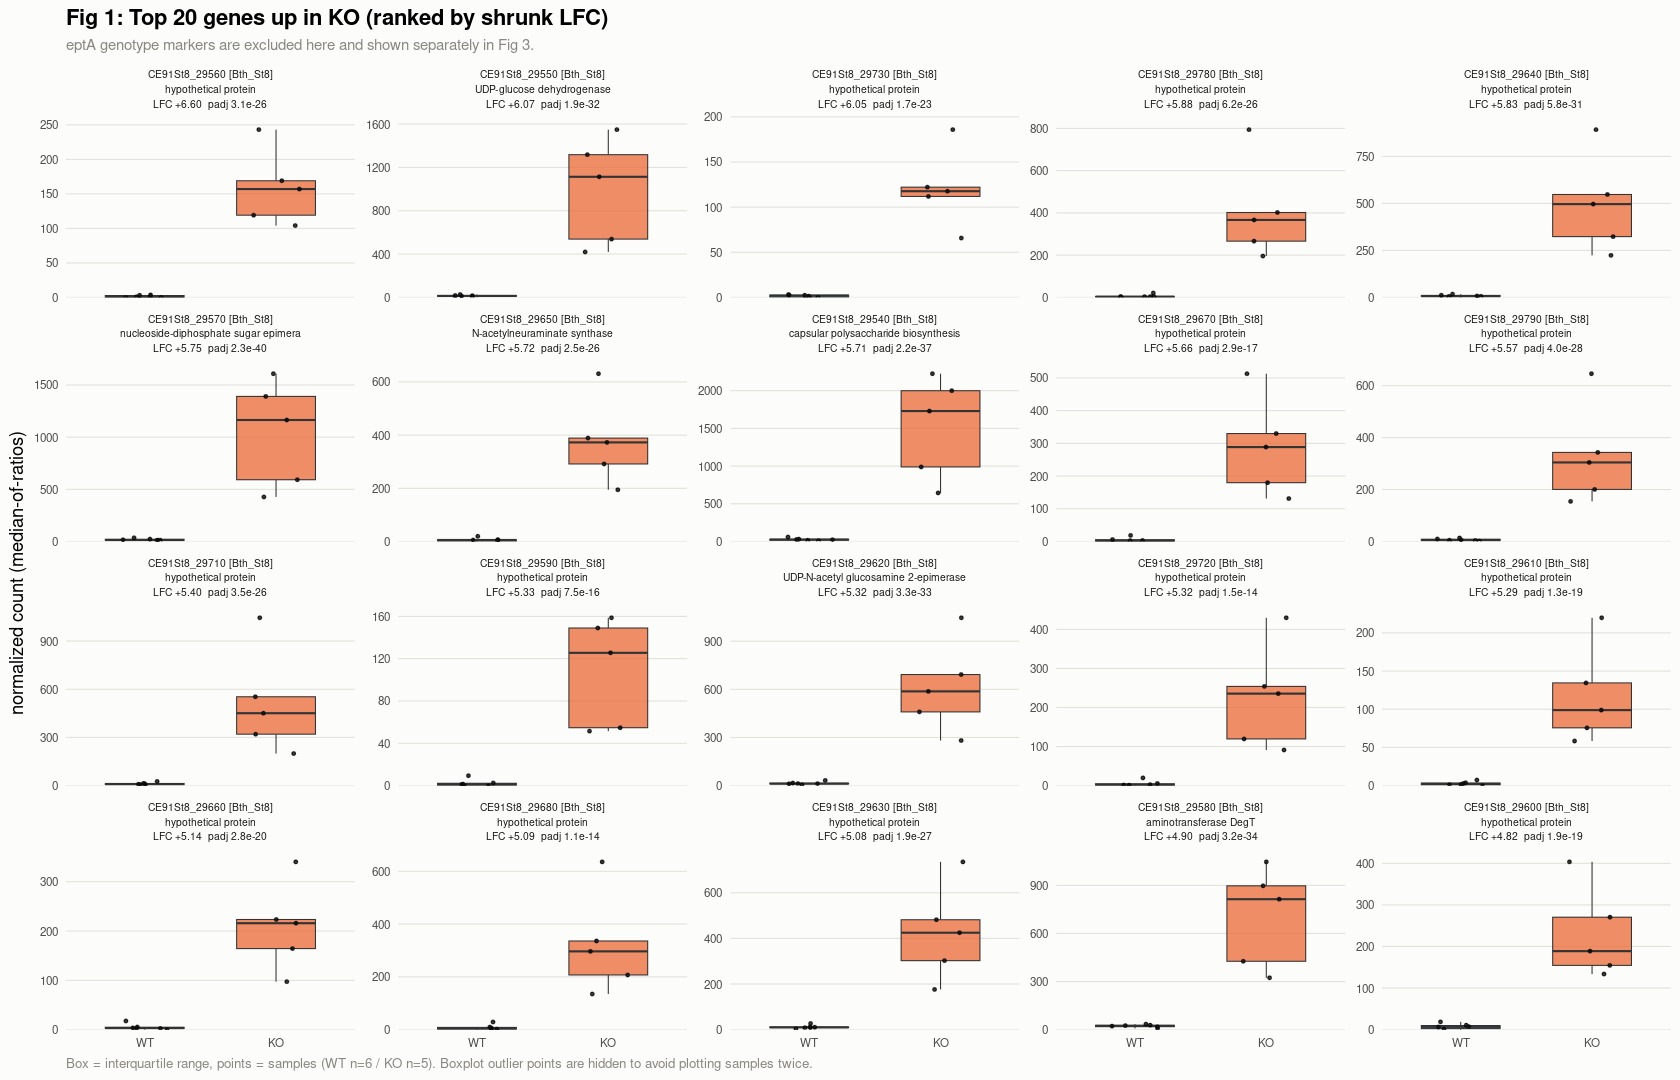

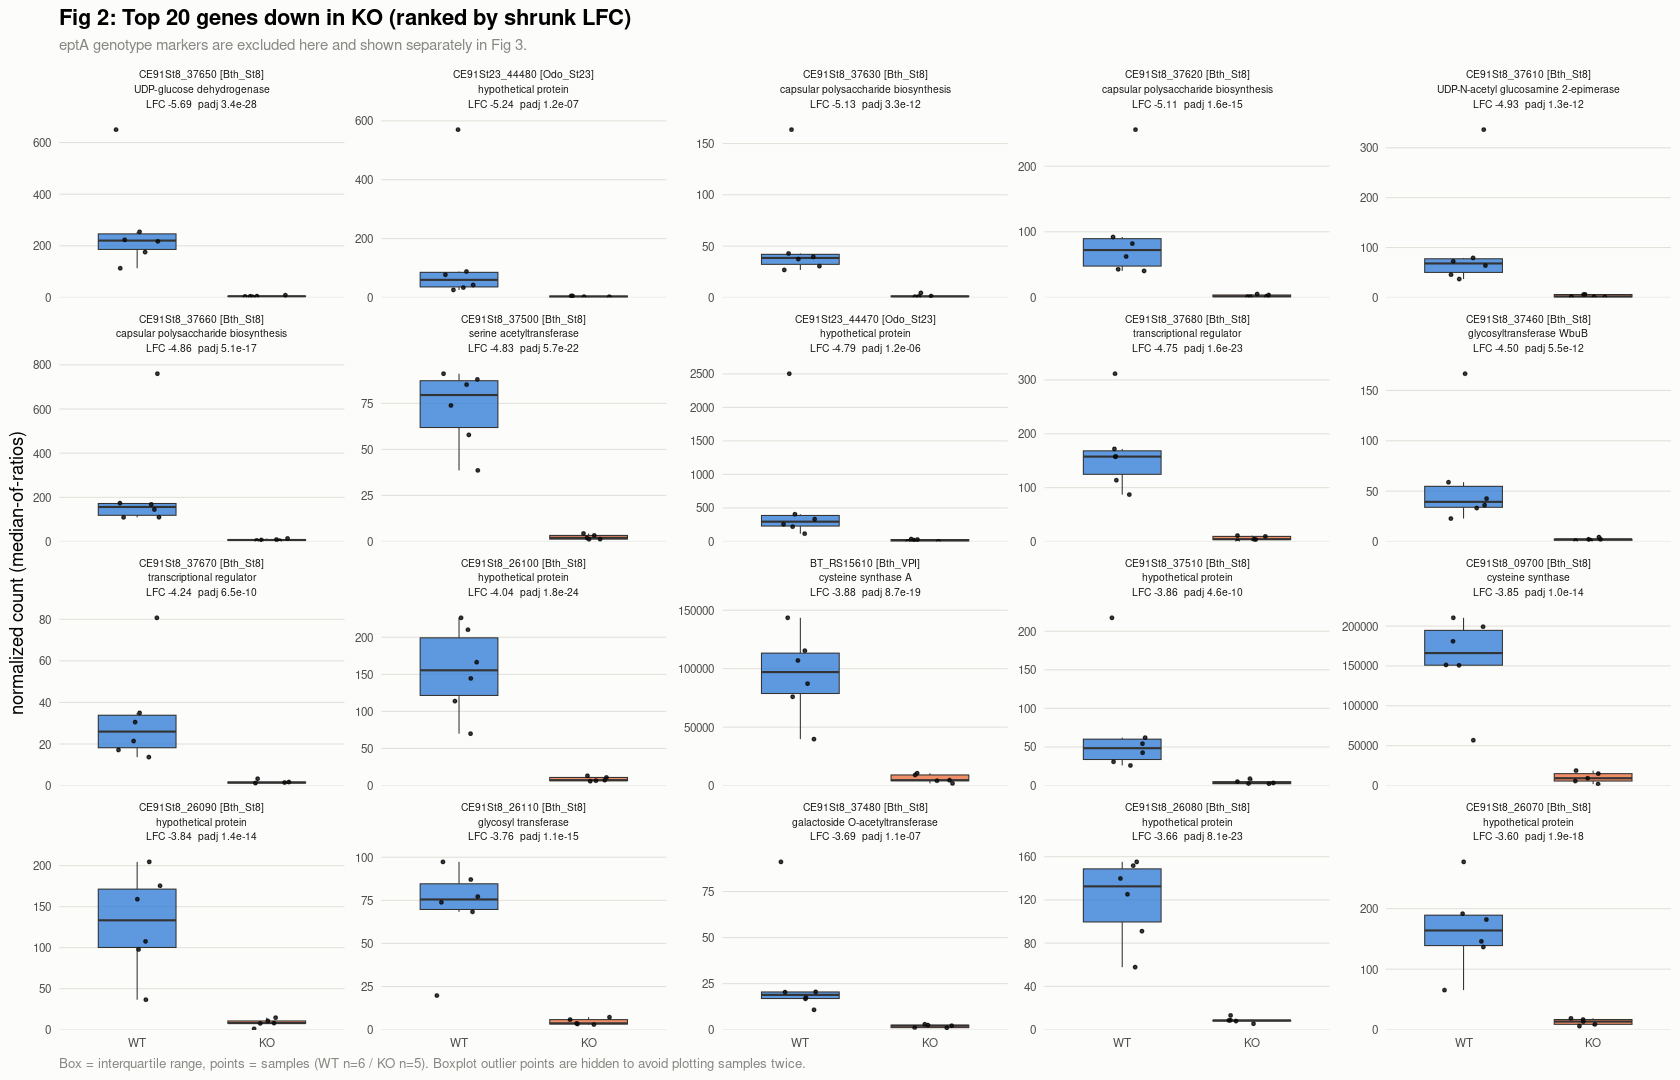

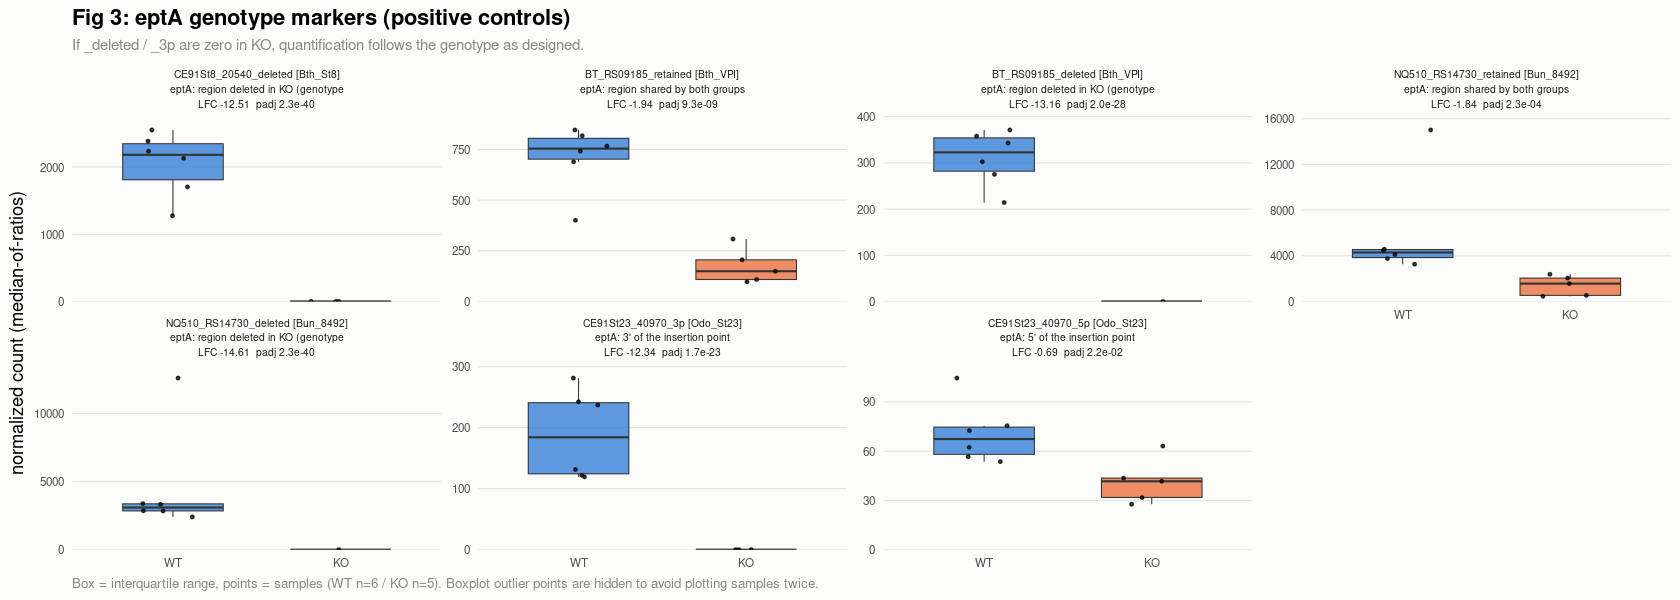

In [25]:
# ── Same figures, English labels（PDF / EPS 出力用）──────────────
# セル14図 と中身は同じ3枚で、文字だけ英語にしたもの。
#   例) ggsave('fig_top20_up.pdf', p1_gene_en, width = 14, height = 9)
#
# ★ eptA マーカーの product は GTF 内が日本語なので、ここで英語に置き換える
#   （図3 のパネル見出しに出るため）
library(ggplot2); library(tidyr)

prod_en = c(
  'eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）' =
      'eptA: region deleted in KO (genotype control)',
  'eptA: 両群に共通する領域（ここで比較する）' =
      'eptA: region shared by both groups',
  "eptA: 挿入点より3'側（K群でゼロなら転写終結）" =
      "eptA: 3' of the insertion point",
  "eptA: 挿入点より5'側（両群で転写される）" =
      "eptA: 5' of the insertion point")

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_group = c(WT = '#2a78d6', KO = '#eb6834')

de_lab_en = de %>%
    mutate(product_en = ifelse(product %in% names(prod_en),
                               prod_en[product], product),
           panel = sprintf('%s [%s]\n%s\nLFC %+.2f  padj %s',
                           gene_id, strain, substr(product_en, 1, 36),
                           LFC_shrunk, format(signif(padj, 2), scientific = TRUE)))

thm_en = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major.x = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(size = 6.2, lineheight = 1.2),
          axis.text = element_text(size = 7),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

gene_panels_en = function(ids, ttl, sub, ncol = 5) {
    d = norm_long %>% filter(gene_id %in% ids) %>%
        left_join(de_lab_en %>% dplyr::select(gene_id, panel), by = 'gene_id') %>%
        mutate(panel = factor(panel,
                              levels = de_lab_en$panel[match(ids, de_lab_en$gene_id)]))
    ggplot(d, aes(x = group, y = norm_count, fill = group)) +
        geom_boxplot(outlier.shape = NA, linewidth = 0.3, width = 0.6, alpha = 0.75) +
        geom_jitter(width = 0.18, size = 0.7, alpha = 0.8, colour = col_text) +
        scale_fill_manual(values = col_group) + guides(fill = 'none') +
        scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
        facet_wrap(~ panel, ncol = ncol, scales = 'free_y') +
        labs(title = ttl, subtitle = sub, x = NULL,
             y = 'normalized count (median-of-ratios)',
             caption = paste('Box = interquartile range, points = samples (WT n=6 / KO n=5).',
                             'Boxplot outlier points are hidden to avoid plotting samples twice.')) +
        thm_en
}

options(repr.plot.width = 14, repr.plot.height = 9)
p1_gene_en = gene_panels_en(up20,
    'Fig 1: Top 20 genes up in KO (ranked by shrunk LFC)',
    'eptA genotype markers are excluded here and shown separately in Fig 3.')
suppressWarnings(print(p1_gene_en))

options(repr.plot.width = 14, repr.plot.height = 9)
p2_gene_en = gene_panels_en(down20,
    'Fig 2: Top 20 genes down in KO (ranked by shrunk LFC)',
    'eptA genotype markers are excluded here and shown separately in Fig 3.')
suppressWarnings(print(p2_gene_en))

options(repr.plot.width = 14, repr.plot.height = 5)
p3_gene_en = gene_panels_en(mk,
    'Fig 3: eptA genotype markers (positive controls)',
    'If _deleted / _3p are zero in KO, quantification follows the genotype as designed.',
    ncol = 4)
suppressWarnings(print(p3_gene_en))

### 考察: 個別遺伝子の箱ひげ図（セル14図 の結果）

## 結論: 上位の変化は「量の増減」ではなく「オン/オフの切り替わり」

### ★ 図1 — 上昇 top20 は全部 `CE91St8_295xx`〜`297xx`（CPS 座位2）

**20遺伝子すべてが同じ座位。** しかも形が揃っている。

```
WT: ほぼ 0        KO: 100〜1,700
```

**WT では検出限界近く、KO で一斉に発現している。**
量が2倍・3倍になったのではなく、**座位が丸ごとオンになっている。**

これは**量的な調節ではなく、集団としてどの座位を使うかが切り替わった**形。
ステージ3 で CPS 座位の相転換（phase variation）と読んだことと整合する。

### ★ 図2 — 低下 top20 も座位単位

| 遺伝子 | 株 | LFC | product |
|---|---|---|---|
| `CE91St8_37650` / `37660` / `37670` / `37680` | Bth_St8 | −4.2〜−4.9 | **CPS 座位3** |
| `CE91St8_37610` / `37620` / `37630` | Bth_St8 | −4.9〜−5.1 | **CPS 座位3** |
| `CE91St8_37460` / `37480` / `37500` / `37510` | Bth_St8 | −3.7〜−4.8 | **CPS 座位3（上流側）** |
| `CE91St8_26070`〜`26110` | Bth_St8 | −3.6〜−4.0 | **CPS 座位1** |
| **`CE91St23_44470` / `44480`** | **Odo_St23** | **−4.8 / −5.2** | hypothetical（**新しい座位**） |
| **`BT_RS15610`** | **Bth_VPI** | **−3.88** | **cysteine synthase A** |
| **`CE91St8_09700`** | **Bth_St8** | **−3.85** | **cysteine synthase** |

**こちらも WT で発現 → KO でほぼ 0** という形。

**★ `CE91St23_44470` / `44480` はこれまで出ていなかった Odo_St23 の座位。**
`hypothetical protein` なので機能は不明。セル13 の検討で見つけた座位とも別。

### ★ cysteine synthase が2株で top20 に入る

**`BT_RS15610`（Bth_VPI、−3.88、baseMean 約10万）** と
**`CE91St8_09700`（Bth_St8、−3.85、baseMean 約17万）**。
どちらも**極めて高発現**で、**KO でほぼ完全に消えている**（図2 の該当パネル）。

セル12（PC1 負側）・セル13（`Bun_8492` の最高発現遺伝子 `NQ510_RS04250` −3.49）と合わせ、
**3株すべてで cysteine synthase が KO で強く低下。**

**これは「オン/オフ」ではなく、高発現遺伝子が1/10以下に落ちる形。**
CPS 座位の切り替わりとは**別の現象**として扱うべき。

→ **ステージ6 の経路解析で、株をまたぐ収束の最有力候補。**
システイン合成は**グルタチオン・硫黄代謝の入口**なので、
セル13 で見た抗酸化系（SOD・チオレドキシン・チオールペルオキシダーゼ）の低下と
同じ流れで読める可能性がある。

**※ ただしセル13 の compositionality の留保がかかる。**
これらは高発現遺伝子なので、「相対的に下がった」以上のことは言えない。

### 図3 — 陽性対照は設計どおり

4つの `_deleted` / `_3p` が **KO で完全に 0**（点が全部 0 の位置にある）。
`_retained` / `_5p` は両群にあり、KO で低め（セル9 の考察のとおり）。

## 申し送り

| 項目 | 内容 |
|---|---|
| **CPS 座位はオン/オフ** | LFC の大きさで並べると上位が CPS 座位で埋まる。**経路解析では座位をまとめて1事象として扱う**（CLAUDE.md §7 ステージ6） |
| **cysteine synthase** | **3株で一致。ステージ6 の収束の最有力候補。** 硫黄代謝・グルタチオンの経路で確認する |
| **`CE91St23_44470`/`44480`** | 新しい Odo_St23 の座位。`hypothetical` なので **`Preferred_name` / `PFAMs` / `Description` を引く**（CLAUDE.md §7 申し送り6） |

## セル15: 感度解析 — `eptAW4` を除いて同じ解析をやり直す

`eptAW4` は**5つの指標すべてで11検体中もっとも外れていた**（セル12 の考察）。

| 指標 | eptAW4 | 他10検体 |
|---|---|---|
| RLE の IQR | **1.373** | 0.486〜1.011 |
| PC2 | **−96.1** | −22.6〜+44.5 |
| 同群内の平均距離 | **100.2** | 44.9〜94.3 |
| Salmon 整合率 | **95.66%** | 96.59〜97.68% |
| `Odo_St23` シェア | **2.09%** | 2.73〜4.00% |

**ただし品質は悪くない**（rRNA 除去はむしろ11検体で最良、CDS マップ率も最高）ので**除外はしない。**
代わりに**除いたら結論が変わるか**をここで確かめる。**n = 5 vs 5** になる。

### ★ セル4〜7 と同じ手順を最初からやり直す

**size factor も dispersion も検体の集合に依存する**ので、
検体を1つ減らしたら**全部やり直す**必要がある。
`results()` だけ取り直すのでは足りない。

### 見るのは「結論が変わるか」であって「DEG 数が同じか」ではない

検体を減らせば検出力は必ず変わる。確認するのは次の3点。

1. **元の DEG がどれだけ残るか**
2. **LFC の向きが変わる遺伝子があるか**
3. **陽性対照（eptA マーカー）と主要な所見（CPS 座位）が保たれるか**

In [26]:
# ── 感度解析: eptAW4 を除いて同じ解析をやり直す ────────────────────
# eptAW4 は5つの指標すべてで11検体中もっとも外れていた（セル12 の考察）。
#   RLE の IQR 1.373 / PC2 −96.1 / 同群内平均距離 100.2 /
#   Salmon 整合率 95.66% / Odo_St23 シェア 2.09%
# ただし品質は悪くない（rRNA 除去はむしろ最良）ので除外はしない。
# 代わりに【除いたら結論が変わるか】をここで確かめる。n=5 vs 5 になる。
#
# ★ セル4〜7 とまったく同じ手順を、検体を1つ減らしてやり直す。
#   size factor も dispersion も検体集合に依存するので、必ず全部やり直す

keep_s = colnames(cnt_de) != 'eptAW4'
dds_s  = DESeqDataSetFromMatrix(cnt_de[, keep_s], coldata[keep_s, , drop = FALSE], ~ group)
dds_s$group = relevel(dds_s$group, ref = 'WT')
dds_s = estimateSizeFactors(dds_s)
dds_s = estimateDispersions(dds_s, quiet = TRUE)
dds_s = nbinomWaldTest(dds_s, quiet = TRUE)
res_s = results(dds_s, alpha = 0.05)
shr_s = lfcShrink(dds_s, coef = 'group_KO_vs_WT', type = 'apeglm', quiet = TRUE)

cmp = data.frame(gene_id = rownames(res_s), strain = feat_de$strain,
                 LFC_all = de$LFC_shrunk, padj_all = de$padj,
                 LFC_s   = round(shr_s$log2FoldChange, 4), padj_s = res_s$padj) %>%
      mutate(sig_all = !is.na(padj_all) & padj_all < 0.05,
             sig_s   = !is.na(padj_s)   & padj_s   < 0.05)

cat("■ Table 1: 全体の比較（padj < 0.05）\n")
data.frame(
    item = c('検定された遺伝子', 'DEG', 'うち上昇', 'うち低下'),
    `全11検体` = c(sum(!is.na(cmp$padj_all)), sum(cmp$sig_all),
                   sum(cmp$sig_all & cmp$LFC_all > 0), sum(cmp$sig_all & cmp$LFC_all < 0)),
    `eptAW4を除く` = c(sum(!is.na(cmp$padj_s)), sum(cmp$sig_s),
                       sum(cmp$sig_s & cmp$LFC_s > 0), sum(cmp$sig_s & cmp$LFC_s < 0)),
    check.names = FALSE)

cat("\n■ Table 2: DEG の一致\n")
both = cmp$sig_all & cmp$sig_s
data.frame(
    item = c('両方で DEG', '全11検体でのみ DEG', 'eptAW4 除外でのみ DEG',
             '両方での一致率(%)', 'LFC の相関（検定された遺伝子）',
             '向きが変わった DEG'),
    value = c(sum(both), sum(cmp$sig_all & !cmp$sig_s), sum(!cmp$sig_all & cmp$sig_s),
              round(100 * sum(both) / sum(cmp$sig_all | cmp$sig_s), 1),
              round(cor(cmp$LFC_all, cmp$LFC_s, use = 'complete.obs'), 4),
              sum(both & sign(cmp$LFC_all) != sign(cmp$LFC_s))),
    check.names = FALSE)

cat("\n■ Table 3: 株ごとの DEG 数\n")
cmp %>% group_by(strain) %>%
    summarise(DEG_all = sum(sig_all), DEG_woW4 = sum(sig_s),
              差 = sum(sig_s) - sum(sig_all),
              両方 = sum(sig_all & sig_s),
              LFC相関 = round(cor(LFC_all, LFC_s, use = 'complete.obs'), 4),
              .groups = 'drop') %>% as.data.frame()

cat("\n■ Table 4: eptA マーカーと CPS 座位は保たれているか\n")
cps2 = sprintf('CE91St8_%05d', seq(2954, 2988) * 10)
rbind(
  cmp %>% filter(gene_id %in% de$gene_id[de$marker]) %>%
      mutate(group = 'eptA マーカー'),
  cmp %>% filter(gene_id %in% cps2) %>% mutate(group = 'CPS 座位2')) %>%
  group_by(group) %>%
  summarise(n = dplyr::n(), DEG_all = sum(sig_all), DEG_woW4 = sum(sig_s),
            LFC_all_中央値 = round(median(LFC_all), 2),
            LFC_woW4_中央値 = round(median(LFC_s), 2), .groups = 'drop') %>%
  as.data.frame()

■ Table 1: 全体の比較（padj < 0.05）


item,全11検体,eptAW4を除く
<chr>,<int>,<int>
検定された遺伝子,9636,9784
DEG,3126,4206
うち上昇,1616,2270
うち低下,1510,1936



■ Table 2: DEG の一致


item,value
<chr>,<dbl>
両方で DEG,3032.0000
全11検体でのみ DEG,94.0000
eptAW4 除外でのみ DEG,1174.0000
両方での一致率(%),70.5000
LFC の相関（検定された遺伝子）,0.9655
向きが変わった DEG,0.0000



■ Table 3: 株ごとの DEG 数


strain,DEG_all,DEG_woW4,差,両方,LFC相関
<chr>,<int>,<int>,<int>,<int>,<dbl>
Bth_St8,601,793,192,569,0.9760
Bth_VPI,535,667,132,513,0.9630
Bun_8492,1397,1729,332,1367,0.9469
Odo_St23,592,1015,423,582,0.9782
pME008,1,2,1,1,0.9065



■ Table 4: eptA マーカーと CPS 座位は保たれているか


group,n,DEG_all,DEG_woW4,LFC_all_中央値,LFC_woW4_中央値
<chr>,<int>,<int>,<int>,<dbl>,<dbl>
CPS 座位2,35,35,35,5.08,5.72
eptA マーカー,7,7,7,-12.34,-12.43


### 考察: `eptAW4` を除いた感度解析（セル15 の結果）

## 結論: **結論は変わらない。`eptAW4` は検出力を下げていただけ。**

| 確認 | 結果 |
|---|---|
| **元の DEG 3,126 のうち残ったもの** | **3,032（97.0%）** |
| **向きが変わった DEG** | **0 件** |
| **LFC の相関** | **r = 0.9655** |
| eptA マーカー 7件 | **7件とも DEG のまま**（LFC 中央値 −12.34 → −12.43） |
| CPS 座位2 の 35遺伝子 | **35件とも DEG のまま**（LFC 中央値 +5.08 → +5.72） |

**失われたのは 94 件（3.0%）だけ**で、**符号が反転した遺伝子は1つもない。**

## ★ 除くと DEG が増える（3,126 → 4,206）

検体を減らしたのに DEG が **1,080 件増えた。**

|-| 全11検体 | eptAW4 を除く |
|---|---|---|
| 検定された遺伝子 | 9,636 | **9,784** |
| DEG | 3,126 | **4,206** |

**理由**: `eptAW4` は**群内のばらつきを押し上げていた**（RLE の IQR 1.373 は11検体で最大）。
DESeq2 は群内のばらつきから dispersion を推定するので、
**ばらつきの大きい検体が1つあると全遺伝子の検定が保守的になる。**
それを除くと dispersion が下がり、**同じ差でも有意になる。**

**新たに DEG になった 1,174 件は「`eptAW4` を除いて初めて見えた差」**であって、
`eptAW4` が作っていた偽の差ではない（`eptAW4` を含む版の方が保守的）。

### 株ごとに見ると `Odo_St23` で最も増える

| 株 | 全11検体 | eptAW4 除外 | 差 | LFC 相関 |
|---|---|---|---|---|
| Odo_St23 | 592 | **1,015** | **+423** | 0.978 |
| Bun_8492 | 1,397 | 1,729 | +332 | 0.947 |
| Bth_St8 | 601 | 793 | +192 | 0.976 |
| Bth_VPI | 535 | 667 | +132 | 0.963 |

**`Odo_St23` が最も増える**のは、`eptAW4` の `Odo_St23` シェアが 2.09% と
11検体で最低（他の WT は 2.91〜4.00%）で、**この株のばらつきを特に大きくしていた**ため。

## 方針（変更なし）

**`eptAW4` は除外しない。**

- 品質指標は良好（rRNA 除去は11検体で最良、CDS マップ率も最高）
- **除いても結論が変わらない**（上記）
- 除くと n=5 vs 5 になり、**群内のばらつきの推定がさらに不安定になる**

→ **主解析は全11検体。** 本文・図では**全11検体の結果を示す。**

**※ ただし「DEG 数」を述べるときは注意する。**
3,126 という数は `eptAW4` を含むことで保守的に出た値であり、
**除けば 4,206 になる。** 数そのものは検体集合に強く依存するので、
**「DEG が何件あった」を主張に使わない。**

## セル16: 感度解析 — `minMQS=0` のカウントで同じ解析をやり直す

過去プロジェクトは `count_allmapped` / `_fractionmode` / `_uniquemapped` の**3モードを
別notebook で並走**させていた（**突き合わせはしていない**）。今回は同じ notebook 内で突き合わせる。

|-| 多重マップの扱い |
|---|---|
| 主解析 `minMQS=10` | **捨てる**（保守的） |
| ここ `minMQS=0` | bowtie2 が選んだ**最良の1箇所に全部入れる** |

### ★ 遺伝子集合はセル4 の 9,795 に固定する

固定しないと**「カウントの違い」と「遺伝子集合の違い」が混ざる。**

In [27]:
# ── 感度解析: minMQS=0 のカウントで同じ解析をやり直す ────────────
# 過去プロジェクトは count_allmapped / _fractionmode / _uniquemapped の
# 3モードを【別notebook で並走】させていた（突き合わせはしていない）。
# 今回は同じ notebook 内で突き合わせる。これがその1本目。
#
#   主解析 minMQS=10 … 多重マップを捨てる（保守的）
#   ここ   minMQS=0  … bowtie2 が選んだ最良の1箇所に全部入れる
#
# ★ 遺伝子集合はセル4 で決めた 9,795 に固定する。
#   こうしないと「カウントの違い」と「遺伝子集合の違い」が混ざる

cnt_q0_de = cnt_q0[feat_de$gene_id, ]
dds_q0 = DESeqDataSetFromMatrix(cnt_q0_de, coldata, ~ group)
dds_q0$group = relevel(dds_q0$group, ref = 'WT')
dds_q0 = estimateSizeFactors(dds_q0)
dds_q0 = estimateDispersions(dds_q0, quiet = TRUE)
dds_q0 = nbinomWaldTest(dds_q0, quiet = TRUE)
res_q0 = results(dds_q0, alpha = 0.05)
shr_q0 = lfcShrink(dds_q0, coef = 'group_KO_vs_WT', type = 'apeglm', quiet = TRUE)

q0 = data.frame(gene_id = rownames(res_q0), strain = feat_de$strain,
                marker = feat_de$marker,
                LFC_q10 = de$LFC_shrunk, padj_q10 = de$padj,
                LFC_q0  = round(shr_q0$log2FoldChange, 4), padj_q0 = res_q0$padj) %>%
     mutate(sig10 = !is.na(padj_q10) & padj_q10 < 0.05,
            sig0  = !is.na(padj_q0)  & padj_q0  < 0.05)

cat("■ Table 1: minMQS=10（主解析）と minMQS=0 の比較\n")
data.frame(
    item = c('総カウント(M)', '検定された遺伝子', 'DEG', 'うち上昇', 'うち低下'),
    `minMQS=10` = c(round(sum(cnt_de)/1e6, 1), sum(!is.na(q0$padj_q10)), sum(q0$sig10),
                    sum(q0$sig10 & q0$LFC_q10 > 0), sum(q0$sig10 & q0$LFC_q10 < 0)),
    `minMQS=0`  = c(round(sum(cnt_q0_de)/1e6, 1), sum(!is.na(q0$padj_q0)), sum(q0$sig0),
                    sum(q0$sig0 & q0$LFC_q0 > 0), sum(q0$sig0 & q0$LFC_q0 < 0)),
    check.names = FALSE)

cat("\n■ Table 2: 結論が変わるか\n")
both = q0$sig10 & q0$sig0
data.frame(
    item = c('主解析の DEG のうち残るもの', '残存率(%)', '向きが変わった DEG',
             'LFC の相関', 'minMQS=0 でのみ DEG'),
    value = c(sum(both), round(100*sum(both)/sum(q0$sig10), 1),
              sum(both & sign(q0$LFC_q10) != sign(q0$LFC_q0)),
              round(cor(q0$LFC_q10, q0$LFC_q0, use='complete.obs'), 4),
              sum(!q0$sig10 & q0$sig0)),
    check.names = FALSE)

cat("\n■ Table 3: 株ごと（Bth 2株で差が出るはず。多重マップはそこで起きる）\n")
q0 %>% group_by(strain) %>%
    summarise(DEG_q10 = sum(sig10), DEG_q0 = sum(sig0),
              両方 = sum(sig10 & sig0),
              LFC相関 = round(cor(LFC_q10, LFC_q0, use='complete.obs'), 4),
              `LFC差の中央値` = round(median(LFC_q0 - LFC_q10, na.rm=TRUE), 3),
              .groups='drop') %>% as.data.frame()

cat("\n■ Table 4: 陽性対照と CPS 座位\n")
cps2 = sprintf('CE91St8_%05d', seq(2954, 2988)*10)
rbind(q0 %>% filter(marker) %>% mutate(g='eptA マーカー'),
      q0 %>% filter(gene_id %in% cps2) %>% mutate(g='CPS 座位2')) %>%
  group_by(g) %>%
  summarise(n=dplyr::n(), DEG_q10=sum(sig10), DEG_q0=sum(sig0),
            LFC_q10中央値=round(median(LFC_q10),2),
            LFC_q0中央値=round(median(LFC_q0),2), .groups='drop') %>% as.data.frame()

■ Table 1: minMQS=10（主解析）と minMQS=0 の比較


item,minMQS=10,minMQS=0
<chr>,<dbl>,<dbl>
総カウント(M),262.2,275.1
検定された遺伝子,9636.0,9630.0
DEG,3126.0,3150.0
うち上昇,1616.0,1632.0
うち低下,1510.0,1518.0



■ Table 2: 結論が変わるか


item,value
<chr>,<dbl>
主解析の DEG のうち残るもの,3088.0000
残存率(%),98.8000
向きが変わった DEG,0.0000
LFC の相関,0.9984
minMQS=0 でのみ DEG,62.0000



■ Table 3: 株ごと（Bth 2株で差が出るはず。多重マップはそこで起きる）


strain,DEG_q10,DEG_q0,両方,LFC相関,LFC差の中央値
<chr>,<int>,<int>,<int>,<dbl>,<dbl>
Bth_St8,601,613,584,0.9984,0.000
Bth_VPI,535,539,517,0.9945,0.000
Bun_8492,1397,1404,1397,0.9993,0.000
Odo_St23,592,593,589,0.9999,0.000
pME008,1,1,1,1.0000,0.001



■ Table 4: 陽性対照と CPS 座位


g,n,DEG_q10,DEG_q0,LFC_q10中央値,LFC_q0中央値
<chr>,<int>,<int>,<int>,<dbl>,<dbl>
CPS 座位2,35,35,35,5.08,5.08
eptA マーカー,7,7,7,-12.34,-11.39


### 考察: `minMQS=0` での感度解析（セル16 の結果）

## 結論: **ほぼ同一。多重マップの扱いは結論を変えない。**

| 確認 | 結果 |
|---|---|
| 主解析の DEG 3,126 のうち残るもの | **3,088（98.8%）** |
| 向きが変わった DEG | **0 件** |
| LFC の相関 | **r = 0.9984** |
| DEG 総数 | 3,126 → 3,150（+24） |
| eptA マーカー / CPS 座位2 | **7件・35件とも DEG のまま** |

株ごとの LFC 相関も **0.9945〜0.9999**、**LFC 差の中央値は全株 0.000。**

## なぜここまで一致するのか

**セル4 の mappability ≥ 0.5 フィルタが、多重マップの起きる遺伝子を先に落としているから。**

多重マップは `Bth_VPI` と `Bth_St8` の共通領域（ANI 98%）で起きるが、
**そういう遺伝子は mappability が低いのでフィルタで除かれている。**
残った 9,795 遺伝子は**もともと多重マップがほとんど無い**ので、
MAPQ で切っても切らなくても結果が変わらない。

→ **多重マップの問題は、DE に入る前のフィルタで既に処理済み。**
**この感度解析は「フィルタが効いていること」の確認になっている。**

**※ 総カウントは 262.2 M → 275.1 M（+4.9%）に増える。**
この 4.9% は mappability の高い遺伝子にも多少の多重マップがあることを示すが、
**群間で均等にかかるので LFC は動かない。**

## セル17: 感度解析 — Salmon（EM 按分）のカウントで同じ解析をやり直す

過去プロジェクトの `count_allmapped_fractionmode` に相当する位置づけ。
featureCounts は多重マップを**捨てる**か**最良ヒットに入れる**かしかできないが、
**Salmon は EM で確率的に按分する**（CLAUDE.md §7 ステージ3）。

### tximport を使う（CLAUDE.md §7 ステージ5 申し送り1）

Salmon の **`EffectiveLength` から長さオフセットを作って DESeq2 に渡す**仕組み。
`NumReads` をそのまま渡すより正しい。
**転写産物名 = `gene_id`** なので `txOut = TRUE`（`tx2gene` は不要）。

### 重複クラスタの影響はこの遺伝子集合では無い

Salmon の index からは配列が完全に同一の転写産物 **737本**が落ちている
（うち504本が `Bth_VPI`。CLAUDE.md §リファレンス）。

**ただしセル4 の 9,795 遺伝子は 100% が Salmon にも存在する。**
落ちた737本は **mappability が低く、セル4 のフィルタで既に除かれていた。**

In [28]:
# ── 感度解析: Salmon（EM 按分）のカウントで同じ解析をやり直す ──────
# 過去プロジェクトの count_allmapped_fractionmode に相当する位置づけ。
# featureCounts は多重マップを捨てる（minMQS=10）か最良ヒットに入れる（=0）
# しかできないが、Salmon は EM で【確率的に按分】する（CLAUDE.md §7 ステージ3）。
#
# ★ tximport を使う（CLAUDE.md §7 ステージ5 申し送り1）。
#   Salmon の EffectiveLength から長さオフセットを作って DESeq2 に渡す仕組みで、
#   NumReads をそのまま渡すより正しい。
#   転写産物名 = gene_id なので txOut = TRUE（tx2gene は不要）
#
# ★ Salmon は index から重複クラスタ737本が落ちている（CLAUDE.md §リファレンス）。
#   そのうち504本が Bth_VPI。共通する遺伝子だけで比べる
library(tximport)

files = file.path(path_salmon, rownames(coldata), 'quant.sf')
names(files) = rownames(coldata)
stopifnot(all(file.exists(files)))

txi = tximport(files, type = 'salmon', txOut = TRUE)

com_s = intersect(feat_de$gene_id, rownames(txi$counts))
cat(sprintf("■ セル4 の 9,795 遺伝子のうち Salmon にもあるもの: %d（%.1f%%）\n",
            length(com_s), 100*length(com_s)/nrow(feat_de)))
print(table(欠ける株 = feat_de$strain[!feat_de$gene_id %in% com_s]))

txi_s = lapply(txi[c('abundance','counts','length')],
               function(x) x[com_s, rownames(coldata), drop = FALSE])
txi_s$countsFromAbundance = txi$countsFromAbundance

dds_sa = DESeqDataSetFromTximport(txi_s, coldata, ~ group)
dds_sa$group = relevel(dds_sa$group, ref = 'WT')
dds_sa = estimateSizeFactors(dds_sa)
dds_sa = estimateDispersions(dds_sa, quiet = TRUE)
dds_sa = nbinomWaldTest(dds_sa, quiet = TRUE)
res_sa = results(dds_sa, alpha = 0.05)
shr_sa = lfcShrink(dds_sa, coef = 'group_KO_vs_WT', type = 'apeglm', quiet = TRUE)

sa = data.frame(gene_id = com_s,
                strain  = feat_de$strain[match(com_s, feat_de$gene_id)],
                marker  = feat_de$marker[match(com_s, feat_de$gene_id)],
                LFC_fc  = de$LFC_shrunk[match(com_s, de$gene_id)],
                padj_fc = de$padj[match(com_s, de$gene_id)],
                LFC_sa  = round(shr_sa$log2FoldChange, 4), padj_sa = res_sa$padj) %>%
     mutate(sig_fc = !is.na(padj_fc) & padj_fc < 0.05,
            sig_sa = !is.na(padj_sa) & padj_sa < 0.05)

cat("\n■ Table 1: featureCounts(minMQS=10) と Salmon(EM) の比較\n")
data.frame(
    item = c('比較した遺伝子', '検定された遺伝子', 'DEG', 'うち上昇', 'うち低下'),
    featureCounts = c(nrow(sa), sum(!is.na(sa$padj_fc)), sum(sa$sig_fc),
                      sum(sa$sig_fc & sa$LFC_fc > 0), sum(sa$sig_fc & sa$LFC_fc < 0)),
    Salmon        = c(nrow(sa), sum(!is.na(sa$padj_sa)), sum(sa$sig_sa),
                      sum(sa$sig_sa & sa$LFC_sa > 0), sum(sa$sig_sa & sa$LFC_sa < 0)),
    check.names = FALSE)

cat("\n■ Table 2: 結論が変わるか\n")
both = sa$sig_fc & sa$sig_sa
data.frame(
    item = c('主解析の DEG のうち残るもの', '残存率(%)', '向きが変わった DEG',
             'LFC の相関', 'Salmon でのみ DEG'),
    value = c(sum(both), round(100*sum(both)/sum(sa$sig_fc), 1),
              sum(both & sign(sa$LFC_fc) != sign(sa$LFC_sa)),
              round(cor(sa$LFC_fc, sa$LFC_sa, use='complete.obs'), 4),
              sum(!sa$sig_fc & sa$sig_sa)),
    check.names = FALSE)

cat("\n■ Table 3: 株ごと\n")
sa %>% group_by(strain) %>%
    summarise(n=dplyr::n(), DEG_fc=sum(sig_fc), DEG_salmon=sum(sig_sa),
              両方=sum(sig_fc & sig_sa),
              LFC相関=round(cor(LFC_fc, LFC_sa, use='complete.obs'), 4),
              `LFC差の中央値`=round(median(LFC_sa-LFC_fc, na.rm=TRUE), 3),
              .groups='drop') %>% as.data.frame()

cat("\n■ Table 4: 陽性対照と CPS 座位\n")
cps2 = sprintf('CE91St8_%05d', seq(2954, 2988)*10)
rbind(sa %>% filter(marker) %>% mutate(g='eptA マーカー'),
      sa %>% filter(gene_id %in% cps2) %>% mutate(g='CPS 座位2')) %>%
  group_by(g) %>%
  summarise(n=dplyr::n(), DEG_fc=sum(sig_fc), DEG_salmon=sum(sig_sa),
            LFC_fc中央値=round(median(LFC_fc),2),
            LFC_salmon中央値=round(median(LFC_sa),2), .groups='drop') %>% as.data.frame()

cat("\n■ Table 5: eptA マーカーの内訳（Salmon で有意でなくなるものがある）\n")
sa %>% filter(marker) %>%
  mutate(LFC_fc=round(LFC_fc,2), LFC_sa=round(LFC_sa,2),
         padj_fc=signif(padj_fc,2), padj_sa=signif(padj_sa,2)) %>%
  dplyr::select(gene_id, strain, LFC_fc, padj_fc, LFC_sa, padj_sa, sig_fc, sig_sa) %>%
  arrange(gene_id) %>% as.data.frame()

reading in files with read_tsv



1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 




■ セル4 の 9,795 遺伝子のうち Salmon にもあるもの: 9795（100.0%）
< table of extent 0 >


using counts and average transcript lengths from tximport

using 'avgTxLength' from assays(dds), correcting for library size




■ Table 1: featureCounts(minMQS=10) と Salmon(EM) の比較


item,featureCounts,Salmon
<chr>,<int>,<int>
比較した遺伝子,9795,9795
検定された遺伝子,9636,9623
DEG,3126,2980
うち上昇,1616,1539
うち低下,1510,1441


... (4 outputs left out)


■ Table 4: 陽性対照と CPS 座位


g,n,DEG_fc,DEG_salmon,LFC_fc中央値,LFC_salmon中央値
<chr>,<int>,<int>,<int>,<dbl>,<dbl>
CPS 座位2,35,35,33,5.08,5.13
eptA マーカー,7,7,4,-12.34,-12.11



■ Table 5: eptA マーカーの内訳（Salmon で有意でなくなるものがある）


,gene_id,strain,LFC_fc,padj_fc,LFC_sa,padj_sa,sig_fc,sig_sa
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<lgl>
BT_RS09185_deleted,BT_RS09185_deleted,Bth_VPI,-13.16,2.0e-28,-12.14,1.2e-23,TRUE,TRUE
BT_RS09185_retained,BT_RS09185_retained,Bth_VPI,-1.94,9.3e-09,-1.48,1.5e-05,TRUE,TRUE
CE91St23_40970_3p,CE91St23_40970_3p,Odo_St23,-12.34,1.7e-23,-12.11,1.4e-22,TRUE,TRUE
CE91St23_40970_5p,CE91St23_40970_5p,Odo_St23,-0.69,2.2e-02,0.08,8.6e-01,TRUE,FALSE
CE91St8_20540_deleted,CE91St8_20540_deleted,Bth_St8,-12.51,2.3e-40,-12.54,1.3e-40,TRUE,TRUE
NQ510_RS14730_deleted,NQ510_RS14730_deleted,Bun_8492,-14.61,2.3e-40,-16.89,NA,TRUE,FALSE
NQ510_RS14730_retained,NQ510_RS14730_retained,Bun_8492,-1.84,2.3e-04,-0.46,2.9e-01,TRUE,FALSE


### 考察: Salmon での感度解析（セル17 の結果）

## 結論: **通常の遺伝子では結論は変わらない。ただし eptA マーカーには使えない。**

| 確認 | 結果 |
|---|---|
| 主解析の DEG 3,126 のうち残るもの | **2,864（91.6%）** |
| **向きが変わった DEG** | **0 件** |
| LFC の相関 | **r = 0.9895** |
| DEG 総数 | 3,126 → 2,980（−146） |
| CPS 座位2（35遺伝子） | 33件が DEG（LFC 中央値 +5.08 → +5.13） |

株ごとの LFC 相関は **0.9868〜0.9900**、LFC 差の中央値は **−0.004〜−0.007**。
**Salmon の方がやや保守的**（DEG が 146件少ない）だが、**向きが変わる遺伝子は1つもない。**

## ★ ただし eptA マーカー 7件のうち3件が Salmon では有意でなくなる

| gene_id | featureCounts | Salmon | |
|---|---|---|---|
| `BT_RS09185_deleted` | −13.16 (2e-28) | −12.14 (1e-23) | OK |
| `CE91St8_20540_deleted` | −12.51 (2e-40) | −12.54 (1e-40) | OK |
| `CE91St23_40970_3p` | −12.34 (2e-23) | −12.11 (1e-22) | OK |
| `BT_RS09185_retained` | −1.94 (9e-09) | −1.48 (2e-05) | OK |
| **`NQ510_RS14730_deleted`** | −14.61 (2e-40) | **padj = NA** | **★ 検定から外れる** |
| **`NQ510_RS14730_retained`** | −1.84 (2e-04) | −0.46 (**0.29**) | **★ 有意でなくなる** |
| **`CE91St23_40970_5p`** | −0.69 (0.022) | **+0.08** (**0.86**) | **★ 向きが逆** |

### 理由1: `NQ510_RS14730_deleted` は `eptAW4` のせいで外れ値扱いになる

正規化カウント（Salmon 版）:
```
WT: 2286  2284  1975  9505  1908  1624      ← eptAW4 だけ 4〜5倍
KO:    0     0     0     0     0
```

**`maxCooks = 8.825` が外れ値の閾値 8.022 を超え**、DESeq2 が検定から外した。
featureCounts 版では **7.264 で閾値未満**だったので残っていた。

**原因は `eptAW4`**（セル12・15 で見た外れ値）。
**featureCounts 版では境界すれすれで残っていたものが、Salmon の正規化で超えた。**

### 理由2: `_retained` / `_5p` は短いので実効長の補正が大きい

| feature | Length | EffectiveLength | 補正の大きさ |
|---|---|---|---|
| `CE91St23_40970_5p` | 337 | **107** | **3.1倍** |
| `NQ510_RS14730_deleted` | 575 | 308 | 1.9倍 |
| 通常の CDS | 1,000〜2,000 | 長さ − 約270 | 1.2〜1.4倍 |

**短い feature ほど実効長の補正が大きく、推定が不安定になる。**
featureCounts は長さ補正をしないので、**これらの feature では featureCounts の方が安定。**

## 方針

| 用途 | 使うもの |
|---|---|
| **通常の遺伝子の DE** | **featureCounts `minMQS=10`**（主解析）。Salmon は感度解析として一致を確認済み |
| **eptA の遺伝子型マーカー** | **featureCounts のみ。Salmon は使わない**（短い feature で不安定） |
| 経路解析（ステージ6） | featureCounts。**Salmon で消える 262件が結論を変えないことは確認済み** |

## 3つの感度解析のまとめ

| 感度解析 | DEG 残存率 | LFC 相関 | 向きの反転 |
|---|---|---|---|
| `eptAW4` 除外（セル15） | **97.0%** | 0.9655 | **0** |
| `minMQS=0`（セル16） | **98.8%** | 0.9984 | **0** |
| Salmon EM（セル17） | **91.6%** | 0.9895 | **0** |

**3本すべてで向きの反転が0件。** (A) の結論は
**外れ値の扱い・多重マップの扱い・定量ツールのいずれにも依存しない。**

## セル18: 結果を保存する

### ★★ このセルは notebook のほぼ全セルに依存する

依存が欠けたまま走ると**静かに不完全な表を書き出す**ので、
**先に必要なオブジェクトを点検して、足りなければどのセルを実行すべきか表示して止める。**

| 必要なオブジェクト | 作るセル |
|---|---|
| `coldata` | セル3 |
| `cnt_de` / `feat_de` | セル4 |
| `dds` / `tbl_sf` | セル5 |
| `de` | セル7 |
| **`gtf_count`、および `de` の座標列** | **セル9** |
| `pca` / `ve` / `pca_ex` / `ve_ex` | セル12 |
| `summary_tbl` | セル13 |
| `cmp` / `q0` / `sa` | セル15 / 16 / 17 |

**※ 特にセル9 を飛ばすと、`de` に座標列が無いまま 36列ではなく 32列で保存される。**
そのため座標列の有無も別途チェックしている。

`vsd`（セル10）だけは無ければこのセルで作る（計算が安いため）。


**方針: scratch 側（`DESeq2/`）に全部置き、小さくて重要なものだけ project 側（`refqc/`）に複製する。**

### ★ `de` に列を足してから保存する

主解析の表（`de`、17列）だけでは**ステージ6 の最終図が作れない**ので、
**36列**にしてから保存する。

| 足す列 | 用途 |
|---|---|
| `norm_WT_mean` / `norm_KO_mean` / **`norm_diff`** | **担い手の順位付け。遺伝子数ではなく転写量で付ける**（CLAUDE.md §7 ステージ6） |
| `biotype` / `mappability` | 低 mappability の遺伝子を後から確認できるように |
| `Preferred_name` / `KEGG_ko` / `KEGG_Pathway` / `COG_category` / `PFAMs` / `EC` / `CAZy` / `Description` | **これだけでステージ6 の TERM2GENE が作れる。** `product` だけでは `neuA` も `fnlA` も見逃す（CLAUDE.md §7 申し送り6） |
| `LFC_woW4` / `padj_woW4` / `LFC_q0` / `padj_q0` / `LFC_salmon` / `padj_salmon` | **3つの感度解析を統合**（セル15・16・17） |

### 保存するもの

| 場所 | ファイル | 内容 |
|---|---|---|
| 両方 | **`A_de.csv` / `stage5A_de.csv`** | **★ 1遺伝子1行の全結果（36列）** |
| 両方 | `A_strain_summary.csv` | 株ごとの DEG 数・カウント（セル13） |
| 両方 | `A_sizefactors.csv` | size factor（セル5） |
| 両方 | `A_pca_scores.csv` / `A_pca_variance.csv` | 主成分得点と寄与率（セル12） |
| scratch | **`A_input_counts.csv` / `A_input_feat.csv`** | **★ 5_2（B）が同じ入力を使うため** |
| scratch | `A_normalized_counts.csv` / `A_vst.csv` | 個別遺伝子の図・PCA・ヒートマップ用 |
| scratch | **`A_dds.rds`** | `DESeqDataSet`。再計算なしで (A) を再現できる |
| scratch | `A_all.rds` | 上をまとめた list |

**大きい行列（カウント・VST・dds）は project に複製しない**（git 管理側を重くしないため）。

In [29]:
# ── 結果を保存する ─────────────────────────────────────────────
# 方針: scratch 側（path_de）に全部置き、そのうち小さくて重要なものだけ
#       project 側（refqc/）に複製する。
#
# ★★ このセルは notebook のほぼ全セルに依存する。
#   依存が欠けたまま走ると【静かに不完全な表を書き出す】ので、先に点検して止める。
#   （実際、セル9 を飛ばすと de に座標列が無く、36列ではなく32列で保存されてしまう）
library(stringr)

need = c(
    coldata      = 'セル3',   cnt_de  = 'セル4',   feat_de = 'セル4',
    dds          = 'セル5',   tbl_sf  = 'セル5',
    de           = 'セル7',
    gtf_count    = 'セル9',
    pca          = 'セル12',  ve      = 'セル12',
    pca_ex       = 'セル12',  ve_ex   = 'セル12',
    summary_tbl  = 'セル13',
    cmp          = 'セル15',  q0      = 'セル16',  sa      = 'セル17')
miss = names(need)[!sapply(names(need), exists)]
if (length(miss) > 0) {
    stop(paste0('先に実行が必要です → ',
                paste(unique(need[miss]), collapse = ' / '),
                '\n  足りないオブジェクト: ', paste(miss, collapse = ', ')))
}

# de に座標列（セル9 で付く）があるかも確認する。無いと36列にならない
if (!all(c('contig','strand','start','end') %in% colnames(de))) {
    stop('de に座標列がありません。セル9 を実行してください（36列にならず32列で保存されます）')
}

# vsd は無ければ作る（セル10 で作られるが、無くても安い）
if (!exists('vsd')) vsd = varianceStabilizingTransformation(dds, blind = TRUE)

nc  = counts(dds, normalized = TRUE)
isw = coldata$group == 'WT'

# GTF から eggNOG のアノテーションを引く
ann = gtf_count %>%
    mutate(Preferred_name = str_match(attr, 'Preferred_name "([^"]*)"')[, 2],
           KEGG_ko        = str_match(attr, 'KEGG_ko "([^"]*)"')[, 2],
           KEGG_Pathway   = str_match(attr, 'KEGG_Pathway "([^"]*)"')[, 2],
           COG_category   = str_match(attr, 'COG_category "([^"]*)"')[, 2],
           PFAMs          = str_match(attr, 'PFAMs "([^"]*)"')[, 2],
           EC             = str_match(attr, 'EC "([^"]*)"')[, 2],
           CAZy           = str_match(attr, 'CAZy "([^"]*)"')[, 2],
           Description    = str_match(attr, 'Description "([^"]*)"')[, 2]) %>%
    distinct(gene_id, .keep_all = TRUE) %>%
    dplyr::select(gene_id, Preferred_name, KEGG_ko, KEGG_Pathway,
                  COG_category, PFAMs, EC, CAZy, Description)

de_out = de %>%
    # 群ごとの正規化カウント平均と正味リード増減
    mutate(norm_WT_mean = round(rowMeans(nc[, isw]), 1),
           norm_KO_mean = round(rowMeans(nc[, !isw]), 1),
           norm_diff    = round(rowMeans(nc[, !isw]) - rowMeans(nc[, isw]), 1)) %>%
    left_join(feat_de %>% dplyr::select(gene_id, biotype, mappability), by = 'gene_id') %>%
    left_join(ann, by = 'gene_id') %>%
    # 感度解析3本を統合（セル15・16・17）
    left_join(cmp %>% dplyr::select(gene_id, LFC_woW4 = LFC_s, padj_woW4 = padj_s),
              by = 'gene_id') %>%
    left_join(q0  %>% dplyr::select(gene_id, LFC_q0  = LFC_q0,  padj_q0  = padj_q0),
              by = 'gene_id') %>%
    left_join(sa  %>% dplyr::select(gene_id, LFC_salmon = LFC_sa, padj_salmon = padj_sa),
              by = 'gene_id')

cat(sprintf("■ de_out: %d 行 × %d 列\n", nrow(de_out), ncol(de_out)))
cat("  ", paste(colnames(de_out), collapse = ' / '), "\n")

# ── scratch 側に全部保存 ───────────────────────────────────────
f = function(x) file.path(path_de, x)
write.csv(de_out,       f('A_de.csv'),                row.names = FALSE)
write.csv(summary_tbl,  f('A_strain_summary.csv'),    row.names = FALSE)
write.csv(tbl_sf,       f('A_sizefactors.csv'),       row.names = FALSE)
write.csv(data.frame(sample = rownames(pca$x), group = as.character(coldata$group),
                     round(pca$x[, 1:4], 2), row.names = NULL),
          f('A_pca_scores.csv'), row.names = FALSE)
write.csv(data.frame(PC = paste0('PC', seq_along(ve)), variance_pct = ve,
                     variance_pct_markers_excluded = ve_ex),
          f('A_pca_variance.csv'), row.names = FALSE)
write.csv(cnt_de,       f('A_input_counts.csv'))
write.csv(feat_de,      f('A_input_feat.csv'),        row.names = FALSE)
write.csv(round(nc, 2), f('A_normalized_counts.csv'))
write.csv(round(assay(vsd), 4), f('A_vst.csv'))
saveRDS(dds, f('A_dds.rds'))
saveRDS(list(de = de_out, cnt = cnt_de, feat = feat_de, coldata = coldata,
             dds = dds, vsd = vsd, pca = pca, pca_ex = pca_ex,
             strain_summary = summary_tbl, sizefactors = tbl_sf),
        f('A_all.rds'))

# ── project 側に複製するもの（小さくて重要なものだけ）──────────────
to_project = c('A_de.csv'            = 'stage5A_de.csv',
               'A_strain_summary.csv'= 'stage5A_strain_summary.csv',
               'A_sizefactors.csv'   = 'stage5A_sizefactors.csv',
               'A_pca_scores.csv'    = 'stage5A_pca_scores.csv',
               'A_pca_variance.csv'  = 'stage5A_pca_variance.csv')
for (i in seq_along(to_project))
    file.copy(f(names(to_project)[i]),
              file.path(path_project, 'refqc', to_project[i]), overwrite = TRUE)

cat("\n■ 保存したもの\n")
rbind(
  data.frame(場所 = 'scratch', ファイル = list.files(path_de, pattern = '^A_'),
             MB = round(file.size(f(list.files(path_de, pattern = '^A_'))) / 1e6, 2)),
  data.frame(場所 = 'project', ファイル = unname(to_project),
             MB = round(file.size(file.path(path_project, 'refqc',
                                            unname(to_project))) / 1e6, 2)))

■ de_out: 9795 行 × 36 列
   gene_id / strain / product / marker / baseMean / LFC_raw / LFC_shrunk / lfcSE / stat_Wald / pvalue / padj / pvalue_LRT / padj_LRT / contig / strand / start / end / norm_WT_mean / norm_KO_mean / norm_diff / biotype / mappability / Preferred_name / KEGG_ko / KEGG_Pathway / COG_category / PFAMs / EC / CAZy / Description / LFC_woW4 / padj_woW4 / LFC_q0 / padj_q0 / LFC_salmon / padj_salmon 

■ 保存したもの


場所,ファイル,MB
<chr>,<chr>,<dbl>
scratch,A_all.rds,10.19
scratch,A_dds.rds,4.88
scratch,A_de.csv,4.34
scratch,A_input_counts.csv,0.57
scratch,A_input_feat.csv,0.78
scratch,A_normalized_counts.csv,0.88
scratch,A_pca_scores.csv,0.00
scratch,A_pca_variance.csv,0.00
scratch,A_sizefactors.csv,0.00


### ステージ5-A まとめ

## 結論

**(A) 全株プール DESeq2 は完了。結論は3つの感度解析すべてで保たれる。**

| 項目 | 値 |
|---|---|
| 入力 | 9,795 遺伝子 × 11 検体（`featureCounts minMQS=10`） |
| 検定された遺伝子 | 9,636 |
| **DEG（padj < 0.05）** | **3,126**（上昇 1,616 / 低下 1,510） |
| PC1（群を分ける軸） | **42.96%**、p = 0.0043 |

**※ DEG の数そのものは検体集合に強く依存する**（`eptAW4` を除くと 4,206）。
**「DEG が何件あった」を主張に使わない**（セル15 の考察）。

## (A) で見えたこと

| # | 所見 | 出どころ |
|---|---|---|
| 1 | **PC1 の正体は CPS 座位の切り替わり。** 上昇 top20 は全部 `CE91St8_295xx`〜`297xx` | セル12・14 |
| 2 | **CPS は「量の増減」ではなく「オン/オフ」。** WT ≈ 0 → KO 100〜1,700 | セル14 図1 |
| 3 | **CPS 座位の切り替わりは `Odo_St23` でも起きている**（2属にまたがる） | セル12 Table 6 |
| 4 | **cysteine synthase が3株すべてで強く低下**（−3.49〜−3.88、いずれも高発現） | セル12・13・14 |
| 5 | **`Bun_8492` の最高発現遺伝子は抗酸化系で、まとめて低下**（SOD・チオレドキシン等） | セル13 |
| 6 | **4株すべてで最高発現の帯は上昇遺伝子がほぼゼロ**（※ compositionality の留保あり） | セル13 Table 6 |
| 7 | **eptA 近傍が広く低下。** ポーラー効果で説明できるのは12件中5件のみ | セル9 |

## 感度解析 — 3本すべてで向きの反転が0件

| 感度解析 | DEG 残存率 | LFC 相関 | 向きの反転 |
|---|---|---|---|
| `eptAW4` 除外 | 97.0% | 0.9655 | **0** |
| `minMQS=0` | 98.8% | 0.9984 | **0** |
| Salmon EM | 91.6% | 0.9895 | **0** |

→ **外れ値の扱い・多重マップの扱い・定量ツールのいずれにも依存しない。**

## 5_2（B）への申し送り

| # | 内容 |
|---|---|
| 1 | **入力は `DESeq2/A_input_counts.csv` と `A_input_feat.csv` を読む。** 同じ 9,795 遺伝子で (A) と比較できるようにする |
| 2 | **size factor は株ごとに取り直す**（これが (B) の本質） |
| 3 | **p 値は株ごとに DESeq2 を回したあとプールして BH 補正を1回**（T19 の成果物と同じ作法。CLAUDE.md §7 ステージ6） |
| 4 | **除外する株は無い。** 4株とも基準（20万リード・0.1%）の3〜60倍の余裕がある |
| 5 | **`stat_Wald` を必ず保存する。** ステージ6 の2パネル図のスコアに使う |
| 6 | **eptA マーカーは (B) でも残して印を付けるだけ。** 経路解析の入力からのみ外す |

## ステージ6 への申し送り

| # | 内容 |
|---|---|
| 1 | **`stage5A_de.csv` だけで TERM2GENE が作れる**（KEGG / COG / PFAM / CAZy を含む） |
| 2 | **担い手の順位は `norm_diff`（正味リード増減）で付ける。** 遺伝子数ではない |
| 3 | **CPS 座位は経路解析を歪める。** 1回の相転換が数十遺伝子として数えられる（CLAUDE.md §7 ステージ6） |
| 4 | **compositionality の留保を図の注記に必ず書く**（高発現遺伝子の低下が上位に来るため） |
| 5 | **cysteine synthase / 硫黄代謝 / 抗酸化系**が株をまたぐ収束の最有力候補 |